In [1]:
import momi
import logging
logging.basicConfig(level=logging.INFO,
                    filename="ALL_models.log")

In [2]:
#Load libraries
import momi
import pandas as pd
import numpy as np
import scipy.stats as st
from matplotlib import pyplot as plt

In [3]:
sfs_all = momi.Sfs.load("/scratch/fm2371/Momi2/momi_new/allele_counts/All_pop_sfs.gz")
print("populations", sfs_all.populations)

populations ('SH_rural', 'SH_urban', 'USA')


In [4]:
# Common parameters
Ne = 1.e4 # Effective population size, calculated based on He
mu = 2.8e-9  # Mutation rate
gen_time =1 #Generation Time 1 year
n_bootstraps =735

In [14]:
# Model 1: Full Bridgehead Model (Shanghai Rural → Shanghai Urban → South Korea (ghost) → USA)
model1 = momi.DemographicModel(N_e=1.e4, gen_time=1, muts_per_gen=2.8e-9)

# Add time parameters with chronological constraints
# Initially set t0 values based on expected timing
model1.add_time_param("t_usa_split", t0=8, lower=8, upper=20)       # USA invasion ~2014 (8-10 years ago)
model1.add_time_param("t_korea_split", t0=16, lower_constraints=["t_usa_split"], upper=30)  # Korea invasion ~2006
model1.add_time_param("t_urban_split", t0=50, lower_constraints=["t_korea_split"], upper=1e6)  # Urbanization

# Add contemporary population size parameters
model1.add_size_param("N_rural",  lower=1e3, upper=1e7)     # Rural Shanghai current size
model1.add_size_param("N_urban", lower=1e3, upper=1e7)     # Urban Shanghai current size
model1.add_size_param("N_usa", lower=1e3, upper=1e7)       # USA current size
    
    # Add bottleneck size parameters
model1.add_size_param("N_urban_founder",lower=1e1, upper=1e3)  # Bottleneck during urbanization
model1.add_size_param("N_korea_founder", lower=1e1, upper=1e3)   # Bottleneck during Korea invasion
model1.add_size_param("N_usa_founder",lower=1e1, upper=1e3)     # Bottleneck during USA invasion
    
    # Define contemporary populations 
model1.add_leaf("SH_rural", N="N_rural")
model1.add_leaf("SH_urban", N="N_urban")
model1.add_leaf("USA", N="N_usa")
    
    # Set the data
model1.set_data(sfs_all)
    
    # Define population splits - working BACKWARDS in time
    # First, USA split from Korea with a bottleneck
model1.set_size("USA", t="t_usa_split", N="N_usa_founder")
model1.move_lineages("USA", "Korea", t="t_usa_split")  # Korea implicitly created as ghost
    
    # Set properties of the ghost Korea population
model1.set_size("Korea", t=0, N="N_korea_founder")  # founder population for Korea
    
    # Then, Korea split from SH_urban
model1.move_lineages("Korea", "SH_urban", t="t_korea_split")
    
    # Finally, SH_urban split from SH_rural with a bottleneck
model1.set_size("SH_urban", t="t_urban_split", N="N_urban_founder")
model1.move_lineages("SH_urban", "SH_rural", t="t_urban_split")


/ext3/miniconda3/envs/momi2_env/lib/python3.10/site-packages/autograd/tracer.py:48: RuntimeWarning: divide by zero encountered in log
  return f_raw(*args, **kwargs)


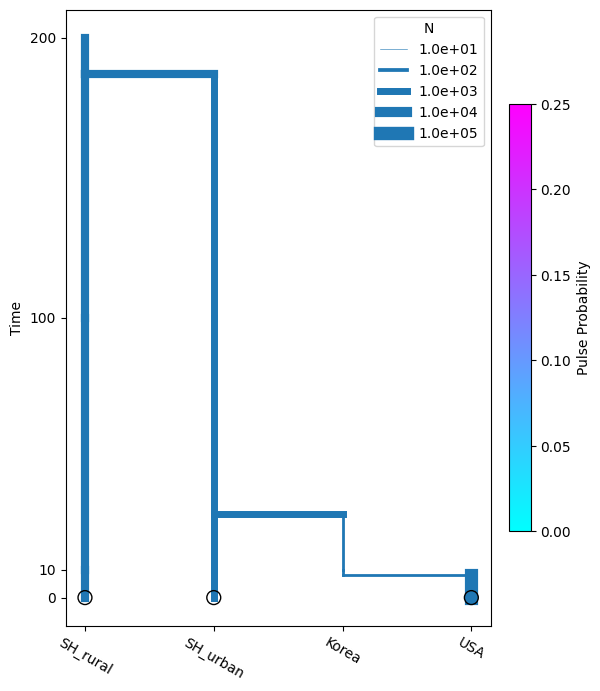

In [15]:
#plot
import matplotlib.pyplot as plt
import numpy as np

# Create your demographic plot
yticks = [0, 1e1, 1e2,200]
fig = momi.DemographyPlot(
    model1, ["SH_rural", "SH_urban","Korea", "USA"],
    figsize=(6,8),
    pulse_color_bounds=(0,0.25),
    major_yticks=yticks,draw=False)

fig.draw()
fig.draw_N_legend(N_legend_values=[10,100,1000, 1e4, 1e5])
#Save the plot
png = "example_momi_model1.pdf"
plt.savefig(png)
plt.show()

In [8]:
bootstrap_resultsA=[ ({'t_usa_split': 8.00016354767451, 't_korea_split': 29.9735709344461, 't_urban_split': 188.039093453258, 'N_rural': 2345.52400669118, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 805.371911066435, 'N_korea_founder': 49.7048775731328, 'N_usa_founder': 393.915900336434}),
 ({'t_usa_split': 19.9536731752741, 't_korea_split': 29.7208242977369, 't_urban_split': 202.266245823587, 'N_rural': 2592.30821537163, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 692.936507855935, 'N_korea_founder': 22.6308865032586, 'N_usa_founder': 851.588770272096}),
 ({'t_usa_split': 8.00000000000925, 't_korea_split': 29.9999030747546, 't_urban_split': 188.594718418986, 'N_rural': 2380.5489080712, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 830.7509574014, 'N_korea_founder': 49.7763172253852, 'N_usa_founder': 403.093860543436}),
 ({'t_usa_split': 8.02061150051027, 't_korea_split': 29.8761702476436, 't_urban_split': 188.126575278046, 'N_rural': 2346.11609572645, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 105.772655555142, 'N_korea_founder': 47.4501377207267, 'N_usa_founder': 693.553448471332}),
 ({'t_usa_split': 8.00016075922128, 't_korea_split': 29.9999997024825, 't_urban_split': 186.938917962231, 'N_rural': 2304.94000553057, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 304.393660017264, 'N_korea_founder': 50.0180779640324, 'N_usa_founder': 966.726899212454}),
 ({'t_usa_split': 8.01317186176212, 't_korea_split': 29.992182228618, 't_urban_split': 189.984188913102, 'N_rural': 2315.7597023964, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 174.767243526867, 'N_korea_founder': 48.5957836786416, 'N_usa_founder': 85.9135716784118}),
 ({'t_usa_split': 8.00000000003966, 't_korea_split': 29.9906858144213, 't_urban_split': 205.686299945991, 'N_rural': 2296.47962629677, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 575.586380500512, 'N_korea_founder': 49.3645625212451, 'N_usa_founder': 455.240636556171}),
 ({'t_usa_split': 8.00160417789255, 't_korea_split': 29.9718940329117, 't_urban_split': 191.977195168268, 'N_rural': 2381.18074055824, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 872.239545362323, 'N_korea_founder': 50.6888888120067, 'N_usa_founder': 696.558458530195}),
 ({'t_usa_split': 8.0006607682591, 't_korea_split': 29.9663807692421, 't_urban_split': 193.694374982949, 'N_rural': 2368.93986775912, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 921.629816296083, 'N_korea_founder': 47.1290069116363, 'N_usa_founder': 942.167748909326}),
 ({'t_usa_split': 8.89546915739591, 't_korea_split': 28.2919560352558, 't_urban_split': 183.749904985065, 'N_rural': 2410.72077665824, 'N_urban': 1000, 'N_usa': 7196.70001182673, 'N_urban_founder': 903.182485012102, 'N_korea_founder': 42.7559677155974, 'N_usa_founder': 654.413365883874}),
 ({'t_usa_split': 8.00573450547561, 't_korea_split': 29.9883463420754, 't_urban_split': 188.276494887577, 'N_rural': 2398.27530137671, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 121.187369142012, 'N_korea_founder': 47.7785516037359, 'N_usa_founder': 678.019099476654}),
 ({'t_usa_split': 8.00000278149989, 't_korea_split': 29.9714915264494, 't_urban_split': 188.466173812983, 'N_rural': 2327.74314922318, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 236.4465638275, 'N_korea_founder': 48.5146073278237, 'N_usa_founder': 182.055679979781}),
 ({'t_usa_split': 8.00000314772618, 't_korea_split': 29.9638642320045, 't_urban_split': 197.71548145949, 'N_rural': 2292.25338067647, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 74.7224609284377, 'N_korea_founder': 49.6902270119617, 'N_usa_founder': 74.9921322390225}),
 ({'t_usa_split': 8.00422966034219, 't_korea_split': 29.9748616872603, 't_urban_split': 189.910180549283, 'N_rural': 2290.93800039113, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 225.955326475598, 'N_korea_founder': 49.0064059773531, 'N_usa_founder': 75.6520730442386}),
 ({'t_usa_split': 8.00260049659276, 't_korea_split': 29.9860357688589, 't_urban_split': 202.047435813411, 'N_rural': 2319.80620967917, 'N_urban': 1000, 'N_usa': 33244.7395766253, 'N_urban_founder': 64.6112403798322, 'N_korea_founder': 48.1570037598458, 'N_usa_founder': 983.029669228712}),
 ({'t_usa_split': 8.00000000000411, 't_korea_split': 29.999999698332, 't_urban_split': 192.667998949634, 'N_rural': 2354.40130614066, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 513.318565033204, 'N_korea_founder': 50.5787012008797, 'N_usa_founder': 158.743922067633}),
 ({'t_usa_split': 8.00112432085676, 't_korea_split': 29.6241804246495, 't_urban_split': 190.643120244652, 'N_rural': 2277.37982514833, 'N_urban': 1000, 'N_usa': 1087.88037001908, 'N_urban_founder': 726.556723366502, 'N_korea_founder': 50.9804709074513, 'N_usa_founder': 174.869275614036}),
 ({'t_usa_split': 8.00535049190299, 't_korea_split': 29.9950360299129, 't_urban_split': 194.135690662302, 'N_rural': 2312.44681300291, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 750.011214589516, 'N_korea_founder': 48.7974059944161, 'N_usa_founder': 205.004581135796}),
 ({'t_usa_split': 8.00005902745523, 't_korea_split': 29.9695556744337, 't_urban_split': 195.541754484072, 'N_rural': 2407.92565542264, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 895.284406508031, 'N_korea_founder': 49.1711394862068, 'N_usa_founder': 869.961582339641}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999993742255, 't_urban_split': 196.000261517373, 'N_rural': 2320.53846905906, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 391.397228013132, 'N_korea_founder': 48.0668100078112, 'N_usa_founder': 609.230754099418}),
 ({'t_usa_split': 12.7703384446245, 't_korea_split': 29.3793993553278, 't_urban_split': 140.487555855726, 'N_rural': 2081.67082887691, 'N_urban': 1000, 'N_usa': 5203.83956857349, 'N_urban_founder': 161.984303994822, 'N_korea_founder': 38.4430697187936, 'N_usa_founder': 749.465285474708}),
 ({'t_usa_split': 8.0000003800287, 't_korea_split': 30, 't_urban_split': 190.178961423029, 'N_rural': 2307.48793507039, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 816.381787471807, 'N_korea_founder': 47.9305867514662, 'N_usa_founder': 880.442180747666}),
 ({'t_usa_split': 19.1722954559638, 't_korea_split': 27.8990760700413, 't_urban_split': 181.541588974254, 'N_rural': 2506.60099303547, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 364.796196664742, 'N_korea_founder': 21.0606581361403, 'N_usa_founder': 760.995285849292}),
 ({'t_usa_split': 8.00002928103337, 't_korea_split': 29.9572130304603, 't_urban_split': 181.534235413174, 'N_rural': 2342.6891507335, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 947.140232834111, 'N_korea_founder': 48.9765949142651, 'N_usa_founder': 613.076569763623}),
 ({'t_usa_split': 8.0000004356747, 't_korea_split': 29.9989634173826, 't_urban_split': 193.458970540607, 'N_rural': 2300.66771897462, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 453.266496038288, 'N_korea_founder': 47.8634905186378, 'N_usa_founder': 821.307868802164}),
 ({'t_usa_split': 8.00000005984532, 't_korea_split': 29.9856425739071, 't_urban_split': 196.597000793341, 'N_rural': 2344.98878896359, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 902.742764519243, 'N_korea_founder': 48.2299255656081, 'N_usa_founder': 666.391717605488}),
 ({'t_usa_split': 8.00091065927525, 't_korea_split': 29.8660740973087, 't_urban_split': 180.713893326965, 'N_rural': 2342.37097059081, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 268.568980168048, 'N_korea_founder': 50.5393129540386, 'N_usa_founder': 69.1099487348695}),
 ({'t_usa_split': 8.00661584367523, 't_korea_split': 29.6556236262322, 't_urban_split': 206.034181676651, 'N_rural': 2360.11605088099, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 533.298744808882, 'N_korea_founder': 47.6342097620235, 'N_usa_founder': 694.741377646302}),
 ({'t_usa_split': 8.00005635517556, 't_korea_split': 29.8538200293603, 't_urban_split': 191.207833726284, 'N_rural': 2368.95498474231, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 444.180194104447, 'N_korea_founder': 46.5481710663675, 'N_usa_founder': 424.816706811276}),
 ({'t_usa_split': 8.00000006308263, 't_korea_split': 29.9895662647376, 't_urban_split': 191.986700158984, 'N_rural': 2333.06704141266, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 601.858623110941, 'N_korea_founder': 48.6139990152303, 'N_usa_founder': 832.976511977217}),
 ({'t_usa_split': 8.00876985220833, 't_korea_split': 29.9828327818751, 't_urban_split': 198.746082062533, 'N_rural': 2336.6588644567, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 196.874715613692, 'N_korea_founder': 49.0934692831602, 'N_usa_founder': 176.797015815337}),
 ({'t_usa_split': 8.00000211620611, 't_korea_split': 29.8811068633779, 't_urban_split': 186.10681241346, 'N_rural': 2315.14696529491, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 275.011430593981, 'N_korea_founder': 48.3687773597604, 'N_usa_founder': 961.942950223167}),
 ({'t_usa_split': 8.2517546299579, 't_korea_split': 29.8829754251153, 't_urban_split': 194.374401860583, 'N_rural': 2326.98389173322, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 183.681613570019, 'N_korea_founder': 48.4429706875382, 'N_usa_founder': 568.687255830533}),
 ({'t_usa_split': 8.00107874953141, 't_korea_split': 29.9665228829343, 't_urban_split': 188.566460569012, 'N_rural': 2375.63706168892, 'N_urban': 1000, 'N_usa': 18578.8082107265, 'N_urban_founder': 138.502611913143, 'N_korea_founder': 47.589564404481, 'N_usa_founder': 863.987834310514}),
 ({'t_usa_split': 8.00021086590538, 't_korea_split': 29.8858657693446, 't_urban_split': 191.70289489701, 'N_rural': 2433.84380000844, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 504.273177305169, 'N_korea_founder': 49.5133707005904, 'N_usa_founder': 285.050174412023}),
 ({'t_usa_split': 8.00595600288493, 't_korea_split': 29.9776040472696, 't_urban_split': 192.496543536768, 'N_rural': 2335.2989361781, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 854.903301634702, 'N_korea_founder': 47.8345648347341, 'N_usa_founder': 687.18166575336}),
 ({'t_usa_split': 8.00002651349119, 't_korea_split': 29.9768515619843, 't_urban_split': 188.544634616401, 'N_rural': 2287.70971223028, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 823.037536234119, 'N_korea_founder': 49.1762575084895, 'N_usa_founder': 469.869153358601}),
 ({'t_usa_split': 8.00131089240052, 't_korea_split': 29.9697804596841, 't_urban_split': 189.816262057242, 'N_rural': 2304.14741013251, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 103.204987440286, 'N_korea_founder': 49.4140437285699, 'N_usa_founder': 591.525809686003}),
 ({'t_usa_split': 8.00204598514267, 't_korea_split': 29.96564346439, 't_urban_split': 168.323316403098, 'N_rural': 2177.50551124074, 'N_urban': 1000, 'N_usa': 1961.75239219783, 'N_urban_founder': 87.187445921511, 'N_korea_founder': 49.3074542885306, 'N_usa_founder': 173.287713341582}),
 ({'t_usa_split': 8.00002434572202, 't_korea_split': 29.8841818515034, 't_urban_split': 181.719880682658, 'N_rural': 2317.30216876333, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 378.071235238774, 'N_korea_founder': 48.6960665987475, 'N_usa_founder': 831.223759721408}),
 ({'t_usa_split': 8.01009138462248, 't_korea_split': 29.7663337369844, 't_urban_split': 203.720618408716, 'N_rural': 2357.77517864175, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 321.983391944536, 'N_korea_founder': 47.3880522488371, 'N_usa_founder': 125.545289944336}),
 ({'t_usa_split': 8.00000348661757, 't_korea_split': 29.9716396203074, 't_urban_split': 196.283876162925, 'N_rural': 2375.89937354575, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 462.175896422891, 'N_korea_founder': 49.2428438377331, 'N_usa_founder': 181.271012967458}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999599127142, 't_urban_split': 175.460577894696, 'N_rural': 2343.14162137965, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 508.272908016734, 'N_korea_founder': 49.1377189808045, 'N_usa_founder': 179.600297766588}),
 ({'t_usa_split': 8.00000000000006, 't_korea_split': 29.9999999999917, 't_urban_split': 188.632019486604, 'N_rural': 2316.04583060918, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 968.905986457806, 'N_korea_founder': 49.6436551070363, 'N_usa_founder': 592.956919823723}),
 ({'t_usa_split': 8.0032984458295, 't_korea_split': 29.9898791276661, 't_urban_split': 193.311423097586, 'N_rural': 2224.36092163714, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 413.276910917983, 'N_korea_founder': 47.7427347291423, 'N_usa_founder': 404.837684888242}),
 ({'t_usa_split': 8.00001062890928, 't_korea_split': 29.7230165740397, 't_urban_split': 196.955196479686, 'N_rural': 2293.23837696258, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 741.840971487621, 'N_korea_founder': 49.7335339529857, 'N_usa_founder': 862.722963515981}),
 ({'t_usa_split': 8.00000322904462, 't_korea_split': 29.9999999997788, 't_urban_split': 199.331086988416, 'N_rural': 2255.94437863573, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 839.845147250431, 'N_korea_founder': 49.7880735339154, 'N_usa_founder': 679.701131082684}),
 ({'t_usa_split': 8.00099246224193, 't_korea_split': 29.9653726953296, 't_urban_split': 191.05967635266, 'N_rural': 2358.52081604316, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 452.617464634721, 'N_korea_founder': 48.2467447649728, 'N_usa_founder': 420.698804535688}),
 ({'t_usa_split': 8.00002738761766, 't_korea_split': 29.9425540165942, 't_urban_split': 186.002407431532, 'N_rural': 2347.8691947595, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 686.757993366876, 'N_korea_founder': 47.6357823843911, 'N_usa_founder': 473.39819292179}),
 ({'t_usa_split': 8.02519448025094, 't_korea_split': 29.848676429643, 't_urban_split': 184.093229098335, 'N_rural': 2380.48134148167, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 701.241295614305, 'N_korea_founder': 48.3097847136857, 'N_usa_founder': 175.33272243406}),
 ({'t_usa_split': 19.8475106720092, 't_korea_split': 27.7380817927101, 't_urban_split': 198.717567804337, 'N_rural': 2269.99502614595, 'N_urban': 1061.22361514548, 'N_usa': 1000, 'N_urban_founder': 278.709326739552, 'N_korea_founder': 21.2712080867926, 'N_usa_founder': 233.344126146074}),
 ({'t_usa_split': 8.00600158343109, 't_korea_split': 29.7588493852609, 't_urban_split': 190.861825836005, 'N_rural': 2308.35631600515, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 62.3866127984916, 'N_korea_founder': 48.9084879256064, 'N_usa_founder': 580.086285667}),
 ({'t_usa_split': 8.04023325119959, 't_korea_split': 29.5480686601191, 't_urban_split': 173.45723226505, 'N_rural': 2261.95913209361, 'N_urban': 1000, 'N_usa': 1062.19897526444, 'N_urban_founder': 172.314576565922, 'N_korea_founder': 50.7778108291428, 'N_usa_founder': 315.116392604583}),
 ({'t_usa_split': 8.00171688727541, 't_korea_split': 29.8294078502842, 't_urban_split': 203.705148499468, 'N_rural': 2338.4814143038, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 371.026221034418, 'N_korea_founder': 48.687921415692, 'N_usa_founder': 518.452895598762}),
 ({'t_usa_split': 8.00275032533743, 't_korea_split': 29.4916805593301, 't_urban_split': 184.568732620229, 'N_rural': 2343.20803036627, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 629.568194146698, 'N_korea_founder': 47.1257292965131, 'N_usa_founder': 805.299665919555}),
 ({'t_usa_split': 8.00020907755113, 't_korea_split': 29.9644943125769, 't_urban_split': 193.472338203071, 'N_rural': 2325.18182587329, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 736.674282792948, 'N_korea_founder': 48.1429870075301, 'N_usa_founder': 313.631300226432}),
 ({'t_usa_split': 8.00029495936504, 't_korea_split': 29.9979904528991, 't_urban_split': 187.312192741788, 'N_rural': 2286.02003668898, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 889.789324741353, 'N_korea_founder': 49.6117775740437, 'N_usa_founder': 327.935892482463}),
 ({'t_usa_split': 8.00000026834309, 't_korea_split': 29.9782902302947, 't_urban_split': 197.50225031683, 'N_rural': 2335.25904576435, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 495.853918284344, 'N_korea_founder': 48.0125220816264, 'N_usa_founder': 722.127025042112}),
 ({'t_usa_split': 8.0000005211918, 't_korea_split': 29.9785210164602, 't_urban_split': 186.404630503717, 'N_rural': 2294.93546843224, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 795.573286233611, 'N_korea_founder': 50.2290122655116, 'N_usa_founder': 474.558434297625}),
 ({'t_usa_split': 8.00102999172898, 't_korea_split': 29.9989233500782, 't_urban_split': 183.469354032219, 'N_rural': 2332.92176179209, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 701.790410329236, 'N_korea_founder': 47.991023395759, 'N_usa_founder': 44.392711632691}),
 ({'t_usa_split': 8.017086446027, 't_korea_split': 29.9904974187855, 't_urban_split': 182.567787217607, 'N_rural': 2317.27588716188, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 663.658895065193, 'N_korea_founder': 49.9660407482116, 'N_usa_founder': 479.351649650799}),
 ({'t_usa_split': 8.03306671434781, 't_korea_split': 29.9696101746581, 't_urban_split': 184.747413639203, 'N_rural': 2345.5765714743, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 827.916657812564, 'N_korea_founder': 48.9230680509707, 'N_usa_founder': 620.602403837603}),
 ({'t_usa_split': 8.0007712439797, 't_korea_split': 29.7322088754745, 't_urban_split': 194.405970465538, 'N_rural': 2492.92486901457, 'N_urban': 1000, 'N_usa': 6906.19251267509, 'N_urban_founder': 507.275267364176, 'N_korea_founder': 46.8499071382905, 'N_usa_founder': 686.595235702132}),
 ({'t_usa_split': 8.00141297509935, 't_korea_split': 29.9767948431454, 't_urban_split': 202.051574304794, 'N_rural': 2338.03892645324, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 397.893163300023, 'N_korea_founder': 48.5100293682857, 'N_usa_founder': 414.809766350615}),
 ({'t_usa_split': 8.06124236280472, 't_korea_split': 29.9502207891563, 't_urban_split': 196.672857372506, 'N_rural': 2257.48793245058, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 544.81900906823, 'N_korea_founder': 48.15807564921, 'N_usa_founder': 55.1758621984867}),
 ({'t_usa_split': 8.00892611187913, 't_korea_split': 29.9999999990217, 't_urban_split': 196.519884617517, 'N_rural': 2326.86990013101, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 952.380059840403, 'N_korea_founder': 48.587756857674, 'N_usa_founder': 919.473673406208}),
 ({'t_usa_split': 19.8997999467615, 't_korea_split': 28.9032732371611, 't_urban_split': 202.043384424667, 'N_rural': 2533.99181913687, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 685.81377313486, 'N_korea_founder': 20.6675964497761, 'N_usa_founder': 821.008241078282}),
 ({'t_usa_split': 8.00000205414257, 't_korea_split': 29.9677456329026, 't_urban_split': 193.220480636316, 'N_rural': 2324.6987754431, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 827.979663093809, 'N_korea_founder': 49.3623365775681, 'N_usa_founder': 601.689701728957}),
 ({'t_usa_split': 8.00076070538685, 't_korea_split': 29.9687272136025, 't_urban_split': 179.703101914291, 'N_rural': 2405.8023606736, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 687.729041818175, 'N_korea_founder': 50.0873329603281, 'N_usa_founder': 229.883701332368}),
 ({'t_usa_split': 8.04074295901196, 't_korea_split': 29.9978135389943, 't_urban_split': 192.174946613908, 'N_rural': 2318.22939386697, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 469.785262373731, 'N_korea_founder': 48.6035174444488, 'N_usa_founder': 37.5333517585109}),
 ({'t_usa_split': 8.00000000000009, 't_korea_split': 29.9680086840985, 't_urban_split': 188.436341551353, 'N_rural': 2362.30866958956, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 651.441633071329, 'N_korea_founder': 47.9246141410944, 'N_usa_founder': 506.248888848994}),
 ({'t_usa_split': 18.7157204291415, 't_korea_split': 27.9085106639532, 't_urban_split': 184.686100214926, 'N_rural': 2536.63259446033, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 895.251438469988, 'N_korea_founder': 21.5341713657637, 'N_usa_founder': 959.517980624284}),
 ({'t_usa_split': 8.00002686544799, 't_korea_split': 29.982259682035, 't_urban_split': 186.087306819332, 'N_rural': 2325.39298468039, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 806.225704278409, 'N_korea_founder': 47.1115201186392, 'N_usa_founder': 165.363210467952}),
 ({'t_usa_split': 8.00265862688791, 't_korea_split': 29.981667023951, 't_urban_split': 179.396167050864, 'N_rural': 2339.70298613643, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 334.287786535762, 'N_korea_founder': 50.0686565223535, 'N_usa_founder': 358.689234279453}),
 ({'t_usa_split': 8.00098014392544, 't_korea_split': 29.8573585711855, 't_urban_split': 190.289550114784, 'N_rural': 2328.34645073336, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 270.26320777173, 'N_korea_founder': 48.5476793639413, 'N_usa_founder': 477.919243235885}),
 ({'t_usa_split': 8.00143670386326, 't_korea_split': 29.4748828296241, 't_urban_split': 187.487406476146, 'N_rural': 2395.79155555693, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 399.131891624889, 'N_korea_founder': 47.9021197227864, 'N_usa_founder': 960.160146017473}),
 ({'t_usa_split': 8.00006259518865, 't_korea_split': 29.9527281286673, 't_urban_split': 196.453093659934, 'N_rural': 2345.35524494592, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 771.585248474912, 'N_korea_founder': 48.6444186162749, 'N_usa_founder': 556.389670718275}),
 ({'t_usa_split': 8.00219477057448, 't_korea_split': 29.9681157330195, 't_urban_split': 185.749930401087, 'N_rural': 2377.66481391192, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 494.090231519995, 'N_korea_founder': 49.2920449201813, 'N_usa_founder': 343.981511394786}),
 ({'t_usa_split': 8.00142707805722, 't_korea_split': 29.9842458967001, 't_urban_split': 196.882344542416, 'N_rural': 2353.47650919544, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 51.4691657123598, 'N_korea_founder': 48.2656784771557, 'N_usa_founder': 767.468321452179}),
 ({'t_usa_split': 8.00882584667902, 't_korea_split': 30, 't_urban_split': 188.438452184513, 'N_rural': 2297.30739054467, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 135.814681884878, 'N_korea_founder': 49.2949225922646, 'N_usa_founder': 772.686985645439}),
 ({'t_usa_split': 8.00008698563465, 't_korea_split': 29.9761665314256, 't_urban_split': 194.462956894431, 'N_rural': 2319.60235252827, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 344.952384972341, 'N_korea_founder': 47.4845376353887, 'N_usa_founder': 749.963921584994}),
 ({'t_usa_split': 8.00625937867145, 't_korea_split': 29.849835139617, 't_urban_split': 195.097822731794, 'N_rural': 2323.86109276445, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 515.66009232869, 'N_korea_founder': 47.2587248234862, 'N_usa_founder': 570.497662196575}),
 ({'t_usa_split': 8.00005386824857, 't_korea_split': 29.9663554363342, 't_urban_split': 198.673050967805, 'N_rural': 2245.75964482779, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 416.733273024965, 'N_korea_founder': 50.5309810976765, 'N_usa_founder': 30.4255727540877}),
 ({'t_usa_split': 8.00235527868154, 't_korea_split': 29.9590156568667, 't_urban_split': 175.54757341202, 'N_rural': 2399.12882553038, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 706.169853282723, 'N_korea_founder': 49.5829417463698, 'N_usa_founder': 53.9652833708331}),
 ({'t_usa_split': 8.03755883216162, 't_korea_split': 29.2089249302764, 't_urban_split': 180.182539684869, 'N_rural': 2410.02444251555, 'N_urban': 1000, 'N_usa': 1106.32910559118, 'N_urban_founder': 172.359116900794, 'N_korea_founder': 47.7177847412631, 'N_usa_founder': 316.945404793036}),
 ({'t_usa_split': 8.00000334806612, 't_korea_split': 29.9692973985633, 't_urban_split': 185.69836523157, 'N_rural': 2336.24594461444, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 439.592001572276, 'N_korea_founder': 48.7200859555587, 'N_usa_founder': 463.620083534312}),
 ({'t_usa_split': 20, 't_korea_split': 29.9734867660541, 't_urban_split': 190.762231368233, 'N_rural': 2491.81988418198, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 165.930638931656, 'N_korea_founder': 23.03925326919, 'N_usa_founder': 486.658168536524}),
 ({'t_usa_split': 10.1458022504946, 't_korea_split': 28.0833736957278, 't_urban_split': 197.6822515943, 'N_rural': 2542.36108833176, 'N_urban': 1030.16409566204, 'N_usa': 17624.3711546886, 'N_urban_founder': 355.986266403306, 'N_korea_founder': 39.1666694913841, 'N_usa_founder': 155.155684648844}),
 ({'t_usa_split': 8.00001242678984, 't_korea_split': 29.9965493326334, 't_urban_split': 202.499312802432, 'N_rural': 2287.62526008489, 'N_urban': 1000, 'N_usa': 29422.1120313432, 'N_urban_founder': 97.1875224049055, 'N_korea_founder': 46.4927112327666, 'N_usa_founder': 872.973715943092}),
 ({'t_usa_split': 9.59387830739787, 't_korea_split': 24.9798983029253, 't_urban_split': 193.079080650435, 'N_rural': 1992.07668728094, 'N_urban': 1133.5542863196, 'N_usa': 17592.4365104515, 'N_urban_founder': 393.479866631407, 'N_korea_founder': 32.7900021903517, 'N_usa_founder': 846.42029836122}),
 ({'t_usa_split': 8.00026175468732, 't_korea_split': 29.9714407383835, 't_urban_split': 182.270047647804, 'N_rural': 2341.80251139404, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 187.999136293214, 'N_korea_founder': 50.887485312983, 'N_usa_founder': 467.435442857623}),
 ({'t_usa_split': 8.00013651470963, 't_korea_split': 29.9564507673033, 't_urban_split': 197.911109152485, 'N_rural': 2369.44404691952, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 401.318032400594, 'N_korea_founder': 49.0921438063439, 'N_usa_founder': 777.254065999424}),
 ({'t_usa_split': 8.00005830745309, 't_korea_split': 29.9344095324992, 't_urban_split': 184.413634229732, 'N_rural': 2354.82850717659, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 868.492358634645, 'N_korea_founder': 48.4503519690093, 'N_usa_founder': 507.582651209459}),
 ({'t_usa_split': 8.01946523297796, 't_korea_split': 29.4936969295658, 't_urban_split': 187.639158773227, 'N_rural': 2344.37981794726, 'N_urban': 1000, 'N_usa': 1000, 'N_urban_founder': 206.220379991473, 'N_korea_founder': 46.6610362292059, 'N_usa_founder': 81.8556539842976}) ]
                    

/ext3/miniconda3/envs/momi2_env/lib/python3.10/site-packages/autograd/tracer.py:48: RuntimeWarning: divide by zero encountered in log
  return f_raw(*args, **kwargs)
/scratch/fm2371/packages/conda/momi2/momi/demo_model.py:254: RuntimeWarning: divide by zero encountered in scalar divide
  x = np.log(x/(1.-x))


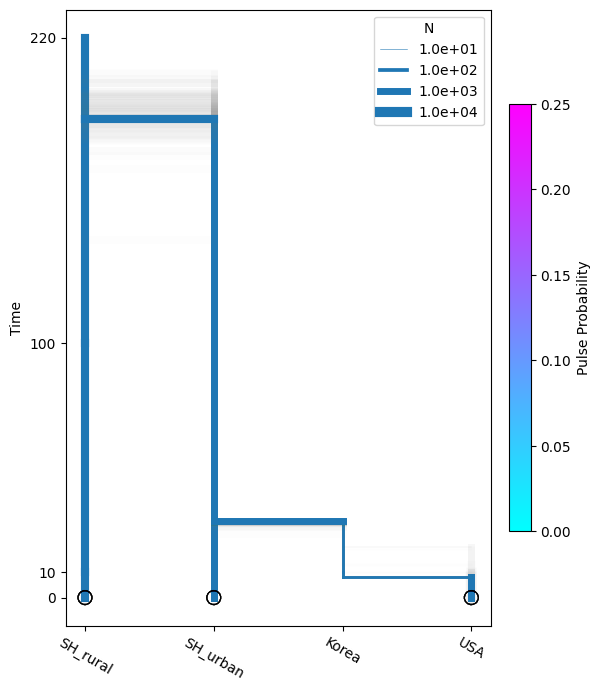

In [40]:
#plot
import matplotlib.pyplot as plt
import numpy as np

# Create your demographic plot
yticks = [0, 1e1, 1e2,220]
fig = momi.DemographyPlot(
    model1, ["SH_rural", "SH_urban","Korea", "USA"],
    figsize=(6,8),
    pulse_color_bounds=(0,0.25),
    major_yticks=yticks,draw=False)

# plot bootstraps onto the canvas in transparency
for params in bootstrap_resultsA:
    fig.add_bootstrap(
        params,
        # alpha=0: totally transparent. alpha=1: totally opaque
        alpha=1/n_bootstraps)
fig.draw()
fig.draw_N_legend(N_legend_values=[10,100,1000,10000])
#Save the plot
png = "momi_model1.pdf"
plt.savefig(png)
plt.show()

In [35]:
#Calculate confidence intervals from bootstrap results

bootstrap_df= pd.DataFrame(bootstrap_resultsA)

for param in bootstrap_df.columns:
    print(param,':',model1.get_params()[param],np.percentile(bootstrap_df[param],2.5), np.percentile(bootstrap_df[param],97.5))
    
print(len(bootstrap_df.columns))

t_usa_split : 8.000163547674514 8.000000000000071 19.882805932467004
t_korea_split : 29.9735709344461 27.90214231306267 29.999999999922508
t_urban_split : 188.03909345325752 174.10831959468496 203.7155906882104
N_rural : 2345.5240066911842 2192.73351961957 2535.7743424802056
N_urban : 999.9999999999999 1000.0 1020.3607645718769
N_usa : 999.9999999999999 1000.0 18268.61616751418
N_urban_founder : 805.371911066435 67.89738705812898 938.8493474592518
N_korea_founder : 49.70487757313281 21.35667115245821 50.74891117357357
N_usa_founder : 393.9159003364344 47.50379744758718 961.3635388563165
9


In [17]:
# model 2: Urban origin direct (Direct Invasion Model): SH_rural -> SH_urban -> USA
model2 = momi.DemographicModel(N_e=Ne, gen_time=gen_time, muts_per_gen=mu)
    
    # Add time parameters with chronological constraints
model2.add_time_param("t_usa_split", t0=10, lower=8, upper=20)       # USA invasion ~2014
model2.add_time_param("t_urban_split", t0=50, lower_constraints=["t_usa_split"], upper=1e6)  # Urbanization
    
    # Add contemporary population size parameters
model2.add_size_param("N_rural", lower=1e3, upper=1e7)     # Rural Shanghai current size
model2.add_size_param("N_urban", lower=1e3, upper=1e7)     # Urban Shanghai current size
model2.add_size_param("N_usa", lower=1e3, upper=1e7)       # USA current size
    
    # Add bottleneck size parameters
model2.add_size_param("N_urban_founder", lower=10, upper=1e3)  # Bottleneck during urbanization
model2.add_size_param("N_usa_founder", lower=10, upper=1e3)    # Bottleneck during USA invasion
    
    # Define contemporary populations 
model2.add_leaf("SH_rural", N="N_rural")
model2.add_leaf("SH_urban", N="N_urban")
model2.add_leaf("USA", N="N_usa")
    
    # Set the data
model2.set_data(sfs_all)
    
    # Define population splits - working BACKWARDS in time
    # First, USA split directly from SH_urban with a bottleneck
model2.set_size("USA", t="t_usa_split", N="N_usa_founder")
model2.move_lineages("USA", "SH_urban", t="t_usa_split")
    
    # Then, SH_urban split from SH_rural with a bottleneck
model2.set_size("SH_urban", t="t_urban_split", N="N_urban_founder")
model2.move_lineages("SH_urban", "SH_rural", t="t_urban_split")

model2.set_params({'t_usa_split': 8.201897101371568, 't_urban_split': 186.9565807211395, 'N_rural': 2390.8701888215187, 'N_urban': 999.9999999999999, 'N_usa': 1273041, 'N_urban_founder': 662.0395091916705, 'N_usa_founder': 405.5291009000506})


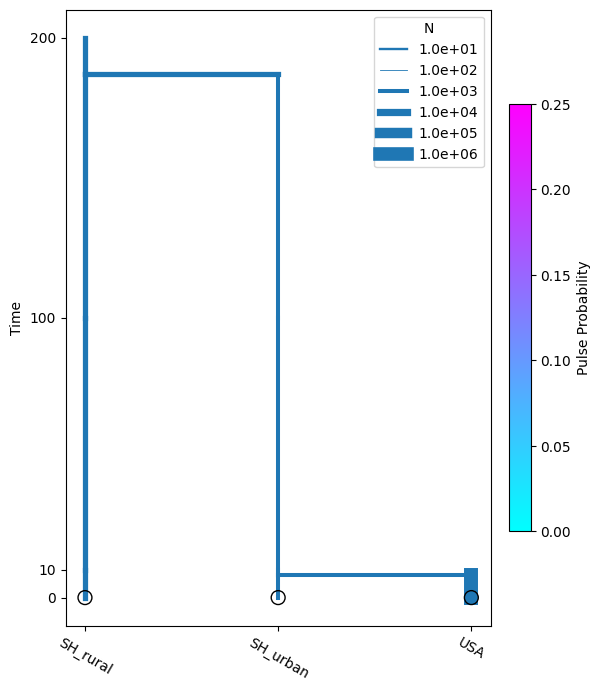

In [19]:
# Plot
import matplotlib.pyplot as plt
import numpy as np

yticks = [0, 1e1, 1e2,200]
fig = momi.DemographyPlot(
    model2, ["SH_rural", "SH_urban", "USA"],
    figsize=(6,8),
    pulse_color_bounds=(0,0.25),
    major_yticks=yticks, draw=False)
fig.draw()
fig.draw_N_legend(N_legend_values=[10, 100, 1000, 1e4, 1e5, 1e6])

# Save the plot
plt.savefig("example_model2_direct.pdf")
plt.show()

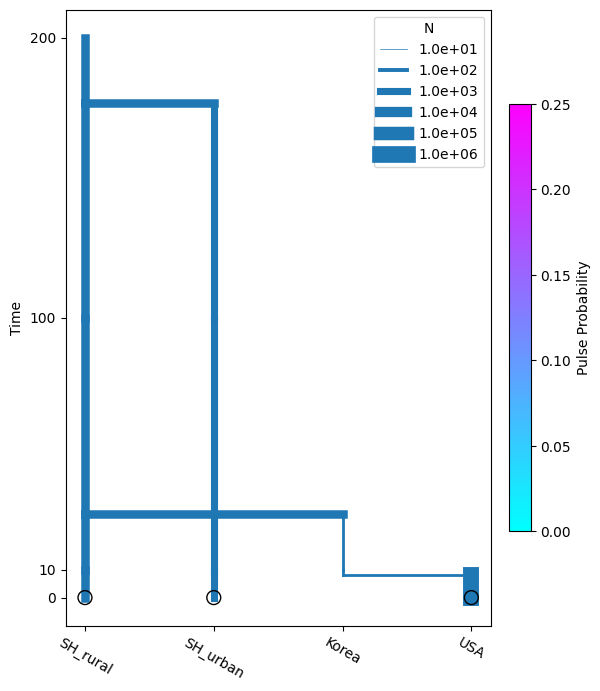

In [20]:
# Model 3: Rural Origin with Korea (Shanghai Rural → Korea → USA, Shanghai Rural → Shanghai Urban)
model3 = momi.DemographicModel(N_e=1.9e6, gen_time=1, muts_per_gen=2.8e-9)

# Add time parameters
model3.add_time_param("t_usa_split", t0=10, lower=8, upper=20)       # USA invasion ~2014
model3.add_time_param("t_korea_split", t0=16, lower_constraints=["t_usa_split"], upper=30)  # Korea invasion ~2006
model3.add_time_param("t_urban_split", t0=50, lower_constraints=["t_korea_split"], upper=1e6)    # Urbanization

# Add contemporary population size parameters
model3.add_size_param("N_rural", lower=1e3, upper=1e7)     # Rural Shanghai current size
model3.add_size_param("N_urban", lower=1e3, upper=1e7)     # Urban Shanghai current size
model3.add_size_param("N_usa", lower=1e3, upper=1e7)       # USA current size

# Add bottleneck size parameters
model3.add_size_param("N_urban_founder", lower=10, upper=1e3)  # Bottleneck during urbanization
model3.add_size_param("N_korea_founder", lower=10, upper=1e3)  # Bottleneck during Korea invasion
model3.add_size_param("N_usa_founder", lower=10, upper=1e3)    # Bottleneck during USA invasion

# Define contemporary populations 
model3.add_leaf("SH_rural", N="N_rural")
model3.add_leaf("SH_urban", N="N_urban")
model3.add_leaf("USA", N="N_usa")

# Set the data
model3.set_data(sfs_all)

# Define population splits - working BACKWARDS in time
# USA split from Korea with a bottleneck
model3.set_size("USA", t="t_usa_split", N="N_usa_founder")
model3.move_lineages("USA", "Korea", t="t_usa_split")  # Korea implicitly created as ghost

# Set properties of the ghost Korea population
model3.set_size("Korea", t=0, N="N_korea_founder")

# Korea split from SH_rural (rather than urban as in model 1)
model3.move_lineages("Korea", "SH_rural", t="t_korea_split")

# SH_urban split from SH_rural (independently of Korea/USA)
model3.set_size("SH_urban", t="t_urban_split", N="N_urban_founder")
model3.move_lineages("SH_urban", "SH_rural", t="t_urban_split")

model3.set_params({'t_usa_split': 8.000004876824526, 't_korea_split': 29.948651651946474, 't_urban_split': 176.5672654791289, 'N_rural': 2768.8161756891864, 'N_urban': 999.9999999999999, 'N_usa': 567917.1027323146, 'N_urban_founder': 925.9940055032482, 'N_korea_founder': 44.71357427802222, 'N_usa_founder': 384.02986176214097})

# Plot
import matplotlib.pyplot as plt
import numpy as np

yticks = [0, 1e1, 1e2, 200]
fig = momi.DemographyPlot(
    model3, ["SH_rural", "SH_urban", "Korea", "USA"],
    figsize=(6,8),
    pulse_color_bounds=(0,0.25),
    major_yticks=yticks, draw=False)
fig.draw()
fig.draw_N_legend(N_legend_values=[10, 100, 1000, 1e4, 1e5, 1e6])

# Save the plot
plt.savefig("example_model3_rural_korea.pdf")
plt.show()

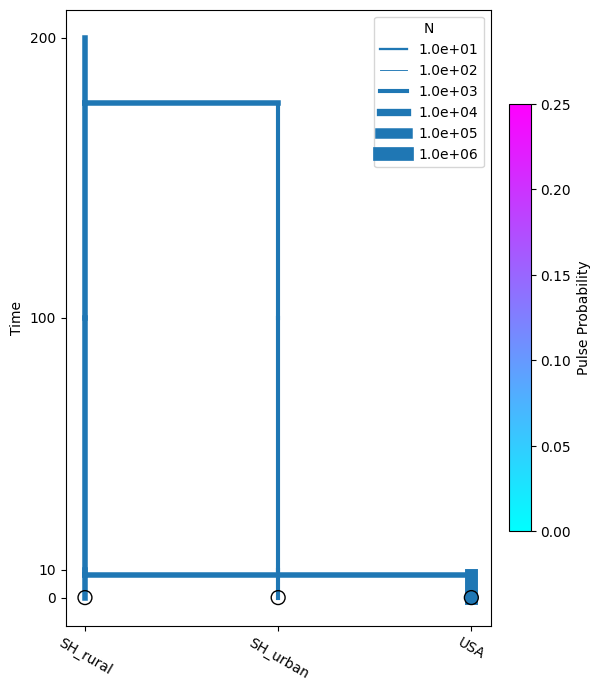

In [24]:
# Model 4: Rural Origin with Direct Paths (Shanghai Rural → USA, Shanghai Rural → Shanghai Urban)
model4 = momi.DemographicModel(N_e=1.9e6, gen_time=1, muts_per_gen=2.8e-9)

# Add time parameters
model4.add_time_param("t_usa_split", t0=10, lower=8, upper=20)       # USA invasion ~2014
model4.add_time_param("t_urban_split", t0=50, lower_constraints=["t_usa_split"], upper=1e6)    # Urbanization

# Add contemporary population size parameters
model4.add_size_param("N_rural", lower=1e3, upper=1e7)     # Rural Shanghai current size
model4.add_size_param("N_urban", lower=1e3, upper=1e7)     # Urban Shanghai current size
model4.add_size_param("N_usa", lower=1e3, upper=1e7)       # USA current size

# Add bottleneck size parameters
model4.add_size_param("N_urban_founder", lower=10, upper=1e3)  # Bottleneck during urbanization
model4.add_size_param("N_usa_founder", lower=10, upper=1e3)    # Bottleneck during USA invasion

# Define contemporary populations 
model4.add_leaf("SH_rural", N="N_rural")
model4.add_leaf("SH_urban", N="N_urban")
model4.add_leaf("USA", N="N_usa")

# Set the data
model4.set_data(sfs_all)

# Define population splits - working BACKWARDS in time
# USA split directly from SH_rural with a bottleneck
model4.set_size("USA", t="t_usa_split", N="N_usa_founder")
model4.move_lineages("USA", "SH_rural", t="t_usa_split")

# SH_urban split from SH_rural with a bottleneck (independently of USA split)
model4.set_size("SH_urban", t="t_urban_split", N="N_urban_founder")
model4.move_lineages("SH_urban", "SH_rural", t="t_urban_split")

model4.set_params({'t_usa_split': 8.000004876824526, 't_urban_split': 176.5672654791289, 'N_rural': 2768.8161756891864, 'N_urban': 999.9999999999999, 'N_usa': 567917.1027323146, 'N_urban_founder': 925.9940055032482, 'N_usa_founder': 384.02986176214097})

# Plot
import matplotlib.pyplot as plt
import numpy as np

yticks = [0, 1e1, 1e2, 200]
fig = momi.DemographyPlot(
    model4, ["SH_rural", "SH_urban", "USA"],
    figsize=(6,8),
    pulse_color_bounds=(0,0.25),
    major_yticks=yticks, draw=False)
fig.draw()
fig.draw_N_legend(N_legend_values=[10, 100, 1000, 1e4, 1e5, 1e6])

# Save the plot
plt.savefig("example_model4_rural_direct.pdf")
plt.show()

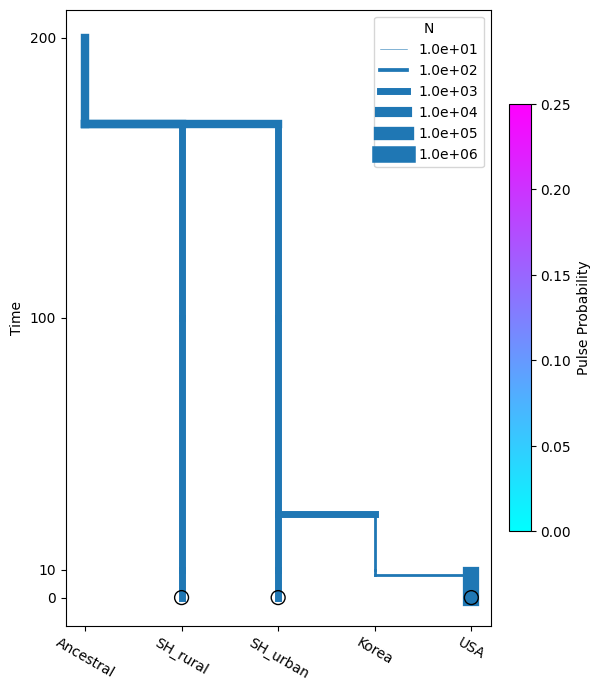

In [5]:
# Model 5: Independent Urban with Korea (SH_rural and SH_urban parallel, SH_urban -> Korea -> USA)

model5 = momi.DemographicModel(N_e=1e4, gen_time=1, muts_per_gen=2.8e-9)
    
    # Add time parameters with chronological constraints
model5.add_time_param("t_usa_split", t0=10, lower=8, upper=20)       # USA invasion ~2014
model5.add_time_param("t_korea_split", t0=16, lower_constraints=["t_usa_split"], upper=30)  # Korea invasion ~2006
model5.add_time_param("t_rural_urban_split", t0=50, lower_constraints=["t_korea_split"], upper=1e6)  # Ancient split between rural/urban
    
    # Add contemporary population size parameters
model5.add_size_param("N_rural", lower=1e3, upper=1e7)     # Rural Shanghai current size
model5.add_size_param("N_urban", lower=1e3, upper=1e7)     # Urban Shanghai current size
model5.add_size_param("N_usa", lower=1e3, upper=1e7)       # USA current size
model5.add_size_param("N_ancestral", lower=1e3, upper=1e7)  # Ancestral population size
    
    # Add bottleneck size parameters
model5.add_size_param("N_korea_founder", lower=10, upper=1e3)  # Bottleneck during Korea invasion
model5.add_size_param("N_usa_founder", lower=10, upper=1e3)    # Bottleneck during USA invasion
    
    # Define contemporary populations 
model5.add_leaf("SH_rural", N="N_rural")
model5.add_leaf("SH_urban", N="N_urban")
model5.add_leaf("USA", N="N_usa")
    
    # Set the data
model5.set_data(sfs_all)
    
    # Define population splits - working BACKWARDS in time
    # First, USA split from Korea with a bottleneck
model5.set_size("USA", t="t_usa_split", N="N_usa_founder")
model5.move_lineages("USA", "Korea", t="t_usa_split")  # Korea implicitly created as ghost
    
    # Set properties of the ghost Korea population
model5.set_size("Korea", t=0, N="N_korea_founder")  # Small founder population for Korea
    
    # Then, Korea split from SH_urban
model5.move_lineages("Korea", "SH_urban", t="t_korea_split")
    
    # Finally, SH_urban and SH_rural merge in ancestral population
model5.move_lineages("SH_urban", "Ancestral", t="t_rural_urban_split")  # Create ancestral ghost population
model5.move_lineages("SH_rural", "Ancestral", t="t_rural_urban_split")
model5.set_size("Ancestral", t=0, N="N_ancestral")

model5.set_params({'t_usa_split': 8.000163547674514, 't_korea_split': 29.9735709344461, 't_rural_urban_split': 169.1124664127677, 'N_rural': 999.9999999999999, 'N_urban': 999.9999999999999, 'N_usa': 817878.9800044751, 'N_ancestral': 2815.5518772278865,  'N_korea_founder': 49.70487757313281, 'N_usa_founder': 165.0825574789355})

import matplotlib.pyplot as plt
import numpy as np

yticks = [0, 1e1, 1e2, 200]
fig = momi.DemographyPlot(
    model5, ["Ancestral","SH_rural", "SH_urban", "Korea", "USA"],
    figsize=(6,8),
    pulse_color_bounds=(0,0.25),
    major_yticks=yticks, draw=False)
fig.draw()
fig.draw_N_legend(N_legend_values=[10, 100, 1000, 1e4, 1e5, 1e6])

# Save the plot
plt.savefig("example_model5.pdf")
plt.show()

In [6]:
bootstrap_results_model5=[
({'t_usa_split': 8.00873790587544, 't_korea_split': 29.9982589921775, 't_rural_urban_split': 165.96280069739, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2774.5362411817, 'N_korea_founder': 49.6097527839128, 'N_usa_founder': 411.895110688097}),
 ({'t_usa_split': 8.01651047789318, 't_korea_split': 29.9999898124724, 't_rural_urban_split': 162.467121862384, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2780.55329146625, 'N_korea_founder': 49.3998013911547, 'N_usa_founder': 278.643807924858}),
 ({'t_usa_split': 8.00000000054752, 't_korea_split': 29.9362971508589, 't_rural_urban_split': 177.389913042303, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2819.9012655536, 'N_korea_founder': 48.2297463095237, 'N_usa_founder': 296.925491124052}),
 ({'t_usa_split': 8.02569564914907, 't_korea_split': 29.8085738723254, 't_rural_urban_split': 171.499556095525, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2811.22281558511, 'N_korea_founder': 48.8799062908078, 'N_usa_founder': 426.256624156024}),
 ({'t_usa_split': 8.00570233642578, 't_korea_split': 29.9776897212006, 't_rural_urban_split': 173.98779231932, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2810.54820472516, 'N_korea_founder': 48.0287060075808, 'N_usa_founder': 380.62085149912}),
 ({'t_usa_split': 8.00000000038169, 't_korea_split': 29.9973994992219, 't_rural_urban_split': 167.206398140488, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2842.4353771849, 'N_korea_founder': 47.8418090741003, 'N_usa_founder': 177.93498758683}),
 ({'t_usa_split': 8.00000000000011, 't_korea_split': 29.9999363354006, 't_rural_urban_split': 176.056376522028, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2845.99327664062, 'N_korea_founder': 46.0512360369556, 'N_usa_founder': 261.155431164804}),
 ({'t_usa_split': 8, 't_korea_split': 29.999999999989, 't_rural_urban_split': 169.915595859184, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2772.24705916442, 'N_korea_founder': 48.1380487271016, 'N_usa_founder': 175.143378957973}),
 ({'t_usa_split': 8.06076319631265, 't_korea_split': 29.9977094136163, 't_rural_urban_split': 171.757487744398, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.01556247091, 'N_korea_founder': 47.9464246486606, 'N_usa_founder': 968.773675738606}),
 ({'t_usa_split': 8.00156670339266, 't_korea_split': 29.079342310949, 't_rural_urban_split': 174.58981297361, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2832.50997986703, 'N_korea_founder': 46.4449921967156, 'N_usa_founder': 870.496670155278}),
 ({'t_usa_split': 8.0000335208995, 't_korea_split': 29.9999247579534, 't_rural_urban_split': 177.189953941317, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2802.17612398883, 'N_korea_founder': 47.8426564033293, 'N_usa_founder': 675.606535488117}),
 ({'t_usa_split': 8.00499655935674, 't_korea_split': 29.9873861048031, 't_rural_urban_split': 174.530848641759, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2793.37325056086, 'N_korea_founder': 49.5745499970307, 'N_usa_founder': 84.6456551174647}),
 ({'t_usa_split': 8.00000107668374, 't_korea_split': 29.9805957174823, 't_rural_urban_split': 168.28606602305, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2843.77792212503, 'N_korea_founder': 49.9461510631225, 'N_usa_founder': 842.382541598307}),
 ({'t_usa_split': 8.00001656651302, 't_korea_split': 29.8707848807328, 't_rural_urban_split': 160.192738269964, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2803.18443166419, 'N_korea_founder': 48.8030749152013, 'N_usa_founder': 827.77250887991}),
 ({'t_usa_split': 8.00000000266086, 't_korea_split': 29.9996418214379, 't_rural_urban_split': 164.580243917094, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.81022545157, 'N_korea_founder': 48.4713193358691, 'N_usa_founder': 227.171867733494}),
 ({'t_usa_split': 8.00047120850932, 't_korea_split': 29.9618774843528, 't_rural_urban_split': 165.196974852597, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2839.5038129042, 'N_korea_founder': 49.4699646938781, 'N_usa_founder': 557.046021629026}),
 ({'t_usa_split': 8.00000000011566, 't_korea_split': 29.9990087873442, 't_rural_urban_split': 173.356370245199, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2813.90183045071, 'N_korea_founder': 50.6642473781877, 'N_usa_founder': 694.379270958843}),
 ({'t_usa_split': 8.00000150926877, 't_korea_split': 29.9781939520257, 't_rural_urban_split': 182.557350526037, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2838.87469899698, 'N_korea_founder': 48.1199284557263, 'N_usa_founder': 900.78400344998}),
 ({'t_usa_split': 8.01095437922775, 't_korea_split': 29.9928194600067, 't_rural_urban_split': 165.76654604185, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2815.42443788472, 'N_korea_founder': 49.7364069028996, 'N_usa_founder': 224.332058857763}),
 ({'t_usa_split': 8.01057642263769, 't_korea_split': 29.9914467724568, 't_rural_urban_split': 182.975684335937, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2777.80960074453, 'N_korea_founder': 49.0762446816374, 'N_usa_founder': 278.555457293687}),
 ({'t_usa_split': 8.00104297670342, 't_korea_split': 29.9731902327604, 't_rural_urban_split': 166.625285794171, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2743.51838279005, 'N_korea_founder': 49.6113580298368, 'N_usa_founder': 627.998697198303}),
 ({'t_usa_split': 8.00005131874933, 't_korea_split': 29.9746537894374, 't_rural_urban_split': 173.343830123284, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.46415570625, 'N_korea_founder': 49.695879898172, 'N_usa_founder': 42.3913919740061}),
 ({'t_usa_split': 8.00617148731022, 't_korea_split': 29.9807822924071, 't_rural_urban_split': 161.577334501045, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2812.86390229643, 'N_korea_founder': 47.4848042489458, 'N_usa_founder': 510.407838869267}),
 ({'t_usa_split': 8.00206144502461, 't_korea_split': 29.9948853983814, 't_rural_urban_split': 168.241177665378, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2776.46098590842, 'N_korea_founder': 48.1111228293376, 'N_usa_founder': 869.779688331638}),
 ({'t_usa_split': 8.00511272124356, 't_korea_split': 29.9715740151581, 't_rural_urban_split': 173.962462755157, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2848.35314069396, 'N_korea_founder': 50.1553739207673, 'N_usa_founder': 295.289202223303}),
 ({'t_usa_split': 8.00019532583118, 't_korea_split': 29.9695787855161, 't_rural_urban_split': 176.789529726313, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2826.55089834284, 'N_korea_founder': 47.5420083474216, 'N_usa_founder': 901.874858939014}),
 ({'t_usa_split': 8.08005767268619, 't_korea_split': 29.8871473072412, 't_rural_urban_split': 174.045596437032, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2810.83984360575, 'N_korea_founder': 46.6173316973153, 'N_usa_founder': 874.711826638875}),
 ({'t_usa_split': 8.00016928305138, 't_korea_split': 29.9634970716104, 't_rural_urban_split': 172.056477809945, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2788.12774322684, 'N_korea_founder': 48.7775253733689, 'N_usa_founder': 680.418758781935}),
 ({'t_usa_split': 8.00162495674523, 't_korea_split': 29.9633408439964, 't_rural_urban_split': 173.189579398242, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2828.97234205237, 'N_korea_founder': 47.9562344914212, 'N_usa_founder': 723.168041455789}),
 ({'t_usa_split': 8.0078430247598, 't_korea_split': 29.5515119330505, 't_rural_urban_split': 170.812962949621, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2877.7139712569, 'N_korea_founder': 47.5769261737313, 'N_usa_founder': 545.062217849728}),
 ({'t_usa_split': 8.00468223172506, 't_korea_split': 29.9643818679155, 't_rural_urban_split': 173.881303847091, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2863.60703427113, 'N_korea_founder': 49.9189342395091, 'N_usa_founder': 611.907341440538}),
 ({'t_usa_split': 8.20148440515782, 't_korea_split': 29.2716092747494, 't_rural_urban_split': 169.341830573542, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 5678.043154792, 'N_ancestral': 2849.80452174112, 'N_korea_founder': 45.9861024502651, 'N_usa_founder': 12.894914879295}),
 ({'t_usa_split': 8.00045775585082, 't_korea_split': 29.9790310409559, 't_rural_urban_split': 171.382949071972, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 2128.4622931983, 'N_ancestral': 2782.53474825444, 'N_korea_founder': 48.9377648652478, 'N_usa_founder': 199.638997855425}),
 ({'t_usa_split': 8.00129836921141, 't_korea_split': 29.9718257486953, 't_rural_urban_split': 164.631814199392, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.83114833573, 'N_korea_founder': 50.2108719882227, 'N_usa_founder': 503.985477422472}),
 ({'t_usa_split': 17.7084760445819, 't_korea_split': 27.7842519935143, 't_rural_urban_split': 174.931308270728, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2984.99060321736, 'N_korea_founder': 23.0900388219472, 'N_usa_founder': 896.673375292582}),
 ({'t_usa_split': 8.01659548754723, 't_korea_split': 29.9955195455156, 't_rural_urban_split': 177.046055430397, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2853.29907884409, 'N_korea_founder': 48.262724127395, 'N_usa_founder': 614.194327099909}),
 ({'t_usa_split': 18.8186951954987, 't_korea_split': 28.0159248181698, 't_rural_urban_split': 186.75209097178, 'N_rural': 1000, 'N_urban': 1043.00550001619, 'N_usa': 1000, 'N_ancestral': 2970.3370493221, 'N_korea_founder': 19.4134999277771, 'N_usa_founder': 162.103446525345}),
 ({'t_usa_split': 8.01304550613951, 't_korea_split': 30, 't_rural_urban_split': 162.108389414087, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.48695444077, 'N_korea_founder': 49.8535560320243, 'N_usa_founder': 635.845733633636}),
 ({'t_usa_split': 10.1140409270311, 't_korea_split': 29.3744274173874, 't_rural_urban_split': 171.449374914066, 'N_rural': 1000, 'N_urban': 1025.69217686231, 'N_usa': 1676.87538507961, 'N_ancestral': 2662.66653649592, 'N_korea_founder': 43.8806956573052, 'N_usa_founder': 826.441005725493}),
 ({'t_usa_split': 8.74469057158313, 't_korea_split': 29.121155781258, 't_rural_urban_split': 176.752587820175, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2885.2203738941, 'N_korea_founder': 44.4510717906986, 'N_usa_founder': 247.904370792382}),
 ({'t_usa_split': 8.00123683518887, 't_korea_split': 29.9792971853935, 't_rural_urban_split': 165.708105938037, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2804.34434279802, 'N_korea_founder': 49.9553270175717, 'N_usa_founder': 511.156282749246}),
 ({'t_usa_split': 8.00000009890668, 't_korea_split': 29.9999996121757, 't_rural_urban_split': 163.942094653621, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2766.79031787826, 'N_korea_founder': 49.1594572742412, 'N_usa_founder': 667.030555303724}),
 ({'t_usa_split': 8.00887853135562, 't_korea_split': 29.9985492012056, 't_rural_urban_split': 169.670220442617, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2849.17125584969, 'N_korea_founder': 48.4611452967568, 'N_usa_founder': 658.299178538465}),
 ({'t_usa_split': 8.00000071180358, 't_korea_split': 29.999626179484, 't_rural_urban_split': 174.18413521713, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.82104366132, 'N_korea_founder': 48.6509504148338, 'N_usa_founder': 165.852503394317}),
 ({'t_usa_split': 8.00286605893333, 't_korea_split': 29.7089737726922, 't_rural_urban_split': 167.938308732154, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2809.3984962721, 'N_korea_founder': 48.2679171826805, 'N_usa_founder': 582.687829826158}),
 ({'t_usa_split': 8.00000040845284, 't_korea_split': 29.9999994038351, 't_rural_urban_split': 175.100114853561, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2812.11411384326, 'N_korea_founder': 47.0837094696485, 'N_usa_founder': 371.155084794291}),
 ({'t_usa_split': 17.8136490107605, 't_korea_split': 28.2007489612047, 't_rural_urban_split': 165.008964263898, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2914.8678655461, 'N_korea_founder': 24.3204339636408, 'N_usa_founder': 983.757717133101}),
 ({'t_usa_split': 8.0068290421123, 't_korea_split': 29.9773436880033, 't_rural_urban_split': 177.463750679995, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2840.25332117506, 'N_korea_founder': 48.2998303858217, 'N_usa_founder': 950.92097838812}),
 ({'t_usa_split': 8.00111773973321, 't_korea_split': 29.9728537238436, 't_rural_urban_split': 170.518195734644, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2869.55391807676, 'N_korea_founder': 50.3045700000561, 'N_usa_founder': 978.495775641787}),
 ({'t_usa_split': 19.9228050959984, 't_korea_split': 28.8096301466425, 't_rural_urban_split': 176.060708693059, 'N_rural': 1000, 'N_urban': 1055.06424180495, 'N_usa': 7303.17096982616, 'N_ancestral': 3041.02186285428, 'N_korea_founder': 19.4080721611103, 'N_usa_founder': 906.944130005127}),
 ({'t_usa_split': 8.00002170838855, 't_korea_split': 29.9908310136411, 't_rural_urban_split': 173.026851280869, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2783.66707431129, 'N_korea_founder': 49.8359531591691, 'N_usa_founder': 150.196508211237}),
 ({'t_usa_split': 8.00963925364598, 't_korea_split': 29.9867435860292, 't_rural_urban_split': 149.944992189448, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2789.5606900894, 'N_korea_founder': 50.765696362152, 'N_usa_founder': 703.615169632199}),
 ({'t_usa_split': 8.0029225961142, 't_korea_split': 29.9913302097381, 't_rural_urban_split': 175.678151515008, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.77155801161, 'N_korea_founder': 48.9321762576564, 'N_usa_founder': 30.146309318919}),
 ({'t_usa_split': 8.00000003062087, 't_korea_split': 29.9854188564378, 't_rural_urban_split': 169.539881035152, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2806.82880293568, 'N_korea_founder': 49.6019647053299, 'N_usa_founder': 294.534993534876}),
 ({'t_usa_split': 8.01053131616896, 't_korea_split': 29.9820744384493, 't_rural_urban_split': 167.743451702775, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.34121223178, 'N_korea_founder': 48.6254108444693, 'N_usa_founder': 214.621742063953}),
 ({'t_usa_split': 8.00689791680986, 't_korea_split': 29.8039312317419, 't_rural_urban_split': 164.984810484022, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2799.34633417545, 'N_korea_founder': 51.2740673338742, 'N_usa_founder': 457.483680934589}),
 ({'t_usa_split': 8.00338982676169, 't_korea_split': 29.9791004782625, 't_rural_urban_split': 170.428150829333, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.7792267527, 'N_korea_founder': 49.0568974697858, 'N_usa_founder': 314.282766568106}),
 ({'t_usa_split': 8.04339755315274, 't_korea_split': 29.9963745652381, 't_rural_urban_split': 181.223108244987, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.27246082163, 'N_korea_founder': 49.1632554671434, 'N_usa_founder': 713.683238905454}),
 ({'t_usa_split': 8.00004000870179, 't_korea_split': 29.999998023342, 't_rural_urban_split': 168.984282292227, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2754.32499849723, 'N_korea_founder': 49.9379879131648, 'N_usa_founder': 739.988564765001}),
 ({'t_usa_split': 8.14380528059253, 't_korea_split': 29.6342359547865, 't_rural_urban_split': 179.983511323176, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2862.8739474467, 'N_korea_founder': 48.5604679236776, 'N_usa_founder': 991.345927952192}),
 ({'t_usa_split': 8.01335896634677, 't_korea_split': 29.99395437422, 't_rural_urban_split': 172.233441698404, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2797.64465769858, 'N_korea_founder': 47.9138970703255, 'N_usa_founder': 979.270088622129}),
 ({'t_usa_split': 18.7165549014645, 't_korea_split': 29.4390034000526, 't_rural_urban_split': 167.391771839381, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2899.6170992127, 'N_korea_founder': 23.7302412640564, 'N_usa_founder': 55.8527489993276}),
 ({'t_usa_split': 19.6621312264135, 't_korea_split': 29.7349488102714, 't_rural_urban_split': 171.722325491753, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 3050.91853254437, 'N_korea_founder': 22.8919396849645, 'N_usa_founder': 185.780033911114}),
 ({'t_usa_split': 8.01739245211042, 't_korea_split': 29.83576559924, 't_rural_urban_split': 170.712479351494, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2847.04278411282, 'N_korea_founder': 47.1558516561402, 'N_usa_founder': 542.167271130731}),
 ({'t_usa_split': 8.00000930985081, 't_korea_split': 29.8442383014908, 't_rural_urban_split': 168.494994229562, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2740.1019104529, 'N_korea_founder': 48.4724518409269, 'N_usa_founder': 403.017013624705}),
 ({'t_usa_split': 8.00027500576913, 't_korea_split': 29.9313857051324, 't_rural_urban_split': 187.778701581301, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2760.22844274135, 'N_korea_founder': 47.9022587410876, 'N_usa_founder': 668.106372866697}),
 ({'t_usa_split': 8.01583021489028, 't_korea_split': 29.999971146362, 't_rural_urban_split': 170.852369896631, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2848.47963865862, 'N_korea_founder': 48.924376499969, 'N_usa_founder': 244.994849968172}),
 ({'t_usa_split': 8.18848271365811, 't_korea_split': 29.1853398410953, 't_rural_urban_split': 168.498072161221, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2788.51311677173, 'N_korea_founder': 46.1190438830504, 'N_usa_founder': 204.518566095363}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999999658688, 't_rural_urban_split': 174.182624595663, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2904.83160112481, 'N_korea_founder': 46.4042853620102, 'N_usa_founder': 784.84197877111}),
 ({'t_usa_split': 8.00221292804559, 't_korea_split': 29.9765516115009, 't_rural_urban_split': 163.253936156792, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2833.05507652555, 'N_korea_founder': 50.396504487454, 'N_usa_founder': 782.198394856534}),
 ({'t_usa_split': 8.00000000246498, 't_korea_split': 29.9736454288103, 't_rural_urban_split': 167.808763962619, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2720.05863059286, 'N_korea_founder': 48.870612582297, 'N_usa_founder': 844.859504145206}),
 ({'t_usa_split': 19.0160271331257, 't_korea_split': 29.7343378570336, 't_rural_urban_split': 174.785483160653, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2958.18564949986, 'N_korea_founder': 24.5265999861209, 'N_usa_founder': 480.239887993174}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999999805492, 't_rural_urban_split': 168.445427276689, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2848.92765619562, 'N_korea_founder': 48.0132741937826, 'N_usa_founder': 333.567616175128}),
 ({'t_usa_split': 8.00005330654844, 't_korea_split': 29.961938522064, 't_rural_urban_split': 169.844285273922, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2831.74901577588, 'N_korea_founder': 48.7796847065501, 'N_usa_founder': 772.007855222582}),
 ({'t_usa_split': 8.01020264345157, 't_korea_split': 29.6502599139386, 't_rural_urban_split': 160.949895618477, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.35279996957, 'N_korea_founder': 47.4178964943477, 'N_usa_founder': 503.69369160848}),
 ({'t_usa_split': 8.00069562891808, 't_korea_split': 29.9831738444034, 't_rural_urban_split': 172.937514632641, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2855.10427004846, 'N_korea_founder': 49.6674765467547, 'N_usa_founder': 985.715441631318}),
 ({'t_usa_split': 8.00000005274046, 't_korea_split': 29.8128620079341, 't_rural_urban_split': 155.378338123629, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2742.47393842075, 'N_korea_founder': 50.0505022818324, 'N_usa_founder': 535.799919964687}),
 ({'t_usa_split': 8.00000000001216, 't_korea_split': 29.9948389533761, 't_rural_urban_split': 169.248817125582, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.86409718937, 'N_korea_founder': 48.7419076798189, 'N_usa_founder': 775.876694093103}),
 ({'t_usa_split': 8.01784509537209, 't_korea_split': 29.9999716756954, 't_rural_urban_split': 163.728438693111, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.48319713634, 'N_korea_founder': 51.5617687823596, 'N_usa_founder': 505.559668131237}),
 ({'t_usa_split': 8.00738884993226, 't_korea_split': 29.9929615902389, 't_rural_urban_split': 164.668395945065, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.81021863094, 'N_korea_founder': 48.9563850725275, 'N_usa_founder': 726.520973058722}),
 ({'t_usa_split': 8.01116920027967, 't_korea_split': 29.9997652372162, 't_rural_urban_split': 171.639427285443, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.20943665794, 'N_korea_founder': 48.0149800311878, 'N_usa_founder': 403.727069305058}),
 ({'t_usa_split': 18.8624637975732, 't_korea_split': 28.9646865130645, 't_rural_urban_split': 177.193994407316, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2985.34284711933, 'N_korea_founder': 23.3634008812202, 'N_usa_founder': 724.061728471334}),
 ({'t_usa_split': 8.00000000310795, 't_korea_split': 29.999999999909, 't_rural_urban_split': 172.100376509258, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.9594222005, 'N_korea_founder': 47.5069707279593, 'N_usa_founder': 974.833769562805}),
 ({'t_usa_split': 19.3586499277252, 't_korea_split': 28.396486358829, 't_rural_urban_split': 173.091033885247, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2932.32104799782, 'N_korea_founder': 20.8500590881828, 'N_usa_founder': 439.621349549194}),
 ({'t_usa_split': 8.02891768193542, 't_korea_split': 29.9998140967952, 't_rural_urban_split': 164.453945434554, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2797.88472742193, 'N_korea_founder': 48.0515031745325, 'N_usa_founder': 236.631636414736}),
 ({'t_usa_split': 8.02688403515583, 't_korea_split': 29.9730040947909, 't_rural_urban_split': 163.692305637595, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2865.63427413225, 'N_korea_founder': 48.4006479894164, 'N_usa_founder': 117.529324793447}),
 ({'t_usa_split': 8.04528174198837, 't_korea_split': 29.3513008198204, 't_rural_urban_split': 172.545817976413, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2812.53990915279, 'N_korea_founder': 47.4390393321112, 'N_usa_founder': 43.5844999013369}),
 ({'t_usa_split': 8.00485219686515, 't_korea_split': 29.9867009100657, 't_rural_urban_split': 170.320885391113, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2824.75033233456, 'N_korea_founder': 47.9037220513686, 'N_usa_founder': 463.797622974198}),
 ({'t_usa_split': 8.00066482566418, 't_korea_split': 29.98103258678, 't_rural_urban_split': 170.130516955565, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2799.6085961915, 'N_korea_founder': 50.5055122953544, 'N_usa_founder': 440.556024532685}),
 ({'t_usa_split': 8.00274262124267, 't_korea_split': 29.9020531769732, 't_rural_urban_split': 176.144849731185, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.14625640661, 'N_korea_founder': 49.584586246192, 'N_usa_founder': 691.173476745796}),
 ({'t_usa_split': 8, 't_korea_split': 29.999999999934, 't_rural_urban_split': 172.044552125962, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2750.44551659718, 'N_korea_founder': 48.103267977703, 'N_usa_founder': 718.169622659487}),
 ({'t_usa_split': 8.00019716230389, 't_korea_split': 29.9999999998272, 't_rural_urban_split': 175.370193063275, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2835.59896104958, 'N_korea_founder': 49.4810722318807, 'N_usa_founder': 852.35129918778}),
 ({'t_usa_split': 11.1185641643771, 't_korea_split': 19.6497307217251, 't_rural_urban_split': 160.784613841402, 'N_rural': 1000, 'N_urban': 1026.29144976099, 'N_usa': 6389.10290241029, 'N_ancestral': 2872.87434664552, 'N_korea_founder': 17.8543742306628, 'N_usa_founder': 897.643620342797}),
 ({'t_usa_split': 8.00000276519972, 't_korea_split': 29.9755464147506, 't_rural_urban_split': 172.317067169703, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2780.66395994128, 'N_korea_founder': 49.3071361042798, 'N_usa_founder': 513.088013598485}),
 ({'t_usa_split': 8.00156552268838, 't_korea_split': 29.7245807819108, 't_rural_urban_split': 181.487444968534, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2782.9697343119, 'N_korea_founder': 46.6368269116191, 'N_usa_founder': 408.67920305139}),
 ({'t_usa_split': 8.00037611401617, 't_korea_split': 29.9999849219124, 't_rural_urban_split': 171.676973383226, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2804.02828662466, 'N_korea_founder': 47.7003543639432, 'N_usa_founder': 811.838123191876}),
 ({'t_usa_split': 19.9060919676389, 't_korea_split': 28.758601950045, 't_rural_urban_split': 168.518791813857, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2943.56858900169, 'N_korea_founder': 19.7503757946319, 'N_usa_founder': 322.314700454247}),
 ({'t_usa_split': 8.00000000001268, 't_korea_split': 29.9974827879351, 't_rural_urban_split': 172.92212618654, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2798.09803208136, 'N_korea_founder': 48.7985144711903, 'N_usa_founder': 980.252236642836}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999999996643, 't_rural_urban_split': 173.364877772231, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2786.4927372338, 'N_korea_founder': 47.2962483590303, 'N_usa_founder': 608.808374215457}),
 ({'t_usa_split': 8.00521270296943, 't_korea_split': 29.9771406952018, 't_rural_urban_split': 173.795243631554, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2835.71512418113, 'N_korea_founder': 48.1401721334775, 'N_usa_founder': 960.851389254865}),
 ({'t_usa_split': 8.01374028188132, 't_korea_split': 29.9994516492046, 't_rural_urban_split': 169.505956517426, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2905.88166695669, 'N_korea_founder': 48.3169648647944, 'N_usa_founder': 712.982668338703}),
 ({'t_usa_split': 8.02965605625047, 't_korea_split': 29.8044895902126, 't_rural_urban_split': 182.342126905204, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2805.43967646765, 'N_korea_founder': 47.5079476564847, 'N_usa_founder': 408.526945049076}),
 ({'t_usa_split': 19.3763875193719, 't_korea_split': 26.3732887272127, 't_rural_urban_split': 167.497710840952, 'N_rural': 1000, 'N_urban': 1088.75225265244, 'N_usa': 1000, 'N_ancestral': 3030.00297148485, 'N_korea_founder': 16.4210890317828, 'N_usa_founder': 582.832346457639}),
 ({'t_usa_split': 8.00001689759341, 't_korea_split': 29.9701108895378, 't_rural_urban_split': 168.941735681223, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2811.14654684787, 'N_korea_founder': 48.5833825091515, 'N_usa_founder': 415.571499567604}),
 ({'t_usa_split': 8.00011758936535, 't_korea_split': 29.9609583321997, 't_rural_urban_split': 163.066061247899, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2772.53961616786, 'N_korea_founder': 49.2154204569671, 'N_usa_founder': 79.7412488088545}),
 ({'t_usa_split': 19.9999998488881, 't_korea_split': 29.9731427345314, 't_rural_urban_split': 161.389608651288, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2954.36866406369, 'N_korea_founder': 23.6910563420927, 'N_usa_founder': 500.010136284646}),
 ({'t_usa_split': 8.00000000985554, 't_korea_split': 29.9999999978204, 't_rural_urban_split': 171.410784890511, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.26750118205, 'N_korea_founder': 48.7223076614281, 'N_usa_founder': 234.254797941318}),
 ({'t_usa_split': 8.00950402592524, 't_korea_split': 29.9777360624079, 't_rural_urban_split': 163.810482009943, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.83183920443, 'N_korea_founder': 48.573473999817, 'N_usa_founder': 510.989736657679}),
 ({'t_usa_split': 8.00000000002582, 't_korea_split': 29.9999998458208, 't_rural_urban_split': 175.391320432932, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2827.77244628247, 'N_korea_founder': 48.6208249989683, 'N_usa_founder': 786.996053232123}),
 ({'t_usa_split': 8.00032940255992, 't_korea_split': 29.9816950348429, 't_rural_urban_split': 179.923378194181, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2782.40013539139, 'N_korea_founder': 47.7909712379531, 'N_usa_founder': 132.779308998861}),
 ({'t_usa_split': 8.00003074416717, 't_korea_split': 29.9689805143629, 't_rural_urban_split': 169.992310627345, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2794.99846230061, 'N_korea_founder': 47.8429711516525, 'N_usa_founder': 828.812004934135}),
 ({'t_usa_split': 8.00000517620359, 't_korea_split': 29.9337762077402, 't_rural_urban_split': 171.695622393762, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.92292044092, 'N_korea_founder': 49.2169529021399, 'N_usa_founder': 532.880370158948}),
 ({'t_usa_split': 17.2858887980984, 't_korea_split': 27.1476489648106, 't_rural_urban_split': 167.042439849868, 'N_rural': 1000, 'N_urban': 1010.80920526189, 'N_usa': 1000, 'N_ancestral': 2961.31443357412, 'N_korea_founder': 22.1214164285947, 'N_usa_founder': 697.126884864936}),
 ({'t_usa_split': 8.00003626852407, 't_korea_split': 29.9766140916035, 't_rural_urban_split': 163.606676005014, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2830.33941963513, 'N_korea_founder': 46.1958001517287, 'N_usa_founder': 492.933881545494}),
 ({'t_usa_split': 8.01138408510717, 't_korea_split': 29.9999999868285, 't_rural_urban_split': 171.55738312624, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2838.63261124265, 'N_korea_founder': 48.5934635860655, 'N_usa_founder': 24.2934337729638}),
 ({'t_usa_split': 8.15070162444373, 't_korea_split': 29.8071566710299, 't_rural_urban_split': 169.8907162868, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2804.24112933836, 'N_korea_founder': 49.182826377559, 'N_usa_founder': 553.997277519313}),
 ({'t_usa_split': 8.0000000003484, 't_korea_split': 29.999999195967, 't_rural_urban_split': 164.301043334745, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2744.60775872062, 'N_korea_founder': 48.7969193174265, 'N_usa_founder': 245.319681397926}),
 ({'t_usa_split': 19.8228547472003, 't_korea_split': 28.8188578286053, 't_rural_urban_split': 166.190175888261, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2926.90999655355, 'N_korea_founder': 20.7888359632393, 'N_usa_founder': 410.093130249631}),
 ({'t_usa_split': 8.00000072706102, 't_korea_split': 29.9999999768315, 't_rural_urban_split': 169.462773241803, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2775.19750390604, 'N_korea_founder': 48.4451185715934, 'N_usa_founder': 843.45544411134}),
 ({'t_usa_split': 8.03764297434718, 't_korea_split': 29.9999996013836, 't_rural_urban_split': 168.23028042574, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2758.27638158476, 'N_korea_founder': 46.5000240687016, 'N_usa_founder': 815.435355314474}),
 ({'t_usa_split': 8.00184276527715, 't_korea_split': 29.9709913160457, 't_rural_urban_split': 164.984778732011, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2764.63090591742, 'N_korea_founder': 48.2718599538376, 'N_usa_founder': 121.06985317754}),
 ({'t_usa_split': 8.00007232232478, 't_korea_split': 29.9999998821019, 't_rural_urban_split': 173.05562229177, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.6074172154, 'N_korea_founder': 48.3006951128017, 'N_usa_founder': 722.171556734262}),
 ({'t_usa_split': 8.3231177492373, 't_korea_split': 29.447978334071, 't_rural_urban_split': 165.238085937005, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2796.39020797016, 'N_korea_founder': 45.9876402485488, 'N_usa_founder': 226.167227078792}),
 ({'t_usa_split': 8.00088213157151, 't_korea_split': 29.9817595873654, 't_rural_urban_split': 182.466103918107, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2849.04743668216, 'N_korea_founder': 48.7643682174979, 'N_usa_founder': 990.396036154426}),
 ({'t_usa_split': 8.01465727743367, 't_korea_split': 29.9999999986573, 't_rural_urban_split': 179.044602401141, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2836.18181987502, 'N_korea_founder': 48.8537716078719, 'N_usa_founder': 91.4204533608463}),
 ({'t_usa_split': 8.0000000002307, 't_korea_split': 29.9999523173073, 't_rural_urban_split': 171.864650080518, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2828.25907585485, 'N_korea_founder': 48.1120276857792, 'N_usa_founder': 648.034478588049}),
 ({'t_usa_split': 8.00011031565116, 't_korea_split': 29.9182712196008, 't_rural_urban_split': 178.194078574367, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2821.19206176449, 'N_korea_founder': 47.3340830512115, 'N_usa_founder': 117.177206182503}),
 ({'t_usa_split': 8.00048969443585, 't_korea_split': 29.973948323527, 't_rural_urban_split': 165.566113546921, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2819.74660635245, 'N_korea_founder': 48.4268553496832, 'N_usa_founder': 208.234383123102}),
 ({'t_usa_split': 8.00001381504612, 't_korea_split': 29.9804948983899, 't_rural_urban_split': 181.694335188219, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2861.0934308413, 'N_korea_founder': 48.7078717487565, 'N_usa_founder': 894.412567885264}),
 ({'t_usa_split': 8.00007996070155, 't_korea_split': 29.7357405975667, 't_rural_urban_split': 177.423921105025, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2849.19280476813, 'N_korea_founder': 47.9328984766048, 'N_usa_founder': 103.688110829193}),
 ({'t_usa_split': 8, 't_korea_split': 30, 't_rural_urban_split': 168.410424289729, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2827.78520530734, 'N_korea_founder': 47.8280000750577, 'N_usa_founder': 918.589981074007}),
 ({'t_usa_split': 8.01428339282353, 't_korea_split': 29.6830829679112, 't_rural_urban_split': 174.54264832445, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.87730165852, 'N_korea_founder': 46.5969614137519, 'N_usa_founder': 426.860904748461}),
 ({'t_usa_split': 8.01171936629912, 't_korea_split': 29.9999844885083, 't_rural_urban_split': 165.193742826407, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.02190993665, 'N_korea_founder': 49.4828761611183, 'N_usa_founder': 239.528526355794}),
 ({'t_usa_split': 8.06444325047988, 't_korea_split': 29.9374984240879, 't_rural_urban_split': 174.415389048908, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2809.44138571339, 'N_korea_founder': 49.7285377952772, 'N_usa_founder': 577.276684878546}),
 ({'t_usa_split': 8.0000117796975, 't_korea_split': 29.9630965916386, 't_rural_urban_split': 162.737392457533, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2862.97713349828, 'N_korea_founder': 50.6242657269037, 'N_usa_founder': 536.222615565692}),
 ({'t_usa_split': 8.01104811954344, 't_korea_split': 29.9772039843873, 't_rural_urban_split': 187.1439634784, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.64282228883, 'N_korea_founder': 47.0341453424074, 'N_usa_founder': 560.887267886128}),
 ({'t_usa_split': 8.01623020365508, 't_korea_split': 29.8723254815313, 't_rural_urban_split': 165.746188396778, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2751.75058835688, 'N_korea_founder': 49.6964647564497, 'N_usa_founder': 295.604694414559}),
 ({'t_usa_split': 8.01048953018694, 't_korea_split': 29.9998957099707, 't_rural_urban_split': 181.316269141888, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2855.32486978295, 'N_korea_founder': 48.1924581805012, 'N_usa_founder': 190.698195933546}),
 ({'t_usa_split': 8.00000488178609, 't_korea_split': 29.9992009447118, 't_rural_urban_split': 167.046553738766, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2830.95136841573, 'N_korea_founder': 47.751669404176, 'N_usa_founder': 984.688355403939}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999999999752, 't_rural_urban_split': 175.970318949501, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2803.62409176496, 'N_korea_founder': 48.6008054113378, 'N_usa_founder': 127.080198922276}),
 ({'t_usa_split': 8.00290215926903, 't_korea_split': 29.9791597084021, 't_rural_urban_split': 180.765502120511, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2804.89493041898, 'N_korea_founder': 47.9975307247753, 'N_usa_founder': 866.768018697728}),
 ({'t_usa_split': 8.0027893424642, 't_korea_split': 29.9488144289766, 't_rural_urban_split': 172.19876376933, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2840.90616057034, 'N_korea_founder': 49.4122597088995, 'N_usa_founder': 21.4686076625946}),
 ({'t_usa_split': 8.44097975446657, 't_korea_split': 28.6096290285112, 't_rural_urban_split': 173.790232544599, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 17515.7299048665, 'N_ancestral': 2804.82105707961, 'N_korea_founder': 43.6958225399243, 'N_usa_founder': 26.9786629429867}),
 ({'t_usa_split': 8.01049237618063, 't_korea_split': 29.9889123296306, 't_rural_urban_split': 164.466354958503, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2834.7503474155, 'N_korea_founder': 50.2416113290196, 'N_usa_founder': 154.042453642665}),
 ({'t_usa_split': 8.00000434568078, 't_korea_split': 29.9380091475446, 't_rural_urban_split': 167.653104119872, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.42433515172, 'N_korea_founder': 48.58583258501, 'N_usa_founder': 68.9240710715841}),
 ({'t_usa_split': 8.01134304687249, 't_korea_split': 29.9971624933099, 't_rural_urban_split': 178.446344681972, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2838.5953872055, 'N_korea_founder': 47.4674539928089, 'N_usa_founder': 558.873572950864}),
 ({'t_usa_split': 11.6839816703206, 't_korea_split': 28.2346148267022, 't_rural_urban_split': 178.781327270995, 'N_rural': 1000, 'N_urban': 1339.71462191411, 'N_usa': 9602.46979047444, 'N_ancestral': 3032.21349693426, 'N_korea_founder': 35.3991795464373, 'N_usa_founder': 25.1141483641262}),
 ({'t_usa_split': 8.0335649978631, 't_korea_split': 29.5028216621633, 't_rural_urban_split': 178.109454730617, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.48381116493, 'N_korea_founder': 45.1873586273556, 'N_usa_founder': 286.076371672953}),
 ({'t_usa_split': 8.00000021755543, 't_korea_split': 29.9957764795067, 't_rural_urban_split': 175.816005210485, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2773.89898835506, 'N_korea_founder': 48.7955537864999, 'N_usa_founder': 961.724613340447}),
 ({'t_usa_split': 8.00061186358083, 't_korea_split': 29.6955005371039, 't_rural_urban_split': 172.471757231402, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2838.14682502305, 'N_korea_founder': 49.080231240817, 'N_usa_founder': 109.70403645809}),
 ({'t_usa_split': 8.0000678710603, 't_korea_split': 29.9840102419191, 't_rural_urban_split': 170.150089484895, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2791.17619733956, 'N_korea_founder': 49.7233359824841, 'N_usa_founder': 641.59043181288}),
 ({'t_usa_split': 19.9563490432447, 't_korea_split': 28.2747847919789, 't_rural_urban_split': 161.111606358471, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2933.06683318336, 'N_korea_founder': 19.2612654007669, 'N_usa_founder': 81.7877470440659}),
 ({'t_usa_split': 8.00148018706758, 't_korea_split': 29.5639704606881, 't_rural_urban_split': 176.136874910923, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2787.04098031984, 'N_korea_founder': 48.5919905553353, 'N_usa_founder': 690.93108255927}),
 ({'t_usa_split': 12.6682073238097, 't_korea_split': 26.4914867893271, 't_rural_urban_split': 159.748500916323, 'N_rural': 1000, 'N_urban': 1023.85567110026, 'N_usa': 1000, 'N_ancestral': 2700.81495365164, 'N_korea_founder': 31.3257356477165, 'N_usa_founder': 827.487972692401}),
 ({'t_usa_split': 8.00349670060566, 't_korea_split': 29.981782491583, 't_rural_urban_split': 170.568649426461, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2826.78671141624, 'N_korea_founder': 49.357341724738, 'N_usa_founder': 754.889740719334}),
 ({'t_usa_split': 8.00000000187981, 't_korea_split': 29.9774655325774, 't_rural_urban_split': 168.352987954976, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2832.06696965525, 'N_korea_founder': 48.8729410285223, 'N_usa_founder': 667.279164866218}),
 ({'t_usa_split': 8.03144073231843, 't_korea_split': 29.3897452615477, 't_rural_urban_split': 168.865482573385, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2835.77239191995, 'N_korea_founder': 46.4600673332504, 'N_usa_founder': 471.035589945214}),
 ({'t_usa_split': 8.00000000000119, 't_korea_split': 29.9775566772331, 't_rural_urban_split': 170.991159213115, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2803.82700265018, 'N_korea_founder': 48.4553782251727, 'N_usa_founder': 336.615675967971}),
 ({'t_usa_split': 19.9352845332325, 't_korea_split': 28.1641458470249, 't_rural_urban_split': 175.476199516998, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 13157.9746123028, 'N_ancestral': 3099.57638382256, 'N_korea_founder': 18.2522541673659, 'N_usa_founder': 709.591354415689}),
 ({'t_usa_split': 8.00000000000004, 't_korea_split': 29.9999880028363, 't_rural_urban_split': 176.291180772248, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2827.51090946593, 'N_korea_founder': 47.0738130385772, 'N_usa_founder': 535.643009972452}),
 ({'t_usa_split': 8.00464351088089, 't_korea_split': 29.9839314835615, 't_rural_urban_split': 173.747211414933, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2809.9102178099, 'N_korea_founder': 46.9951664220973, 'N_usa_founder': 965.44081322995}),
 ({'t_usa_split': 8.00606215145155, 't_korea_split': 29.636044181452, 't_rural_urban_split': 170.423819859918, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2819.00195586226, 'N_korea_founder': 47.7229098888115, 'N_usa_founder': 357.351850626249}),
 ({'t_usa_split': 8.0000000000016, 't_korea_split': 29.9999999674457, 't_rural_urban_split': 176.90412141577, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2794.01084060345, 'N_korea_founder': 48.7606218999575, 'N_usa_founder': 678.246183430428}),
 ({'t_usa_split': 8.01334226468934, 't_korea_split': 29.9992755512706, 't_rural_urban_split': 168.138411320944, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2813.11595754246, 'N_korea_founder': 49.7125617279918, 'N_usa_founder': 876.051716690833}),
 ({'t_usa_split': 8.01672860718114, 't_korea_split': 29.9989225010862, 't_rural_urban_split': 168.269865649771, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2762.35069733697, 'N_korea_founder': 50.1620539709758, 'N_usa_founder': 316.698922422429}),
 ({'t_usa_split': 8.00722053488573, 't_korea_split': 29.9983380044606, 't_rural_urban_split': 164.619146196986, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2747.55196334791, 'N_korea_founder': 49.5638505763652, 'N_usa_founder': 852.646356616728}),
 ({'t_usa_split': 8.01613558627275, 't_korea_split': 29.8340986777432, 't_rural_urban_split': 183.200967619101, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2800.5607647237, 'N_korea_founder': 47.8495710494759, 'N_usa_founder': 250.567374701745}),
 ({'t_usa_split': 8.01005072827797, 't_korea_split': 29.9971418789458, 't_rural_urban_split': 163.328764741794, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.30698447714, 'N_korea_founder': 48.1058899733556, 'N_usa_founder': 309.228136272056}),
 ({'t_usa_split': 8.00108500113395, 't_korea_split': 29.9673352084899, 't_rural_urban_split': 165.765448242392, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2824.43320570418, 'N_korea_founder': 50.8383988664423, 'N_usa_founder': 140.319362265582}),
 ({'t_usa_split': 8.0028658527768, 't_korea_split': 29.9391960001949, 't_rural_urban_split': 175.127666901097, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2820.0153266596, 'N_korea_founder': 46.7979572618824, 'N_usa_founder': 270.162691381936}),
 ({'t_usa_split': 8.00029628598845, 't_korea_split': 29.978523727159, 't_rural_urban_split': 163.51440853469, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2739.09814165652, 'N_korea_founder': 47.0251559005823, 'N_usa_founder': 908.500322138352}),
 ({'t_usa_split': 8.34982547192615, 't_korea_split': 29.5673756804824, 't_rural_urban_split': 163.575782279033, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 3919.9041106719, 'N_ancestral': 2858.66283964916, 'N_korea_founder': 47.5290758706683, 'N_usa_founder': 756.990617144169}),
 ({'t_usa_split': 13.5868876533793, 't_korea_split': 28.2469608484788, 't_rural_urban_split': 168.212887504661, 'N_rural': 1000, 'N_urban': 1133.05598416087, 'N_usa': 3771.69078876703, 'N_ancestral': 2725.83603694364, 'N_korea_founder': 32.0248989856825, 'N_usa_founder': 551.329461920867}),
 ({'t_usa_split': 8.01224501334671, 't_korea_split': 29.9997766775434, 't_rural_urban_split': 168.904260940677, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2823.35498876956, 'N_korea_founder': 48.6016015870365, 'N_usa_founder': 934.693210886399}),
 ({'t_usa_split': 8.00768362691193, 't_korea_split': 29.9837288533629, 't_rural_urban_split': 174.792939717446, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2821.67085621043, 'N_korea_founder': 48.3370992834725, 'N_usa_founder': 945.223341787335}),
 ({'t_usa_split': 19.9999884738862, 't_korea_split': 29.9755856098859, 't_rural_urban_split': 170.419701112286, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2971.08528328538, 'N_korea_founder': 22.619130802537, 'N_usa_founder': 828.099266976519}),
 ({'t_usa_split': 8.01368721912833, 't_korea_split': 29.999116341254, 't_rural_urban_split': 167.687694469963, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2790.64089660332, 'N_korea_founder': 49.7762811721953, 'N_usa_founder': 816.060057269172}),
 ({'t_usa_split': 8.58364688546603, 't_korea_split': 29.7550402300692, 't_rural_urban_split': 171.017671520645, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 63576.2612941262, 'N_ancestral': 2888.21629679791, 'N_korea_founder': 47.1241673763894, 'N_usa_founder': 807.715203174203}),
 ({'t_usa_split': 8.00085971590105, 't_korea_split': 29.9752741488435, 't_rural_urban_split': 175.889868458554, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.21257295395, 'N_korea_founder': 47.8081153404497, 'N_usa_founder': 853.364182424967}),
 ({'t_usa_split': 8.02152229839624, 't_korea_split': 29.9722158058244, 't_rural_urban_split': 180.016917711675, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2787.27373131462, 'N_korea_founder': 48.6610490845734, 'N_usa_founder': 490.560020258968}),
 ({'t_usa_split': 9.1886626251727, 't_korea_split': 24.9440930741777, 't_rural_urban_split': 165.442454362397, 'N_rural': 1000, 'N_urban': 1018.67353624797, 'N_usa': 9234.53397848857, 'N_ancestral': 2943.46045836574, 'N_korea_founder': 34.6797677192188, 'N_usa_founder': 436.811676918705}),
 ({'t_usa_split': 8.00000000000013, 't_korea_split': 29.9999999612454, 't_rural_urban_split': 177.650912327971, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2792.6556161949, 'N_korea_founder': 49.7945689003831, 'N_usa_founder': 363.066922394619}),
 ({'t_usa_split': 8.0011725500303, 't_korea_split': 29.9775089612408, 't_rural_urban_split': 174.737568807357, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.31236725473, 'N_korea_founder': 46.8191318664707, 'N_usa_founder': 89.3583015734198}),
 ({'t_usa_split': 8.00000000209368, 't_korea_split': 29.9968457279643, 't_rural_urban_split': 174.809984752723, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2869.56281849364, 'N_korea_founder': 49.8807761584802, 'N_usa_founder': 951.460858187351}),
 ({'t_usa_split': 8.00001934402163, 't_korea_split': 29.9629303016723, 't_rural_urban_split': 170.502190706096, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.37766418337, 'N_korea_founder': 49.0037802252384, 'N_usa_founder': 438.909750620093}),
 ({'t_usa_split': 9.0751475690006, 't_korea_split': 28.7554470251179, 't_rural_urban_split': 178.092254048787, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 4530.5074703184, 'N_ancestral': 2924.01474169967, 'N_korea_founder': 42.2846745405039, 'N_usa_founder': 174.456841649767}),
 ({'t_usa_split': 8.00000000063671, 't_korea_split': 29.9562485163762, 't_rural_urban_split': 164.671734869492, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2825.98807804618, 'N_korea_founder': 49.3805404916112, 'N_usa_founder': 945.94972125278}),
 ({'t_usa_split': 8.00000002982114, 't_korea_split': 29.8192262116332, 't_rural_urban_split': 176.444527396911, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2827.56818674254, 'N_korea_founder': 48.3431819634497, 'N_usa_founder': 832.713742953447}),
 ({'t_usa_split': 8.00000486650295, 't_korea_split': 29.9999819315848, 't_rural_urban_split': 172.162106730823, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2812.8292957936, 'N_korea_founder': 47.670870286622, 'N_usa_founder': 591.899030025609}),
 ({'t_usa_split': 8.00467036817436, 't_korea_split': 29.9867773699402, 't_rural_urban_split': 165.985457519011, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2810.68704043133, 'N_korea_founder': 47.6876249333345, 'N_usa_founder': 79.1393458109383}),
 ({'t_usa_split': 8.0000213096702, 't_korea_split': 29.9685384381502, 't_rural_urban_split': 171.007755778733, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2877.37897690486, 'N_korea_founder': 50.6078674542496, 'N_usa_founder': 826.666268049815}),
 ({'t_usa_split': 8.01952960723892, 't_korea_split': 29.9999999596314, 't_rural_urban_split': 175.445263262628, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.60296057687, 'N_korea_founder': 47.5264148110834, 'N_usa_founder': 500.889699084638}),
 ({'t_usa_split': 9.55650966598308, 't_korea_split': 28.3377859908512, 't_rural_urban_split': 226.033773507597, 'N_rural': 1000, 'N_urban': 2780.21997669073, 'N_usa': 6828.76195696238, 'N_ancestral': 2838.80605217959, 'N_korea_founder': 41.5686217302088, 'N_usa_founder': 699.07501665865}),
 ({'t_usa_split': 8.00000099357257, 't_korea_split': 29.9999963551831, 't_rural_urban_split': 172.013618567266, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2769.56640216263, 'N_korea_founder': 49.4724068350702, 'N_usa_founder': 101.051003618474}),
 ({'t_usa_split': 8.00127341039663, 't_korea_split': 29.9726100650279, 't_rural_urban_split': 168.633726539954, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2831.08952911133, 'N_korea_founder': 47.9051446898975, 'N_usa_founder': 947.594473258}),
 ({'t_usa_split': 8.00000550590797, 't_korea_split': 29.9974968143455, 't_rural_urban_split': 175.69576340648, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.14572520719, 'N_korea_founder': 47.7205140478573, 'N_usa_founder': 378.84303622679}),
 ({'t_usa_split': 8.00801267759661, 't_korea_split': 29.9953045687625, 't_rural_urban_split': 177.595202016565, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.04194100375, 'N_korea_founder': 48.7020456547866, 'N_usa_founder': 612.88506297276}),
 ({'t_usa_split': 8.00011107614774, 't_korea_split': 29.9372804454001, 't_rural_urban_split': 168.415361080286, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2786.11192437489, 'N_korea_founder': 49.6711459187804, 'N_usa_founder': 841.400090630737}),
 ({'t_usa_split': 8.00000532577626, 't_korea_split': 29.9902694499909, 't_rural_urban_split': 167.388350276798, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2861.88740187704, 'N_korea_founder': 48.9247741170954, 'N_usa_founder': 27.7896825479868}),
 ({'t_usa_split': 8.00031985724227, 't_korea_split': 29.9698998663624, 't_rural_urban_split': 167.980214306349, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.53127953714, 'N_korea_founder': 50.4460482670197, 'N_usa_founder': 10.8799082673784}),
 ({'t_usa_split': 8.01358946846991, 't_korea_split': 29.7856438901958, 't_rural_urban_split': 169.820198097185, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2836.26170857067, 'N_korea_founder': 49.2791700579175, 'N_usa_founder': 570.33591524766}),
 ({'t_usa_split': 19.0170646293282, 't_korea_split': 29.2670711355286, 't_rural_urban_split': 173.684639920887, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2947.94487538962, 'N_korea_founder': 23.4122181186104, 'N_usa_founder': 104.857164069377}),
 ({'t_usa_split': 8.00000000000162, 't_korea_split': 29.9111173882673, 't_rural_urban_split': 165.403555211126, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2779.51425696346, 'N_korea_founder': 49.1342625780271, 'N_usa_founder': 903.198984896727}),
 ({'t_usa_split': 10.3975111726451, 't_korea_split': 29.6982916981249, 't_rural_urban_split': 186.291486752029, 'N_rural': 1000, 'N_urban': 1582.60229211355, 'N_usa': 27015.7294322629, 'N_ancestral': 2947.83933437866, 'N_korea_founder': 40.3409262660848, 'N_usa_founder': 755.462793280558}),
 ({'t_usa_split': 8.01481221384122, 't_korea_split': 29.8738183490679, 't_rural_urban_split': 166.946457725159, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2853.94633492558, 'N_korea_founder': 49.4131520366097, 'N_usa_founder': 990.063775951706}),
 ({'t_usa_split': 8.00202299241471, 't_korea_split': 29.9840260896324, 't_rural_urban_split': 169.045742993737, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2855.39658589509, 'N_korea_founder': 49.335564242126, 'N_usa_founder': 226.891168078378}),
 ({'t_usa_split': 8.00007569805173, 't_korea_split': 29.9721084342825, 't_rural_urban_split': 167.935435280831, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2786.30619529754, 'N_korea_founder': 50.6395705018407, 'N_usa_founder': 771.508042242538}),
 ({'t_usa_split': 8.01048232094982, 't_korea_split': 29.9945992365103, 't_rural_urban_split': 173.652638887719, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.22431244019, 'N_korea_founder': 48.8836414176434, 'N_usa_founder': 11.1564329091009}),
 ({'t_usa_split': 8.00002468316575, 't_korea_split': 29.9999968384334, 't_rural_urban_split': 166.794744069861, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2842.20645882156, 'N_korea_founder': 48.08747349888, 'N_usa_founder': 776.851310973169}),
 ({'t_usa_split': 8.00079842432794, 't_korea_split': 29.9934700128395, 't_rural_urban_split': 167.148916750694, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 22289.058799633, 'N_ancestral': 2853.99426419289, 'N_korea_founder': 47.7396111855736, 'N_usa_founder': 507.857809503267}),
 ({'t_usa_split': 8.01775634154202, 't_korea_split': 29.9999974212733, 't_rural_urban_split': 169.655798009189, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2899.19394288643, 'N_korea_founder': 48.5184543622322, 'N_usa_founder': 306.340274954437}),
 ({'t_usa_split': 8.07217688526402, 't_korea_split': 29.8051451951472, 't_rural_urban_split': 163.65007764916, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1189.74511304118, 'N_ancestral': 2849.48095106114, 'N_korea_founder': 50.3951960737534, 'N_usa_founder': 64.3680455305377}),
 ({'t_usa_split': 8.00871979069601, 't_korea_split': 29.7440898944719, 't_rural_urban_split': 175.459873948677, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2810.77710506402, 'N_korea_founder': 47.924442811485, 'N_usa_founder': 44.3636492392148}),
 ({'t_usa_split': 8.00000000030157, 't_korea_split': 29.9670539973318, 't_rural_urban_split': 176.55430172626, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2824.14870060869, 'N_korea_founder': 49.587470539045, 'N_usa_founder': 105.872925327686}),
 ({'t_usa_split': 19.8855263021618, 't_korea_split': 29.8727285538304, 't_rural_urban_split': 173.090934633311, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2962.90389305001, 'N_korea_founder': 23.4896330724049, 'N_usa_founder': 279.49369431219}),
 ({'t_usa_split': 8.02005761564273, 't_korea_split': 29.9819956274922, 't_rural_urban_split': 175.578397554065, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2845.83867645033, 'N_korea_founder': 47.2849496996487, 'N_usa_founder': 110.945126235499}),
 ({'t_usa_split': 17.5965888733821, 't_korea_split': 25.9773318556225, 't_rural_urban_split': 169.128645423911, 'N_rural': 1000, 'N_urban': 1020.51627035868, 'N_usa': 1000, 'N_ancestral': 2947.4757297512, 'N_korea_founder': 18.7856856286982, 'N_usa_founder': 771.617944228703}),
 ({'t_usa_split': 8.0000000008944, 't_korea_split': 29.99990419297, 't_rural_urban_split': 173.760836030766, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2783.07001348448, 'N_korea_founder': 48.8476111514898, 'N_usa_founder': 531.486990629665}),
 ({'t_usa_split': 8.00187067286366, 't_korea_split': 29.9548114201989, 't_rural_urban_split': 167.912078000179, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2768.95494707074, 'N_korea_founder': 48.2611004604698, 'N_usa_founder': 777.965203465774}),
 ({'t_usa_split': 8.00002363488066, 't_korea_split': 29.9725953637133, 't_rural_urban_split': 173.779519775029, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2755.88547331958, 'N_korea_founder': 48.4935267422506, 'N_usa_founder': 289.20213667816}),
 ({'t_usa_split': 8.01279511290138, 't_korea_split': 29.9876096789173, 't_rural_urban_split': 181.41249764947, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2808.6525772401, 'N_korea_founder': 49.3294524802106, 'N_usa_founder': 535.233551234291}),
 ({'t_usa_split': 8.00962527767703, 't_korea_split': 29.9998563436535, 't_rural_urban_split': 161.920764445223, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2789.25226865373, 'N_korea_founder': 49.0521355365455, 'N_usa_founder': 732.866611803979}),
 ({'t_usa_split': 8.0024331532482, 't_korea_split': 29.6153691687226, 't_rural_urban_split': 165.027795025945, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2842.87466395876, 'N_korea_founder': 47.7118764361523, 'N_usa_founder': 796.996881671043}),
 ({'t_usa_split': 19.2467953632703, 't_korea_split': 28.6115546948649, 't_rural_urban_split': 167.53497547429, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2959.52145568562, 'N_korea_founder': 22.112772564305, 'N_usa_founder': 848.391003970183}),
 ({'t_usa_split': 8.00133974518231, 't_korea_split': 29.9787452841514, 't_rural_urban_split': 166.799525978393, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2780.46433719651, 'N_korea_founder': 48.0679547958853, 'N_usa_founder': 366.757439627574}),
 ({'t_usa_split': 8.00488565911432, 't_korea_split': 29.9780285760056, 't_rural_urban_split': 168.642215542859, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2866.84472675346, 'N_korea_founder': 48.0733350205086, 'N_usa_founder': 559.396211566874}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999982940935, 't_rural_urban_split': 172.657359001076, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2856.09703579168, 'N_korea_founder': 49.2645777164913, 'N_usa_founder': 48.6864499647066}),
 ({'t_usa_split': 19.6798329338393, 't_korea_split': 28.1056361813321, 't_rural_urban_split': 167.263440721433, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2961.03313261571, 'N_korea_founder': 19.3682761586234, 'N_usa_founder': 531.327529348044}),
 ({'t_usa_split': 8.02910476199128, 't_korea_split': 29.9919701363416, 't_rural_urban_split': 171.907389679621, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2867.68374486901, 'N_korea_founder': 47.8626821699104, 'N_usa_founder': 851.783314229081}),
 ({'t_usa_split': 8.00000926936644, 't_korea_split': 29.9611006478052, 't_rural_urban_split': 174.160530584184, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2841.08530515407, 'N_korea_founder': 50.0925600025827, 'N_usa_founder': 448.429983305027}),
 ({'t_usa_split': 8.000030207666, 't_korea_split': 29.9916884345907, 't_rural_urban_split': 169.828241761447, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2792.51140907115, 'N_korea_founder': 49.4856900057456, 'N_usa_founder': 699.695263015066}),
 ({'t_usa_split': 8.14063015884543, 't_korea_split': 28.4651992877756, 't_rural_urban_split': 173.069586181476, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2753.5468097244, 'N_korea_founder': 44.2265795520588, 'N_usa_founder': 50.5988582943336}),
 ({'t_usa_split': 8.00000000000946, 't_korea_split': 29.9998654155882, 't_rural_urban_split': 171.493544858709, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 6630.29305350697, 'N_ancestral': 2896.00022532028, 'N_korea_founder': 47.0739549670824, 'N_usa_founder': 473.886120412533}),
 ({'t_usa_split': 8.09338019792555, 't_korea_split': 29.936963936708, 't_rural_urban_split': 160.357449063607, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1054.37221804284, 'N_ancestral': 2774.11704781777, 'N_korea_founder': 49.6788150429486, 'N_usa_founder': 39.2819803265567}),
 ({'t_usa_split': 8.00000000209368, 't_korea_split': 29.9968457279643, 't_rural_urban_split': 174.809984752723, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2869.56281849364, 'N_korea_founder': 49.8807761584802, 'N_usa_founder': 951.460858187351}),
 ({'t_usa_split': 8.00001934402163, 't_korea_split': 29.9629303016723, 't_rural_urban_split': 170.502190706096, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.37766418337, 'N_korea_founder': 49.0037802252384, 'N_usa_founder': 438.909750620093}),
 ({'t_usa_split': 9.0751475690006, 't_korea_split': 28.7554470251179, 't_rural_urban_split': 178.092254048787, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 4530.5074703184, 'N_ancestral': 2924.01474169967, 'N_korea_founder': 42.2846745405039, 'N_usa_founder': 174.456841649767}),
 ({'t_usa_split': 8.00000000063671, 't_korea_split': 29.9562485163762, 't_rural_urban_split': 164.671734869492, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2825.98807804618, 'N_korea_founder': 49.3805404916112, 'N_usa_founder': 945.94972125278}),
 ({'t_usa_split': 8.00000002982114, 't_korea_split': 29.8192262116332, 't_rural_urban_split': 176.444527396911, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2827.56818674254, 'N_korea_founder': 48.3431819634497, 'N_usa_founder': 832.713742953447}),
 ({'t_usa_split': 8.00000486650295, 't_korea_split': 29.9999819315848, 't_rural_urban_split': 172.162106730823, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2812.8292957936, 'N_korea_founder': 47.670870286622, 'N_usa_founder': 591.899030025609}),
 ({'t_usa_split': 8.00467036817436, 't_korea_split': 29.9867773699402, 't_rural_urban_split': 165.985457519011, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2810.68704043133, 'N_korea_founder': 47.6876249333345, 'N_usa_founder': 79.1393458109383}),
 ({'t_usa_split': 8.0000213096702, 't_korea_split': 29.9685384381502, 't_rural_urban_split': 171.007755778733, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2877.37897690486, 'N_korea_founder': 50.6078674542496, 'N_usa_founder': 826.666268049815}),
 ({'t_usa_split': 8.01952960723892, 't_korea_split': 29.9999999596314, 't_rural_urban_split': 175.445263262628, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.60296057687, 'N_korea_founder': 47.5264148110834, 'N_usa_founder': 500.889699084638}),
 ({'t_usa_split': 9.55650966598308, 't_korea_split': 28.3377859908512, 't_rural_urban_split': 226.033773507597, 'N_rural': 1000, 'N_urban': 2780.21997669073, 'N_usa': 6828.76195696238, 'N_ancestral': 2838.80605217959, 'N_korea_founder': 41.5686217302088, 'N_usa_founder': 699.07501665865}),
 ({'t_usa_split': 8.00000099357257, 't_korea_split': 29.9999963551831, 't_rural_urban_split': 172.013618567266, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2769.56640216263, 'N_korea_founder': 49.4724068350702, 'N_usa_founder': 101.051003618474}),
 ({'t_usa_split': 8.00127341039663, 't_korea_split': 29.9726100650279, 't_rural_urban_split': 168.633726539954, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2831.08952911133, 'N_korea_founder': 47.9051446898975, 'N_usa_founder': 947.594473258}),
 ({'t_usa_split': 8.00000550590797, 't_korea_split': 29.9974968143455, 't_rural_urban_split': 175.69576340648, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.14572520719, 'N_korea_founder': 47.7205140478573, 'N_usa_founder': 378.84303622679}),
 ({'t_usa_split': 8.00801267759661, 't_korea_split': 29.9953045687625, 't_rural_urban_split': 177.595202016565, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.04194100375, 'N_korea_founder': 48.7020456547866, 'N_usa_founder': 612.88506297276}),
 ({'t_usa_split': 8.00011107614774, 't_korea_split': 29.9372804454001, 't_rural_urban_split': 168.415361080286, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2786.11192437489, 'N_korea_founder': 49.6711459187804, 'N_usa_founder': 841.400090630737}),
 ({'t_usa_split': 8.00000532577626, 't_korea_split': 29.9902694499909, 't_rural_urban_split': 167.388350276798, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2861.88740187704, 'N_korea_founder': 48.9247741170954, 'N_usa_founder': 27.7896825479868}),
 ({'t_usa_split': 8.00031985724227, 't_korea_split': 29.9698998663624, 't_rural_urban_split': 167.980214306349, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.53127953714, 'N_korea_founder': 50.4460482670197, 'N_usa_founder': 10.8799082673784}),
 ({'t_usa_split': 8.01358946846991, 't_korea_split': 29.7856438901958, 't_rural_urban_split': 169.820198097185, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2836.26170857067, 'N_korea_founder': 49.2791700579175, 'N_usa_founder': 570.33591524766}),
 ({'t_usa_split': 19.0170646293282, 't_korea_split': 29.2670711355286, 't_rural_urban_split': 173.684639920887, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2947.94487538962, 'N_korea_founder': 23.4122181186104, 'N_usa_founder': 104.857164069377}),
 ({'t_usa_split': 8.00000000000162, 't_korea_split': 29.9111173882673, 't_rural_urban_split': 165.403555211126, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2779.51425696346, 'N_korea_founder': 49.1342625780271, 'N_usa_founder': 903.198984896727}),
 ({'t_usa_split': 10.3975111726451, 't_korea_split': 29.6982916981249, 't_rural_urban_split': 186.291486752029, 'N_rural': 1000, 'N_urban': 1582.60229211355, 'N_usa': 27015.7294322629, 'N_ancestral': 2947.83933437866, 'N_korea_founder': 40.3409262660848, 'N_usa_founder': 755.462793280558}),
 ({'t_usa_split': 8.01481221384122, 't_korea_split': 29.8738183490679, 't_rural_urban_split': 166.946457725159, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2853.94633492558, 'N_korea_founder': 49.4131520366097, 'N_usa_founder': 990.063775951706}),
 ({'t_usa_split': 8.00202299241471, 't_korea_split': 29.9840260896324, 't_rural_urban_split': 169.045742993737, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2855.39658589509, 'N_korea_founder': 49.335564242126, 'N_usa_founder': 226.891168078378}),
 ({'t_usa_split': 8.00007569805173, 't_korea_split': 29.9721084342825, 't_rural_urban_split': 167.935435280831, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2786.30619529754, 'N_korea_founder': 50.6395705018407, 'N_usa_founder': 771.508042242538}),
 ({'t_usa_split': 8.01048232094982, 't_korea_split': 29.9945992365103, 't_rural_urban_split': 173.652638887719, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.22431244019, 'N_korea_founder': 48.8836414176434, 'N_usa_founder': 11.1564329091009}),
 ({'t_usa_split': 8.00002468316575, 't_korea_split': 29.9999968384334, 't_rural_urban_split': 166.794744069861, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2842.20645882156, 'N_korea_founder': 48.08747349888, 'N_usa_founder': 776.851310973169}),
 ({'t_usa_split': 8.00079842432794, 't_korea_split': 29.9934700128395, 't_rural_urban_split': 167.148916750694, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 22289.058799633, 'N_ancestral': 2853.99426419289, 'N_korea_founder': 47.7396111855736, 'N_usa_founder': 507.857809503267}),
 ({'t_usa_split': 8.01775634154202, 't_korea_split': 29.9999974212733, 't_rural_urban_split': 169.655798009189, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2899.19394288643, 'N_korea_founder': 48.5184543622322, 'N_usa_founder': 306.340274954437}),
 ({'t_usa_split': 8.07217688526402, 't_korea_split': 29.8051451951472, 't_rural_urban_split': 163.65007764916, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1189.74511304118, 'N_ancestral': 2849.48095106114, 'N_korea_founder': 50.3951960737534, 'N_usa_founder': 64.3680455305377}),
 ({'t_usa_split': 8.00871979069601, 't_korea_split': 29.7440898944719, 't_rural_urban_split': 175.459873948677, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2810.77710506402, 'N_korea_founder': 47.924442811485, 'N_usa_founder': 44.3636492392148}),
 ({'t_usa_split': 8.00000000030157, 't_korea_split': 29.9670539973318, 't_rural_urban_split': 176.55430172626, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2824.14870060869, 'N_korea_founder': 49.587470539045, 'N_usa_founder': 105.872925327686}),
 ({'t_usa_split': 19.8855263021618, 't_korea_split': 29.8727285538304, 't_rural_urban_split': 173.090934633311, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2962.90389305001, 'N_korea_founder': 23.4896330724049, 'N_usa_founder': 279.49369431219}),
 ({'t_usa_split': 8.02005761564273, 't_korea_split': 29.9819956274922, 't_rural_urban_split': 175.578397554065, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2845.83867645033, 'N_korea_founder': 47.2849496996487, 'N_usa_founder': 110.945126235499}),
 ({'t_usa_split': 17.5965888733821, 't_korea_split': 25.9773318556225, 't_rural_urban_split': 169.128645423911, 'N_rural': 1000, 'N_urban': 1020.51627035868, 'N_usa': 1000, 'N_ancestral': 2947.4757297512, 'N_korea_founder': 18.7856856286982, 'N_usa_founder': 771.617944228703}),
 ({'t_usa_split': 8.0000000008944, 't_korea_split': 29.99990419297, 't_rural_urban_split': 173.760836030766, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2783.07001348448, 'N_korea_founder': 48.8476111514898, 'N_usa_founder': 531.486990629665}),
 ({'t_usa_split': 8.00187067286366, 't_korea_split': 29.9548114201989, 't_rural_urban_split': 167.912078000179, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2768.95494707074, 'N_korea_founder': 48.2611004604698, 'N_usa_founder': 777.965203465774}),
 ({'t_usa_split': 8.00002363488066, 't_korea_split': 29.9725953637133, 't_rural_urban_split': 173.779519775029, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2755.88547331958, 'N_korea_founder': 48.4935267422506, 'N_usa_founder': 289.20213667816}),
 ({'t_usa_split': 8.01279511290138, 't_korea_split': 29.9876096789173, 't_rural_urban_split': 181.41249764947, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2808.6525772401, 'N_korea_founder': 49.3294524802106, 'N_usa_founder': 535.233551234291}),
 ({'t_usa_split': 8.00962527767703, 't_korea_split': 29.9998563436535, 't_rural_urban_split': 161.920764445223, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2789.25226865373, 'N_korea_founder': 49.0521355365455, 'N_usa_founder': 732.866611803979}),
 ({'t_usa_split': 8.0024331532482, 't_korea_split': 29.6153691687226, 't_rural_urban_split': 165.027795025945, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2842.87466395876, 'N_korea_founder': 47.7118764361523, 'N_usa_founder': 796.996881671043}),
 ({'t_usa_split': 19.2467953632703, 't_korea_split': 28.6115546948649, 't_rural_urban_split': 167.53497547429, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2959.52145568562, 'N_korea_founder': 22.112772564305, 'N_usa_founder': 848.391003970183}),
 ({'t_usa_split': 8.00133974518231, 't_korea_split': 29.9787452841514, 't_rural_urban_split': 166.799525978393, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2780.46433719651, 'N_korea_founder': 48.0679547958853, 'N_usa_founder': 366.757439627574}),
 ({'t_usa_split': 8.00488565911432, 't_korea_split': 29.9780285760056, 't_rural_urban_split': 168.642215542859, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2866.84472675346, 'N_korea_founder': 48.0733350205086, 'N_usa_founder': 559.396211566874}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999982940935, 't_rural_urban_split': 172.657359001076, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2856.09703579168, 'N_korea_founder': 49.2645777164913, 'N_usa_founder': 48.6864499647066}),
 ({'t_usa_split': 19.6798329338393, 't_korea_split': 28.1056361813321, 't_rural_urban_split': 167.263440721433, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2961.03313261571, 'N_korea_founder': 19.3682761586234, 'N_usa_founder': 531.327529348044}),
 ({'t_usa_split': 8.02910476199128, 't_korea_split': 29.9919701363416, 't_rural_urban_split': 171.907389679621, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2867.68374486901, 'N_korea_founder': 47.8626821699104, 'N_usa_founder': 851.783314229081}),
 ({'t_usa_split': 19.6916129407225, 't_korea_split': 25.9783387613201, 't_rural_urban_split': 166.044709909083, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2918.72541373641, 'N_korea_founder': 14.7167493191161, 'N_usa_founder': 776.28257682242}),
 ({'t_usa_split': 8.00000837744933, 't_korea_split': 29.8279049889596, 't_rural_urban_split': 162.84672710479, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2798.30277904732, 'N_korea_founder': 48.9515658274077, 'N_usa_founder': 596.216239395065}),
 ({'t_usa_split': 8.00000006771023, 't_korea_split': 29.9976751938642, 't_rural_urban_split': 164.652755042798, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2769.46086716051, 'N_korea_founder': 49.8425933030744, 'N_usa_founder': 709.252096991237}),
 ({'t_usa_split': 8.06418970945447, 't_korea_split': 29.8568460908136, 't_rural_urban_split': 167.425266716957, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2836.37005883978, 'N_korea_founder': 48.7594509222437, 'N_usa_founder': 457.912659474631}),
 ({'t_usa_split': 8.19121453593551, 't_korea_split': 29.3683788774272, 't_rural_urban_split': 170.785015179311, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2786.19204640475, 'N_korea_founder': 48.4059167698202, 'N_usa_founder': 547.140428988431}),
 ({'t_usa_split': 8.01151100697538, 't_korea_split': 29.9999471532413, 't_rural_urban_split': 177.469507543059, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2786.8839600743, 'N_korea_founder': 48.1643701540478, 'N_usa_founder': 415.110712437688}),
 ({'t_usa_split': 8.00485255688643, 't_korea_split': 29.9960420565342, 't_rural_urban_split': 171.658338284524, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2860.88690562903, 'N_korea_founder': 48.6307947802227, 'N_usa_founder': 783.626478587595}),
 ({'t_usa_split': 8.00092804091047, 't_korea_split': 29.9727348006452, 't_rural_urban_split': 169.378633499538, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2768.76046144955, 'N_korea_founder': 50.1433680202837, 'N_usa_founder': 916.485878547969}),
 ({'t_usa_split': 8.00003474075299, 't_korea_split': 29.9742819896071, 't_rural_urban_split': 168.489451612539, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2803.92183721863, 'N_korea_founder': 49.6194902148826, 'N_usa_founder': 813.245715774613}),
 ({'t_usa_split': 8.00000000217772, 't_korea_split': 29.9999999977796, 't_rural_urban_split': 168.383937170305, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2836.4495346764, 'N_korea_founder': 48.2458115060957, 'N_usa_founder': 354.682508165187}),
 ({'t_usa_split': 19.5141392486238, 't_korea_split': 28.4788793998633, 't_rural_urban_split': 163.631973955574, 'N_rural': 1000, 'N_urban': 1045.49182685942, 'N_usa': 1000, 'N_ancestral': 2924.60958548185, 'N_korea_founder': 21.4610762316989, 'N_usa_founder': 974.156120688789}),
 ({'t_usa_split': 8.00891726655837, 't_korea_split': 29.9999981956122, 't_rural_urban_split': 175.539458591613, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2764.40864366207, 'N_korea_founder': 48.7662111460764, 'N_usa_founder': 636.234934231784}),
 ({'t_usa_split': 8.00000631013932, 't_korea_split': 29.9518400928106, 't_rural_urban_split': 167.835753217404, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2768.92349403224, 'N_korea_founder': 49.0584360153428, 'N_usa_founder': 176.945188227861}),
 ({'t_usa_split': 8.000003515518, 't_korea_split': 29.9997116375498, 't_rural_urban_split': 178.212845729976, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.47748027514, 'N_korea_founder': 49.8997903194349, 'N_usa_founder': 649.742928410099}),
 ({'t_usa_split': 18.219242812468, 't_korea_split': 29.8133811932824, 't_rural_urban_split': 163.141287523832, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2926.42385966595, 'N_korea_founder': 26.9689552495465, 'N_usa_founder': 37.6029963095564}),
 ({'t_usa_split': 9.92103948907554, 't_korea_split': 28.1974659970383, 't_rural_urban_split': 210.689337652888, 'N_rural': 1249.78451968648, 'N_urban': 1553.37149998502, 'N_usa': 11007.6129616358, 'N_ancestral': 2358.67211867206, 'N_korea_founder': 45.3609833572144, 'N_usa_founder': 260.114972874713}),
 ({'t_usa_split': 11.0402061313925, 't_korea_split': 26.1236176286266, 't_rural_urban_split': 167.854191244694, 'N_rural': 1000, 'N_urban': 1010.43079649939, 'N_usa': 1317.22578902848, 'N_ancestral': 2963.69174327168, 'N_korea_founder': 35.1963112797045, 'N_usa_founder': 489.577121998688}),
 ({'t_usa_split': 8.00090839410214, 't_korea_split': 29.9513338469385, 't_rural_urban_split': 171.750826895327, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2815.17577878696, 'N_korea_founder': 48.8412997790196, 'N_usa_founder': 703.687467820049}),
 ({'t_usa_split': 8.00001425740537, 't_korea_split': 29.9493006098405, 't_rural_urban_split': 173.703837084257, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2870.61379405411, 'N_korea_founder': 49.8275942811986, 'N_usa_founder': 760.331432712208}),
 ({'t_usa_split': 8.01022391189347, 't_korea_split': 29.9954483781462, 't_rural_urban_split': 180.80619469615, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2761.3904223939, 'N_korea_founder': 48.1356845725552, 'N_usa_founder': 541.835875564393}),
 ({'t_usa_split': 8.01287998250439, 't_korea_split': 29.9999961056801, 't_rural_urban_split': 171.179484053279, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2869.49250522883, 'N_korea_founder': 48.4116858147363, 'N_usa_founder': 147.061836922239}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999999788143, 't_rural_urban_split': 170.59978447777, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2847.4036676968, 'N_korea_founder': 51.074888974078, 'N_usa_founder': 128.508966141289}),
 ({'t_usa_split': 8.01511579729721, 't_korea_split': 29.9978094616155, 't_rural_urban_split': 166.966689824856, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2812.20183420285, 'N_korea_founder': 47.8070648600449, 'N_usa_founder': 436.177506482878}),
 ({'t_usa_split': 8.00000000117293, 't_korea_split': 29.9998558568579, 't_rural_urban_split': 177.790489210241, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.31609453961, 'N_korea_founder': 47.7410748465534, 'N_usa_founder': 436.992976733625}),
 ({'t_usa_split': 8.00000992502897, 't_korea_split': 29.9261859395115, 't_rural_urban_split': 171.340582576766, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2846.18304480217, 'N_korea_founder': 49.7168909682197, 'N_usa_founder': 790.573177064245}),
 ({'t_usa_split': 8.02375910266213, 't_korea_split': 29.9965771667164, 't_rural_urban_split': 163.666668094586, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2874.04612690831, 'N_korea_founder': 49.1385472765029, 'N_usa_founder': 554.78691483625}),
 ({'t_usa_split': 17.5734644022247, 't_korea_split': 27.469806396978, 't_rural_urban_split': 169.790436706543, 'N_rural': 1000, 'N_urban': 1142.39469907782, 'N_usa': 1000, 'N_ancestral': 2935.83545287248, 'N_korea_founder': 21.3307390787841, 'N_usa_founder': 514.077132368479}),
 ({'t_usa_split': 8.00040519073988, 't_korea_split': 29.9977917764242, 't_rural_urban_split': 167.194690499988, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2811.42900423103, 'N_korea_founder': 49.0520955210265, 'N_usa_founder': 378.207061238876}),
 ({'t_usa_split': 18.8265601892776, 't_korea_split': 28.5044338034806, 't_rural_urban_split': 179.776076971506, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2912.43494065635, 'N_korea_founder': 21.9925323556223, 'N_usa_founder': 641.468368295568}),
 ({'t_usa_split': 19.5381294820215, 't_korea_split': 27.8377637515126, 't_rural_urban_split': 171.284916062702, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1711.28739910271, 'N_ancestral': 2724.66347768336, 'N_korea_founder': 19.5705692370726, 'N_usa_founder': 679.588669614655}),
 ({'t_usa_split': 19.3522513721088, 't_korea_split': 28.6399770481738, 't_rural_urban_split': 164.114921258263, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2957.60590130929, 'N_korea_founder': 21.3682189735599, 'N_usa_founder': 453.66230516566}),
 ({'t_usa_split': 8.06145060547732, 't_korea_split': 29.3785658666337, 't_rural_urban_split': 174.508112554461, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1160.96102559277, 'N_ancestral': 2856.5616187558, 'N_korea_founder': 48.6841900091916, 'N_usa_founder': 899.342953010411}),
 ({'t_usa_split': 8.0059104978577, 't_korea_split': 29.9864225977765, 't_rural_urban_split': 163.287818927396, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2782.31354491956, 'N_korea_founder': 48.8225341356665, 'N_usa_founder': 373.803159960929}),
 ({'t_usa_split': 8.01181528202184, 't_korea_split': 29.9932874496229, 't_rural_urban_split': 171.212316155928, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2775.47448198082, 'N_korea_founder': 49.4537234615376, 'N_usa_founder': 405.145901029813}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999997942301, 't_rural_urban_split': 185.183573984879, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2826.92442575296, 'N_korea_founder': 47.6263110976219, 'N_usa_founder': 119.72024417396}),
 ({'t_usa_split': 8.00621761479629, 't_korea_split': 29.9682491211987, 't_rural_urban_split': 170.782404614092, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2830.43842485339, 'N_korea_founder': 50.4566403025998, 'N_usa_founder': 75.1805008657225}),
 ({'t_usa_split': 8.00000000027147, 't_korea_split': 29.9999999996999, 't_rural_urban_split': 169.312562303597, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2838.70816252602, 'N_korea_founder': 49.2728315274301, 'N_usa_founder': 997.526658094502}),
 ({'t_usa_split': 8.00069312005537, 't_korea_split': 29.9608948598436, 't_rural_urban_split': 174.880613797888, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2826.42979952619, 'N_korea_founder': 48.2526003333041, 'N_usa_founder': 813.841987050922}),
 ({'t_usa_split': 8.06320523853097, 't_korea_split': 29.4589445521348, 't_rural_urban_split': 170.420110665473, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2809.68970043264, 'N_korea_founder': 47.5612342129194, 'N_usa_founder': 474.287544662123}),
 ({'t_usa_split': 19.9999999999995, 't_korea_split': 29.9808952800319, 't_rural_urban_split': 169.647691519361, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2937.25370541861, 'N_korea_founder': 23.2555085840429, 'N_usa_founder': 23.6525426286475}),
 ({'t_usa_split': 8.03460611034776, 't_korea_split': 29.770434581265, 't_rural_urban_split': 174.66905258325, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2768.09123402336, 'N_korea_founder': 49.375506521168, 'N_usa_founder': 941.161709101234}),
 ({'t_usa_split': 8.00088513216049, 't_korea_split': 29.8978081432182, 't_rural_urban_split': 174.497788942486, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2832.79827682999, 'N_korea_founder': 48.3928887548983, 'N_usa_founder': 38.6859820791343}),
 ({'t_usa_split': 8.00113853135734, 't_korea_split': 29.9912626910386, 't_rural_urban_split': 164.358424704295, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2859.84447614443, 'N_korea_founder': 49.3445239168132, 'N_usa_founder': 550.507291908212}),
 ({'t_usa_split': 8.00365144577185, 't_korea_split': 29.7873829683564, 't_rural_urban_split': 174.701109342148, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2866.91820667564, 'N_korea_founder': 49.2260077955486, 'N_usa_founder': 108.549381767779}),
 ({'t_usa_split': 8.03349291230585, 't_korea_split': 29.9936212288071, 't_rural_urban_split': 170.902409979315, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2833.94813826132, 'N_korea_founder': 49.0807490386751, 'N_usa_founder': 416.726726501962}),
 ({'t_usa_split': 8.0016857881647, 't_korea_split': 29.9811666187223, 't_rural_urban_split': 170.935367778475, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2794.32151775333, 'N_korea_founder': 49.4767383746341, 'N_usa_founder': 404.482311868225}),
 ({'t_usa_split': 8.00340216961189, 't_korea_split': 29.9846825143987, 't_rural_urban_split': 166.603078879751, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2749.63539613194, 'N_korea_founder': 48.6228107577867, 'N_usa_founder': 208.99487613829}),
 ({'t_usa_split': 8.33156701201184, 't_korea_split': 28.8567353632949, 't_rural_urban_split': 167.305260921482, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 15211.9884634235, 'N_ancestral': 2917.76096856365, 'N_korea_founder': 46.6323226847877, 'N_usa_founder': 631.378375190709}),
 ({'t_usa_split': 8.05550239413873, 't_korea_split': 29.5897697594012, 't_rural_urban_split': 174.11366112665, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2850.11364815438, 'N_korea_founder': 47.5191009192784, 'N_usa_founder': 820.051891714574}),
 ({'t_usa_split': 8.00825401915833, 't_korea_split': 29.9997934453388, 't_rural_urban_split': 169.096252868624, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2792.76585992837, 'N_korea_founder': 49.2217973624955, 'N_usa_founder': 270.58004915383}),
 ({'t_usa_split': 8.00572138836906, 't_korea_split': 29.5610528774386, 't_rural_urban_split': 171.896814922073, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2800.14016611531, 'N_korea_founder': 48.2750025756361, 'N_usa_founder': 371.38674038381}),
 ({'t_usa_split': 8.00001065168024, 't_korea_split': 29.8390903030767, 't_rural_urban_split': 178.934831460827, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2837.38074483063, 'N_korea_founder': 48.6562158296351, 'N_usa_founder': 28.2461865699848}),
 ({'t_usa_split': 8.13478708932855, 't_korea_split': 28.415510563751, 't_rural_urban_split': 173.798793389323, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 15341.7207960403, 'N_ancestral': 2861.55848464134, 'N_korea_founder': 43.2650890575721, 'N_usa_founder': 965.672942536439}),
 ({'t_usa_split': 8.39217203672776, 't_korea_split': 29.5728888154791, 't_rural_urban_split': 176.168024430927, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 3554.48876872695, 'N_ancestral': 2846.7248266579, 'N_korea_founder': 46.5314997498423, 'N_usa_founder': 980.567363156401}),
 ({'t_usa_split': 8.00000031879013, 't_korea_split': 29.9989882282476, 't_rural_urban_split': 173.291063076971, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2743.69236325464, 'N_korea_founder': 48.0438778008512, 'N_usa_founder': 508.756596106805}),
 ({'t_usa_split': 8.00000026764769, 't_korea_split': 29.9482971707755, 't_rural_urban_split': 170.075604786731, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2788.1613197273, 'N_korea_founder': 48.0395910274125, 'N_usa_founder': 358.887290455131}),
 ({'t_usa_split': 8.00000117467725, 't_korea_split': 29.9836836643102, 't_rural_urban_split': 174.205575091706, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2796.77760161265, 'N_korea_founder': 49.4041977061747, 'N_usa_founder': 856.731755618144}),
 ({'t_usa_split': 8.06336280235012, 't_korea_split': 29.9283550490077, 't_rural_urban_split': 168.98488283877, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2779.76629931621, 'N_korea_founder': 47.8585458412429, 'N_usa_founder': 408.764704372843}),
 ({'t_usa_split': 18.5226500919547, 't_korea_split': 26.5180758113475, 't_rural_urban_split': 169.098008977454, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2917.86539685902, 'N_korea_founder': 18.8230609142477, 'N_usa_founder': 203.201036992151}),
 ({'t_usa_split': 8.47356426603704, 't_korea_split': 28.6035340399305, 't_rural_urban_split': 165.664855307784, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 4848.62284528264, 'N_ancestral': 2867.03468923458, 'N_korea_founder': 43.6602733247397, 'N_usa_founder': 352.952933672005}),
 ({'t_usa_split': 8.0012972856336, 't_korea_split': 29.9688959819813, 't_rural_urban_split': 175.55623376776, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2820.16739466362, 'N_korea_founder': 48.5515165279376, 'N_usa_founder': 614.835141592681}),
 ({'t_usa_split': 8.00034741842133, 't_korea_split': 29.9997437016608, 't_rural_urban_split': 164.59678932604, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2751.5744934394, 'N_korea_founder': 49.9662381589809, 'N_usa_founder': 792.172643020075}),
 ({'t_usa_split': 8.00000348242896, 't_korea_split': 29.9994962645448, 't_rural_urban_split': 169.382326276345, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2867.45074801909, 'N_korea_founder': 49.5127831720552, 'N_usa_founder': 741.943332755093}),
 ({'t_usa_split': 8.00003836046343, 't_korea_split': 29.9993822670599, 't_rural_urban_split': 175.946234015671, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2852.4942622365, 'N_korea_founder': 48.0801610990646, 'N_usa_founder': 360.943932641806}),
 ({'t_usa_split': 8.00559974945632, 't_korea_split': 29.9858483964318, 't_rural_urban_split': 166.817307626361, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.21427566039, 'N_korea_founder': 48.8539762050954, 'N_usa_founder': 933.031114406724}),
 ({'t_usa_split': 8.00680426039662, 't_korea_split': 29.9792491039432, 't_rural_urban_split': 172.306263805142, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2848.60623641058, 'N_korea_founder': 48.7156685901778, 'N_usa_founder': 732.162877780666}),
 ({'t_usa_split': 8.0157428014704, 't_korea_split': 29.9783171498329, 't_rural_urban_split': 179.043571532785, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2776.45128282385, 'N_korea_founder': 48.120293941968, 'N_usa_founder': 122.384159321581}),
 ({'t_usa_split': 8.00048846740592, 't_korea_split': 29.9996984101954, 't_rural_urban_split': 176.485556026279, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2794.92668206605, 'N_korea_founder': 48.2852300446324, 'N_usa_founder': 519.084459532625}),
 ({'t_usa_split': 8.00000000334642, 't_korea_split': 29.9761495652985, 't_rural_urban_split': 179.203829422404, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2849.72431060117, 'N_korea_founder': 48.3834687859095, 'N_usa_founder': 926.68375629617}),
 ({'t_usa_split': 8.00012414191559, 't_korea_split': 29.960578346836, 't_rural_urban_split': 178.638032663608, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2791.54058842311, 'N_korea_founder': 48.9111542941835, 'N_usa_founder': 887.14398007776}),
 ({'t_usa_split': 8.00000844131203, 't_korea_split': 29.9971021976586, 't_rural_urban_split': 175.174156524647, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2840.74444111051, 'N_korea_founder': 49.151804907806, 'N_usa_founder': 169.974511802818}),
 ({'t_usa_split': 8.00266991940598, 't_korea_split': 29.9700996520962, 't_rural_urban_split': 169.90035130874, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2821.90756591551, 'N_korea_founder': 48.3994354925363, 'N_usa_founder': 614.667605479733}),
 ({'t_usa_split': 8.0007499118354, 't_korea_split': 29.9331460674063, 't_rural_urban_split': 167.045579870302, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1732.04216539234, 'N_ancestral': 2890.85894132082, 'N_korea_founder': 49.5961099379403, 'N_usa_founder': 328.756490472406}),
 ({'t_usa_split': 8.00267666324532, 't_korea_split': 29.8010450087738, 't_rural_urban_split': 185.415829253329, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2862.36822737146, 'N_korea_founder': 48.973653802976, 'N_usa_founder': 462.90702238739}),
 ({'t_usa_split': 8.33561178482015, 't_korea_split': 28.2205844615372, 't_rural_urban_split': 174.212674282027, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2796.49883778734, 'N_korea_founder': 43.4638591149902, 'N_usa_founder': 250.014882613748}),
 ({'t_usa_split': 8.00000000012105, 't_korea_split': 29.9999991310648, 't_rural_urban_split': 171.125313023633, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2813.67992059871, 'N_korea_founder': 48.917513432263, 'N_usa_founder': 601.181291656514}),
 ({'t_usa_split': 8.00000505787031, 't_korea_split': 29.9713947623268, 't_rural_urban_split': 160.955978870709, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2869.38986354576, 'N_korea_founder': 49.1208124489953, 'N_usa_founder': 264.817303292191}),
 ({'t_usa_split': 8.00703376469952, 't_korea_split': 29.9959251753423, 't_rural_urban_split': 172.564067561213, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2804.79631891401, 'N_korea_founder': 48.7640633917473, 'N_usa_founder': 507.848721039006}),
 ({'t_usa_split': 8.00000000007312, 't_korea_split': 29.9977236956807, 't_rural_urban_split': 171.175079776363, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2792.82733821375, 'N_korea_founder': 49.5472184841357, 'N_usa_founder': 302.458969260294}),
 ({'t_usa_split': 8.00007188362389, 't_korea_split': 29.9956994123471, 't_rural_urban_split': 175.798939032716, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 23260.1192646151, 'N_ancestral': 2872.17938258184, 'N_korea_founder': 45.8732658988401, 'N_usa_founder': 150.45869092181}),
 ({'t_usa_split': 8.04995254713173, 't_korea_split': 29.9944304014146, 't_rural_urban_split': 171.814005368393, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2809.42940531314, 'N_korea_founder': 48.4132055254325, 'N_usa_founder': 609.723768873008}),
 ({'t_usa_split': 8.00029899705329, 't_korea_split': 29.887391446593, 't_rural_urban_split': 179.175089851604, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2829.30377857214, 'N_korea_founder': 47.1033974268862, 'N_usa_founder': 925.433194446201}),
 ({'t_usa_split': 8.00424986189413, 't_korea_split': 29.9900086901823, 't_rural_urban_split': 163.063823893351, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2743.89524561928, 'N_korea_founder': 49.9185889307847, 'N_usa_founder': 183.992606289681}),
 ({'t_usa_split': 8.02721230667314, 't_korea_split': 29.9999652265273, 't_rural_urban_split': 164.535285561964, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2850.19831901975, 'N_korea_founder': 47.8623013577837, 'N_usa_founder': 786.620442595504}),
 ({'t_usa_split': 8.000935037087, 't_korea_split': 29.995603223019, 't_rural_urban_split': 173.093083449172, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2757.43588883816, 'N_korea_founder': 47.7604530867382, 'N_usa_founder': 695.683089910529}),
 ({'t_usa_split': 8.00342043178865, 't_korea_split': 29.5868385739939, 't_rural_urban_split': 169.324726439031, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2785.05406840578, 'N_korea_founder': 48.1896269798545, 'N_usa_founder': 253.663897515561}),
 ({'t_usa_split': 8.00000000168776, 't_korea_split': 29.9999999999992, 't_rural_urban_split': 176.596798751801, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2850.19731801299, 'N_korea_founder': 46.1409263890013, 'N_usa_founder': 729.813878935265}),
 ({'t_usa_split': 8.00000030567013, 't_korea_split': 29.9999047130065, 't_rural_urban_split': 171.283881487447, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2796.86378656205, 'N_korea_founder': 47.1463674389485, 'N_usa_founder': 144.219020809182}),
 ({'t_usa_split': 8.01003759864523, 't_korea_split': 29.9941762391812, 't_rural_urban_split': 167.689965503551, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2838.09738979368, 'N_korea_founder': 49.3420312089561, 'N_usa_founder': 859.821528944146}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999978756732, 't_rural_urban_split': 178.455394484874, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2821.00065737382, 'N_korea_founder': 48.1918571567566, 'N_usa_founder': 757.766191450183}),
 ({'t_usa_split': 8.04463470440464, 't_korea_split': 29.9398982639915, 't_rural_urban_split': 161.539341067293, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2802.23957799247, 'N_korea_founder': 49.4193841672401, 'N_usa_founder': 524.692543502067}),
 ({'t_usa_split': 8.00065282505208, 't_korea_split': 29.9391312620668, 't_rural_urban_split': 170.03224471734, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2753.17611267182, 'N_korea_founder': 48.9043406681922, 'N_usa_founder': 912.834383536998}),
 ({'t_usa_split': 12.5713137592982, 't_korea_split': 29.8238322612303, 't_rural_urban_split': 178.322187449607, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1993.06014237805, 'N_ancestral': 3804.63826538555, 'N_korea_founder': 38.0709079528303, 'N_usa_founder': 278.226416654467}),
 ({'t_usa_split': 8.73398361619682, 't_korea_split': 28.2600890056587, 't_rural_urban_split': 170.600438206239, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 17072.0864767837, 'N_ancestral': 2929.74517120391, 'N_korea_founder': 42.1428259978444, 'N_usa_founder': 370.79265185185}),
 ({'t_usa_split': 8.01339973348781, 't_korea_split': 29.9999998838574, 't_rural_urban_split': 170.765542177357, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.22741023667, 'N_korea_founder': 48.7146700532986, 'N_usa_founder': 719.456636464993}),
 ({'t_usa_split': 8.0147835405306, 't_korea_split': 29.9984767550665, 't_rural_urban_split': 181.963953926958, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.72188751443, 'N_korea_founder': 47.5587174518898, 'N_usa_founder': 802.343023841841}),
 ({'t_usa_split': 8.05099402884409, 't_korea_split': 29.9999385950047, 't_rural_urban_split': 177.476556404546, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2769.27925034144, 'N_korea_founder': 48.2380994703158, 'N_usa_founder': 380.720867403546}),
 ({'t_usa_split': 8.01268837487028, 't_korea_split': 29.9384166828792, 't_rural_urban_split': 178.066918235976, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2871.5842012626, 'N_korea_founder': 48.8138865032702, 'N_usa_founder': 351.433642722068}),
 ({'t_usa_split': 8.00315820869305, 't_korea_split': 29.9778189121712, 't_rural_urban_split': 178.343606970553, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2834.96284103365, 'N_korea_founder': 47.4909114367917, 'N_usa_founder': 147.625814495807}),
 ({'t_usa_split': 8.00000911539953, 't_korea_split': 29.9752918634408, 't_rural_urban_split': 163.007380951736, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2832.37030765216, 'N_korea_founder': 48.2251551975564, 'N_usa_founder': 656.805751623971}),
 ({'t_usa_split': 8.00000000000014, 't_korea_split': 29.9999999231206, 't_rural_urban_split': 179.267683533069, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.41153498366, 'N_korea_founder': 48.6298241941341, 'N_usa_founder': 255.162475017799}),
 ({'t_usa_split': 8.00014560614111, 't_korea_split': 29.9681391284113, 't_rural_urban_split': 170.284345581216, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2808.20933996573, 'N_korea_founder': 48.7026100607976, 'N_usa_founder': 260.395174665122}),
 ({'t_usa_split': 8.00000000000004, 't_korea_split': 29.9999971767403, 't_rural_urban_split': 175.708443900685, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2815.23349618488, 'N_korea_founder': 47.9421454174105, 'N_usa_founder': 179.525405234233}),
 ({'t_usa_split': 8, 't_korea_split': 30, 't_rural_urban_split': 169.89714857665, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2779.38543370359, 'N_korea_founder': 49.4436135709395, 'N_usa_founder': 800.596443599139}),
 ({'t_usa_split': 8.00000000003035, 't_korea_split': 29.9999995853821, 't_rural_urban_split': 162.633341784301, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2794.21756641667, 'N_korea_founder': 49.2396875511367, 'N_usa_founder': 941.435867677168}),
 ({'t_usa_split': 8.00016093449543, 't_korea_split': 29.9999182070464, 't_rural_urban_split': 167.604841540865, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2779.89314088966, 'N_korea_founder': 50.8152730207067, 'N_usa_founder': 263.2227022345}),
 ({'t_usa_split': 8.00014428753298, 't_korea_split': 29.8999258198132, 't_rural_urban_split': 178.465526926867, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2766.71726574073, 'N_korea_founder': 47.520432258057, 'N_usa_founder': 229.254224756432}),
 ({'t_usa_split': 8.00000003586192, 't_korea_split': 29.8475811527552, 't_rural_urban_split': 168.239049436479, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2802.91526347966, 'N_korea_founder': 49.3169052656447, 'N_usa_founder': 834.05666693123}),
 ({'t_usa_split': 8.01321704344188, 't_korea_split': 29.9995155944832, 't_rural_urban_split': 166.480085349927, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2777.20710122199, 'N_korea_founder': 47.4660219953112, 'N_usa_founder': 99.7003562698155}),
 ({'t_usa_split': 8.00009199783178, 't_korea_split': 29.9607882105388, 't_rural_urban_split': 172.66972548785, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2806.38988831843, 'N_korea_founder': 47.0562182842769, 'N_usa_founder': 695.032770207008}),
 ({'t_usa_split': 8.00000000013508, 't_korea_split': 29.9999999154929, 't_rural_urban_split': 173.25861472478, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2831.77747309802, 'N_korea_founder': 50.1069725734648, 'N_usa_founder': 814.563068915314}),
 ({'t_usa_split': 9.35072884730031, 't_korea_split': 28.7616098396852, 't_rural_urban_split': 171.445371048808, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.75762427435, 'N_korea_founder': 43.3061285635987, 'N_usa_founder': 428.263422177592}),
 ({'t_usa_split': 8.00049687165847, 't_korea_split': 29.9690941613192, 't_rural_urban_split': 169.034248190371, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2855.2252244965, 'N_korea_founder': 49.994440492133, 'N_usa_founder': 520.524036077581}),
 ({'t_usa_split': 8.01173972604791, 't_korea_split': 29.9999999245864, 't_rural_urban_split': 170.139766266472, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.23582201759, 'N_korea_founder': 47.7158327711417, 'N_usa_founder': 364.944566283121}),
 ({'t_usa_split': 8.02185127447639, 't_korea_split': 29.9806837923974, 't_rural_urban_split': 178.749868521433, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2808.84691597504, 'N_korea_founder': 47.4193604598629, 'N_usa_founder': 227.25741984065}),
 ({'t_usa_split': 8.01611802047264, 't_korea_split': 29.6127175936405, 't_rural_urban_split': 164.683597944509, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.20640884342, 'N_korea_founder': 48.2748832572713, 'N_usa_founder': 22.5723304990035}),
 ({'t_usa_split': 8.00000008473392, 't_korea_split': 29.9999978415511, 't_rural_urban_split': 180.226066912979, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.8127678973, 'N_korea_founder': 47.391001770881, 'N_usa_founder': 271.434517171963}),
 ({'t_usa_split': 19.165843206012, 't_korea_split': 29.9891514576318, 't_rural_urban_split': 173.385469086056, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 15331.3462510199, 'N_ancestral': 3017.30877099165, 'N_korea_founder': 24.1553324158546, 'N_usa_founder': 187.28278247076}),
 ({'t_usa_split': 8.00770332411839, 't_korea_split': 29.9942763803423, 't_rural_urban_split': 171.351936064028, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2796.68560982341, 'N_korea_founder': 47.6209966890221, 'N_usa_founder': 515.145555235619}),
 ({'t_usa_split': 8.21018579033041, 't_korea_split': 29.037085955025, 't_rural_urban_split': 165.498982667696, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2851.98721835424, 'N_korea_founder': 45.389945691284, 'N_usa_founder': 152.945314727088}),
 ({'t_usa_split': 8.00684844755334, 't_korea_split': 29.9954447264461, 't_rural_urban_split': 170.261003758918, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.0473734323, 'N_korea_founder': 47.4891337477392, 'N_usa_founder': 969.832652865536}),
 ({'t_usa_split': 8.00000432097368, 't_korea_split': 29.9517405626555, 't_rural_urban_split': 165.581703813082, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2742.05520407131, 'N_korea_founder': 48.3443314764947, 'N_usa_founder': 364.50998703281}),
 ({'t_usa_split': 8.00000594595177, 't_korea_split': 29.9993929685017, 't_rural_urban_split': 164.240854441697, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2819.469456147, 'N_korea_founder': 48.4265387268745, 'N_usa_founder': 25.9821477882592}),
 ({'t_usa_split': 8.0002980956581, 't_korea_split': 29.9798515295995, 't_rural_urban_split': 172.28444255223, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2802.60906575572, 'N_korea_founder': 50.0538616536924, 'N_usa_founder': 841.630625986174}),
 ({'t_usa_split': 8.0014101018267, 't_korea_split': 29.9998633619153, 't_rural_urban_split': 167.053460524199, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 2947.29922233568, 'N_ancestral': 2729.19659358481, 'N_korea_founder': 49.9391346436222, 'N_usa_founder': 667.541846082864}),
 ({'t_usa_split': 8.0057352031287, 't_korea_split': 29.9957862835545, 't_rural_urban_split': 166.079750610803, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2827.32696041559, 'N_korea_founder': 49.5146974504665, 'N_usa_founder': 735.903171093342}),
 ({'t_usa_split': 8.00070954200523, 't_korea_split': 29.9536296219087, 't_rural_urban_split': 170.615269036258, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2840.83022264455, 'N_korea_founder': 49.3037097222755, 'N_usa_founder': 239.7758991225}),
 ({'t_usa_split': 8.00000000000002, 't_korea_split': 29.9992697952148, 't_rural_urban_split': 155.746007677088, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2804.04023818171, 'N_korea_founder': 49.6976205590738, 'N_usa_founder': 845.081762161989}),
 ({'t_usa_split': 8.03069067406875, 't_korea_split': 29.5258949932099, 't_rural_urban_split': 168.428076694043, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1086.20071263712, 'N_ancestral': 2701.37445071226, 'N_korea_founder': 49.3664639447382, 'N_usa_founder': 860.588366063901}),
 ({'t_usa_split': 8.00581145832153, 't_korea_split': 29.9850682434616, 't_rural_urban_split': 177.855930111414, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.30099078082, 'N_korea_founder': 47.1867308364251, 'N_usa_founder': 391.965705899891}),
 ({'t_usa_split': 8.00912474064379, 't_korea_split': 29.992955625496, 't_rural_urban_split': 161.073092272989, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2762.5671054704, 'N_korea_founder': 50.4788832353217, 'N_usa_founder': 444.934016879751}),
 ({'t_usa_split': 8.01440589185864, 't_korea_split': 29.9988427653154, 't_rural_urban_split': 174.4659277861, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2774.85197771624, 'N_korea_founder': 49.8733559827484, 'N_usa_founder': 946.117456023542}),
 ({'t_usa_split': 8.00004038978115, 't_korea_split': 29.987693913134, 't_rural_urban_split': 162.017949833241, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2798.15854886204, 'N_korea_founder': 50.6454322868086, 'N_usa_founder': 235.725157055319}),
 ({'t_usa_split': 8.00038313729853, 't_korea_split': 29.9766388503798, 't_rural_urban_split': 164.895768002654, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2860.87932015915, 'N_korea_founder': 47.6853258345452, 'N_usa_founder': 562.296699950851}),
 ({'t_usa_split': 8.03689857271929, 't_korea_split': 29.9361787880531, 't_rural_urban_split': 174.089022007949, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2789.39646686959, 'N_korea_founder': 48.7499185044422, 'N_usa_founder': 177.645780574188}),
 ({'t_usa_split': 8.00007106947382, 't_korea_split': 29.9996809342883, 't_rural_urban_split': 169.63624855775, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1255.42818740787, 'N_ancestral': 2764.82743606947, 'N_korea_founder': 50.5652852058863, 'N_usa_founder': 306.173102589486}),
 ({'t_usa_split': 8.01143001701864, 't_korea_split': 29.9999292169477, 't_rural_urban_split': 165.352134240767, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2792.83870295916, 'N_korea_founder': 47.0788972544231, 'N_usa_founder': 884.046275837022}),
 ({'t_usa_split': 8.00000189248311, 't_korea_split': 29.9999988177919, 't_rural_urban_split': 165.426982657186, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.55003022739, 'N_korea_founder': 49.390321972362, 'N_usa_founder': 891.735172873789}),
 ({'t_usa_split': 8.00100892928536, 't_korea_split': 29.967055848154, 't_rural_urban_split': 183.282589500222, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2848.47065992891, 'N_korea_founder': 48.0600932853367, 'N_usa_founder': 994.706717266573}),
 ({'t_usa_split': 8.00581390250349, 't_korea_split': 29.9892551022982, 't_rural_urban_split': 169.890035631396, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.76866429757, 'N_korea_founder': 49.1778194567313, 'N_usa_founder': 148.009800852931}),
 ({'t_usa_split': 8.00000000989851, 't_korea_split': 29.9725914887417, 't_rural_urban_split': 174.064311555759, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2875.00827820858, 'N_korea_founder': 49.3948282581389, 'N_usa_founder': 35.374757220438}),
 ({'t_usa_split': 8.00026055457002, 't_korea_split': 29.9775715380431, 't_rural_urban_split': 169.351154732313, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2777.54072166564, 'N_korea_founder': 49.4020709962739, 'N_usa_founder': 179.646772855715}),
 ({'t_usa_split': 8.00419829249118, 't_korea_split': 29.9943177278156, 't_rural_urban_split': 174.083040853798, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2843.51774965522, 'N_korea_founder': 47.9960694069408, 'N_usa_founder': 826.728267843933}),
 ({'t_usa_split': 8.00000000000405, 't_korea_split': 29.9999985891107, 't_rural_urban_split': 170.32591688513, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2768.5482975121, 'N_korea_founder': 48.2133781039301, 'N_usa_founder': 666.000057867211}),
 ({'t_usa_split': 8.00000149058429, 't_korea_split': 30, 't_rural_urban_split': 169.947277262271, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2830.16601078836, 'N_korea_founder': 48.418105313722, 'N_usa_founder': 537.735647118325}),
 ({'t_usa_split': 8.0053684319502, 't_korea_split': 29.992538625812, 't_rural_urban_split': 182.660918122749, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2861.13216576777, 'N_korea_founder': 47.8266908241062, 'N_usa_founder': 156.857470518679}),
 ({'t_usa_split': 19.9992723736648, 't_korea_split': 29.9691276807258, 't_rural_urban_split': 171.397436478009, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2924.84076990163, 'N_korea_founder': 22.7691156710953, 'N_usa_founder': 94.7491131418729}),
 ({'t_usa_split': 17.4411445382295, 't_korea_split': 24.5101227478526, 't_rural_urban_split': 219.228510985141, 'N_rural': 1235.70689307142, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 3830.68487902811, 'N_korea_founder': 17.2036560791901, 'N_usa_founder': 792.480510102374}),
 ({'t_usa_split': 8.00014141460667, 't_korea_split': 29.999781632567, 't_rural_urban_split': 168.856894110126, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1559.07782336249, 'N_ancestral': 2691.76231073478, 'N_korea_founder': 49.0343035451847, 'N_usa_founder': 744.104518962722}),
 ({'t_usa_split': 8.00561486128496, 't_korea_split': 29.9945913482783, 't_rural_urban_split': 171.743597054028, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2790.60317436278, 'N_korea_founder': 49.7210162786323, 'N_usa_founder': 944.973021777667}),
 ({'t_usa_split': 19.999983052448, 't_korea_split': 29.9704378122087, 't_rural_urban_split': 170.488984519405, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2981.861202568, 'N_korea_founder': 23.0750562818966, 'N_usa_founder': 791.427837976461}),
 ({'t_usa_split': 8.00000000096865, 't_korea_split': 29.9873026680015, 't_rural_urban_split': 163.432148709602, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2879.31940934978, 'N_korea_founder': 49.4850540638009, 'N_usa_founder': 667.107927158861}),
 ({'t_usa_split': 8.00554314370996, 't_korea_split': 29.6467464096686, 't_rural_urban_split': 172.503104886122, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2854.39495999321, 'N_korea_founder': 47.5015023403624, 'N_usa_founder': 722.834404147217}),
 ({'t_usa_split': 8.00000737126136, 't_korea_split': 29.9669679846966, 't_rural_urban_split': 169.461903909013, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.68160711807, 'N_korea_founder': 48.0705262082916, 'N_usa_founder': 518.746466873516}),
 ({'t_usa_split': 8.00230742449321, 't_korea_split': 29.98142739804, 't_rural_urban_split': 183.01861285026, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2860.60887449582, 'N_korea_founder': 47.9345001733523, 'N_usa_founder': 787.666493349192}),
 ({'t_usa_split': 8.01697552386782, 't_korea_split': 29.9524445433224, 't_rural_urban_split': 160.224009740575, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.19874772784, 'N_korea_founder': 48.1058771730162, 'N_usa_founder': 552.23893724692}),
 ({'t_usa_split': 8.00024213330508, 't_korea_split': 29.8328388034974, 't_rural_urban_split': 175.7616096495, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2747.7313838499, 'N_korea_founder': 48.7749634239438, 'N_usa_founder': 698.274139637318}),
 ({'t_usa_split': 19.517533550503, 't_korea_split': 28.2934843244384, 't_rural_urban_split': 167.190613728218, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2930.04955273922, 'N_korea_founder': 20.4501935000084, 'N_usa_founder': 816.893778655719}),
 ({'t_usa_split': 8.07521353751693, 't_korea_split': 29.5931220652196, 't_rural_urban_split': 154.294304392459, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2751.63544672215, 'N_korea_founder': 47.6205319835321, 'N_usa_founder': 105.074486468514}),
 ({'t_usa_split': 8.00000211396886, 't_korea_split': 29.9992793130714, 't_rural_urban_split': 177.698967361123, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.65570597794, 'N_korea_founder': 46.9920001070454, 'N_usa_founder': 937.190005480204}),
 ({'t_usa_split': 8.01935916168123, 't_korea_split': 29.9561065914635, 't_rural_urban_split': 173.833809699612, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2768.35508040734, 'N_korea_founder': 50.0633980680485, 'N_usa_founder': 529.917522018682}),
 ({'t_usa_split': 8.00283320744047, 't_korea_split': 29.9889915180223, 't_rural_urban_split': 168.059948738876, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2792.75772706426, 'N_korea_founder': 49.001441060222, 'N_usa_founder': 739.344394252732}),
 ({'t_usa_split': 8.00000024090257, 't_korea_split': 29.9999120688475, 't_rural_urban_split': 171.553950887095, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.56917129986, 'N_korea_founder': 48.1946359227531, 'N_usa_founder': 803.911773006301}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999999698236, 't_rural_urban_split': 175.192189810694, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.44919729726, 'N_korea_founder': 48.0611960056017, 'N_usa_founder': 114.920055702309}),
 ({'t_usa_split': 8.00021386881872, 't_korea_split': 29.9515856426273, 't_rural_urban_split': 162.896475632284, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2796.57117895987, 'N_korea_founder': 50.3563146169727, 'N_usa_founder': 678.631953387982}),
 ({'t_usa_split': 8.00000010895859, 't_korea_split': 29.9999999981186, 't_rural_urban_split': 170.257723175704, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2821.61956224523, 'N_korea_founder': 47.8782178371382, 'N_usa_founder': 964.207433608811}),
 ({'t_usa_split': 8.18021741991251, 't_korea_split': 28.8523367591489, 't_rural_urban_split': 173.153370043449, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 21072.1994728066, 'N_ancestral': 2844.89448759489, 'N_korea_founder': 43.7606695299274, 'N_usa_founder': 208.544578256025}),
 ({'t_usa_split': 8.0093537857272, 't_korea_split': 29.8891356949181, 't_rural_urban_split': 177.120002031854, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2830.16412398562, 'N_korea_founder': 49.3115969494954, 'N_usa_founder': 881.817693183996}),
 ({'t_usa_split': 8.00001403289672, 't_korea_split': 29.9658279715527, 't_rural_urban_split': 175.75856339272, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.8796615588, 'N_korea_founder': 49.359915070166, 'N_usa_founder': 859.662888642628}),
 ({'t_usa_split': 8.00567465763763, 't_korea_split': 29.9899672163971, 't_rural_urban_split': 173.842130947722, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2742.64686307276, 'N_korea_founder': 48.253380918222, 'N_usa_founder': 776.740423494319}),
 ({'t_usa_split': 8.11256240711083, 't_korea_split': 29.6494659259737, 't_rural_urban_split': 157.665895191309, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2799.55033513092, 'N_korea_founder': 48.7367033706999, 'N_usa_founder': 870.219299212319}),
 ({'t_usa_split': 8.00006942198508, 't_korea_split': 29.9290726426535, 't_rural_urban_split': 171.866146326672, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2761.13195800669, 'N_korea_founder': 48.588339733108, 'N_usa_founder': 431.729122418179}),
 ({'t_usa_split': 8.00234304341449, 't_korea_split': 29.9738737103048, 't_rural_urban_split': 164.395305552487, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2821.38563131589, 'N_korea_founder': 48.3284830367348, 'N_usa_founder': 157.933856760261}),
 ({'t_usa_split': 8.0043381722343, 't_korea_split': 29.9881913497418, 't_rural_urban_split': 165.172381812214, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2779.3377349921, 'N_korea_founder': 50.0668272218786, 'N_usa_founder': 877.363297743662}),
 ({'t_usa_split': 19.6407804198498, 't_korea_split': 29.8886043133156, 't_rural_urban_split': 172.962173513393, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 28877.8242642585, 'N_ancestral': 3126.85431755967, 'N_korea_founder': 22.5170862021123, 'N_usa_founder': 84.7708949877341}),
 ({'t_usa_split': 8.00461363526927, 't_korea_split': 29.6486470202127, 't_rural_urban_split': 164.355346194774, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2804.58657728265, 'N_korea_founder': 46.9565873458618, 'N_usa_founder': 811.708487496837}),
 ({'t_usa_split': 8.00011015923802, 't_korea_split': 29.9552145667673, 't_rural_urban_split': 169.669733332648, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.28332040532, 'N_korea_founder': 49.1186785792396, 'N_usa_founder': 556.894055043204}),
 ({'t_usa_split': 8.00006894941349, 't_korea_split': 29.9999981675729, 't_rural_urban_split': 173.865852973143, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2815.14535187046, 'N_korea_founder': 49.6692421740629, 'N_usa_founder': 38.4290902521321}),
 ({'t_usa_split': 8.00732046807892, 't_korea_split': 29.9821112615072, 't_rural_urban_split': 170.312995221227, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2836.65530198113, 'N_korea_founder': 48.5805446347998, 'N_usa_founder': 811.524500727613}),
 ({'t_usa_split': 8.00015322595795, 't_korea_split': 29.9704613496719, 't_rural_urban_split': 181.360938447631, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.05100934468, 'N_korea_founder': 47.4690103325377, 'N_usa_founder': 331.911796092244}),
 ({'t_usa_split': 8.00015524635996, 't_korea_split': 29.9670661738482, 't_rural_urban_split': 164.336074036544, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2832.41513846996, 'N_korea_founder': 49.258193653821, 'N_usa_founder': 874.44903985116}),
 ({'t_usa_split': 8.00089284583849, 't_korea_split': 29.9909430755988, 't_rural_urban_split': 174.998896987204, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2911.29190226532, 'N_korea_founder': 49.2291233588564, 'N_usa_founder': 857.040583351859}),
 ({'t_usa_split': 8.00000035494512, 't_korea_split': 29.9999999922676, 't_rural_urban_split': 176.526798519907, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2812.21021422189, 'N_korea_founder': 48.5442942892855, 'N_usa_founder': 595.630742773142}),
 ({'t_usa_split': 8.73149267930371, 't_korea_split': 29.1729361765645, 't_rural_urban_split': 170.685268685525, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 6956.00631555432, 'N_ancestral': 2806.21830166038, 'N_korea_founder': 44.8342551140939, 'N_usa_founder': 961.231603838206}),
 ({'t_usa_split': 8.00061764157345, 't_korea_split': 29.8967410837665, 't_rural_urban_split': 170.108421775424, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2788.25928440451, 'N_korea_founder': 48.7398362009182, 'N_usa_founder': 962.008255053932}),
 ({'t_usa_split': 8.00000001959451, 't_korea_split': 29.9381712677209, 't_rural_urban_split': 166.692696692436, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2863.51225109943, 'N_korea_founder': 48.9159696893587, 'N_usa_founder': 929.960394648326}),
 ({'t_usa_split': 8.00000244385227, 't_korea_split': 29.999999993533, 't_rural_urban_split': 172.823512838579, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2895.23398158882, 'N_korea_founder': 48.4012656931712, 'N_usa_founder': 291.124431801909}),
 ({'t_usa_split': 8.00094039286926, 't_korea_split': 29.9664232566443, 't_rural_urban_split': 174.12829001552, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.94206731879, 'N_korea_founder': 47.5770957048449, 'N_usa_founder': 809.574171284113}),
 ({'t_usa_split': 8.00000067358086, 't_korea_split': 29.9999982476489, 't_rural_urban_split': 177.398090941357, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2788.16167816119, 'N_korea_founder': 48.929300820982, 'N_usa_founder': 652.001091145195}),
 ({'t_usa_split': 8.00020895336193, 't_korea_split': 29.876906925931, 't_rural_urban_split': 164.264079597287, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2799.75714438653, 'N_korea_founder': 48.2525987360902, 'N_usa_founder': 447.249840884334}),
 ({'t_usa_split': 8.00408450337064, 't_korea_split': 29.5495643905754, 't_rural_urban_split': 170.646575309845, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2781.34119295467, 'N_korea_founder': 46.9828758142197, 'N_usa_founder': 555.594785216392}),
 ({'t_usa_split': 8.00031067380546, 't_korea_split': 29.9429736200193, 't_rural_urban_split': 163.580268393654, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2722.9184251611, 'N_korea_founder': 48.3232581133742, 'N_usa_founder': 863.595687941839}),
 ({'t_usa_split': 8.0006236917414, 't_korea_split': 29.9668874120926, 't_rural_urban_split': 171.969913625535, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2824.77081661588, 'N_korea_founder': 48.8203485791731, 'N_usa_founder': 210.614456386011}),
 ({'t_usa_split': 8.00000000000118, 't_korea_split': 29.9993328545555, 't_rural_urban_split': 167.046010243117, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2778.17279844876, 'N_korea_founder': 48.9984732213868, 'N_usa_founder': 188.870336019774}),
 ({'t_usa_split': 8.00009037579594, 't_korea_split': 29.9385419196692, 't_rural_urban_split': 163.865301022538, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2785.71246920604, 'N_korea_founder': 47.7504675730668, 'N_usa_founder': 203.617217802228}),
 ({'t_usa_split': 8.02640283275046, 't_korea_split': 29.9336262142515, 't_rural_urban_split': 168.946011121884, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.14336958796, 'N_korea_founder': 47.9336912248649, 'N_usa_founder': 951.582821223582}),
 ({'t_usa_split': 8.00815575834716, 't_korea_split': 29.9952167586627, 't_rural_urban_split': 164.645409809366, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2832.2189042694, 'N_korea_founder': 48.0788709232531, 'N_usa_founder': 318.072086569321}),
 ({'t_usa_split': 8.00072835511802, 't_korea_split': 29.9991637086693, 't_rural_urban_split': 163.032867238335, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2776.03814505529, 'N_korea_founder': 50.3530412594679, 'N_usa_founder': 603.784909992672}),
 ({'t_usa_split': 8.03726420959088, 't_korea_split': 29.510013761195, 't_rural_urban_split': 163.350207789997, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2725.45712920212, 'N_korea_founder': 47.7350448915095, 'N_usa_founder': 371.094372440119}),
 ({'t_usa_split': 8.00102119233876, 't_korea_split': 29.7037089537388, 't_rural_urban_split': 178.315314273038, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2764.83868033962, 'N_korea_founder': 47.3800376788054, 'N_usa_founder': 78.8596714336445}),
 ({'t_usa_split': 8.00008980536948, 't_korea_split': 29.9642619740086, 't_rural_urban_split': 170.311660238719, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2790.78647863001, 'N_korea_founder': 48.6747859031023, 'N_usa_founder': 348.335175155722}),
 ({'t_usa_split': 8.11454750709752, 't_korea_split': 27.8193605132523, 't_rural_urban_split': 183.404122476841, 'N_rural': 1000, 'N_urban': 1381.92319337104, 'N_usa': 3908.74941080796, 'N_ancestral': 2741.39096887073, 'N_korea_founder': 44.6381578740519, 'N_usa_founder': 135.095178560074}),
 ({'t_usa_split': 8.21742722439588, 't_korea_split': 27.7371124389978, 't_rural_urban_split': 172.743359651464, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 6557.13105528027, 'N_ancestral': 2862.49117354934, 'N_korea_founder': 43.6594864685017, 'N_usa_founder': 845.754281924297}),
 ({'t_usa_split': 8.76251640956602, 't_korea_split': 29.8265732363431, 't_rural_urban_split': 164.143603768105, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 42881.8497518572, 'N_ancestral': 2859.67648728739, 'N_korea_founder': 45.933274664284, 'N_usa_founder': 576.811859964804}),
 ({'t_usa_split': 8.00052583704184, 't_korea_split': 29.9974122911748, 't_rural_urban_split': 163.823438195789, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2810.32695291724, 'N_korea_founder': 47.8145498450157, 'N_usa_founder': 983.635759195458}),
 ({'t_usa_split': 8.05584077915549, 't_korea_split': 29.6147160540316, 't_rural_urban_split': 172.669763971193, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2830.6652609308, 'N_korea_founder': 48.3285572466193, 'N_usa_founder': 10.8462629025047}),
 ({'t_usa_split': 8.00070241000858, 't_korea_split': 29.9650170865034, 't_rural_urban_split': 188.290353366522, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2786.87940046955, 'N_korea_founder': 47.9352788589259, 'N_usa_founder': 369.922186857388}),
 ({'t_usa_split': 8.00002530967888, 't_korea_split': 29.9993014728533, 't_rural_urban_split': 169.693935374228, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2799.47136863102, 'N_korea_founder': 49.6146508899485, 'N_usa_founder': 709.809045938897}),
 ({'t_usa_split': 8.00011600958572, 't_korea_split': 29.9992924188365, 't_rural_urban_split': 167.336683681278, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2825.46727542221, 'N_korea_founder': 47.7125861793346, 'N_usa_founder': 295.709500361182}),
 ({'t_usa_split': 8.01129633499979, 't_korea_split': 29.9920993720743, 't_rural_urban_split': 176.105711156205, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2815.95398431252, 'N_korea_founder': 49.9353624864068, 'N_usa_founder': 759.914732095115}),
 ({'t_usa_split': 8.00281753319172, 't_korea_split': 29.960900649785, 't_rural_urban_split': 166.764687009192, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2775.09782499563, 'N_korea_founder': 49.2588604155885, 'N_usa_founder': 996.684486571416}),
 ({'t_usa_split': 8.00000000000092, 't_korea_split': 29.9999742403167, 't_rural_urban_split': 182.034126803913, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2857.25476630151, 'N_korea_founder': 46.9878531331091, 'N_usa_founder': 511.498861394935}),
 ({'t_usa_split': 8.00000000000002, 't_korea_split': 29.999999118998, 't_rural_urban_split': 169.792003587422, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2779.73386628341, 'N_korea_founder': 49.9193242892702, 'N_usa_founder': 514.552857976856}),
 ({'t_usa_split': 8.00612364056218, 't_korea_split': 29.9837082848774, 't_rural_urban_split': 171.797397646696, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2803.04681635452, 'N_korea_founder': 49.6621495028354, 'N_usa_founder': 414.942028378731}),
 ({'t_usa_split': 8.00028762751997, 't_korea_split': 29.9834649864317, 't_rural_urban_split': 163.80508215823, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2771.06946848047, 'N_korea_founder': 49.4587640860607, 'N_usa_founder': 942.543729734069}),
 ({'t_usa_split': 8.00000000277363, 't_korea_split': 29.9999856481246, 't_rural_urban_split': 178.594252669166, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.12057943674, 'N_korea_founder': 48.4491614857836, 'N_usa_founder': 253.11888968626}),
 ({'t_usa_split': 8.0076228669819, 't_korea_split': 29.9915731299354, 't_rural_urban_split': 166.06709581697, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2811.682324183, 'N_korea_founder': 48.486218101976, 'N_usa_founder': 821.541497101309}),
 ({'t_usa_split': 8.01003137398756, 't_korea_split': 29.9882677238633, 't_rural_urban_split': 169.642707495727, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2854.19050427103, 'N_korea_founder': 48.6433057503486, 'N_usa_founder': 645.074325458568}),
 ({'t_usa_split': 8.00115563148453, 't_korea_split': 29.9714158351835, 't_rural_urban_split': 175.623744434593, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.38688539225, 'N_korea_founder': 49.561195384432, 'N_usa_founder': 600.476973129004}),
 ({'t_usa_split': 8.00026264554258, 't_korea_split': 29.9482163430766, 't_rural_urban_split': 172.424378715738, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2793.39341777916, 'N_korea_founder': 47.7125775779777, 'N_usa_founder': 67.3204232018312}),
 ({'t_usa_split': 8.00278665462239, 't_korea_split': 29.9122723261988, 't_rural_urban_split': 175.253504930034, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.27328543103, 'N_korea_founder': 46.4810391415167, 'N_usa_founder': 887.792477440617}),
 ({'t_usa_split': 8.00470370626461, 't_korea_split': 29.9724423841244, 't_rural_urban_split': 181.920837926722, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.74511297776, 'N_korea_founder': 48.9220323915164, 'N_usa_founder': 294.498540059524}),
 ({'t_usa_split': 8.01895559871481, 't_korea_split': 29.9874023226789, 't_rural_urban_split': 173.691095891945, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2884.41558123904, 'N_korea_founder': 48.9011557370779, 'N_usa_founder': 209.624916838044}),
 ({'t_usa_split': 8.00000003958383, 't_korea_split': 29.9999987899668, 't_rural_urban_split': 176.444096384566, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2763.07576103463, 'N_korea_founder': 48.3310863215334, 'N_usa_founder': 932.113632968362}),
 ({'t_usa_split': 8.00000019710123, 't_korea_split': 29.9852769456855, 't_rural_urban_split': 171.432684183779, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2821.37579377743, 'N_korea_founder': 48.6876606824847, 'N_usa_founder': 158.252813450303}),
 ({'t_usa_split': 8.00000841559085, 't_korea_split': 29.9681610524298, 't_rural_urban_split': 174.686580217511, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.47538165938, 'N_korea_founder': 48.990666486877, 'N_usa_founder': 459.815443087592}),
 ({'t_usa_split': 8.00009653910198, 't_korea_split': 29.9704270490112, 't_rural_urban_split': 183.454719849485, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2806.15109522701, 'N_korea_founder': 47.2979578299547, 'N_usa_founder': 71.3298070582905}),
 ({'t_usa_split': 9.49053181419259, 't_korea_split': 27.0335760935747, 't_rural_urban_split': 189.053836546184, 'N_rural': 1750.37907607628, 'N_urban': 1195.76617371256, 'N_usa': 21156.6271275795, 'N_ancestral': 2201.86011473806, 'N_korea_founder': 43.83171788479, 'N_usa_founder': 275.155391427767}),
 ({'t_usa_split': 10.5919395268921, 't_korea_split': 23.5733531183301, 't_rural_urban_split': 162.321727583073, 'N_rural': 1000, 'N_urban': 1015.13269618913, 'N_usa': 9712.45754450843, 'N_ancestral': 2792.32725566668, 'N_korea_founder': 29.5050606373269, 'N_usa_founder': 965.695036897999}),
 ({'t_usa_split': 8.00000000000466, 't_korea_split': 29.9999894627294, 't_rural_urban_split': 174.70018669963, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2802.73415571604, 'N_korea_founder': 47.804224563428, 'N_usa_founder': 519.204680678151}),
 ({'t_usa_split': 8.04166698261046, 't_korea_split': 29.9872233587254, 't_rural_urban_split': 178.286169127456, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2849.91206060752, 'N_korea_founder': 47.8011657526564, 'N_usa_founder': 232.450225847103}),
 ({'t_usa_split': 8.00216760082662, 't_korea_split': 29.9765846608148, 't_rural_urban_split': 176.445207005157, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2835.96279662199, 'N_korea_founder': 48.8780112106716, 'N_usa_founder': 978.025741260568}),
 ({'t_usa_split': 8.00000000928205, 't_korea_split': 29.9977125776611, 't_rural_urban_split': 161.763876247227, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2771.89655271806, 'N_korea_founder': 49.3552943030245, 'N_usa_founder': 103.416470451574}),
 ({'t_usa_split': 8.00569813700608, 't_korea_split': 29.9926727350579, 't_rural_urban_split': 177.610161085562, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2789.63976109104, 'N_korea_founder': 49.311152578508, 'N_usa_founder': 826.457434609655}),
 ({'t_usa_split': 19.4662898629202, 't_korea_split': 28.3964297799616, 't_rural_urban_split': 184.177701847706, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 3200.33247997672, 'N_ancestral': 3016.15675539817, 'N_korea_founder': 20.163885036644, 'N_usa_founder': 997.845842194451}),
 ({'t_usa_split': 8.00000135677828, 't_korea_split': 29.9999727434283, 't_rural_urban_split': 166.801655329658, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.50313448916, 'N_korea_founder': 49.8589050661731, 'N_usa_founder': 346.952854407266}),
 ({'t_usa_split': 18.7686964547915, 't_korea_split': 27.8035766785899, 't_rural_urban_split': 168.562040613433, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2926.55596860672, 'N_korea_founder': 20.8691319968358, 'N_usa_founder': 448.021178842107}),
 ({'t_usa_split': 8.0007508616964, 't_korea_split': 29.9793135386585, 't_rural_urban_split': 181.217894165571, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2849.08896580404, 'N_korea_founder': 49.3895991732469, 'N_usa_founder': 858.115041948211}),
 ({'t_usa_split': 8.00000000430889, 't_korea_split': 29.9790673347694, 't_rural_urban_split': 173.234338076882, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2813.05277750427, 'N_korea_founder': 47.4628923019646, 'N_usa_founder': 725.325571408348}),
 ({'t_usa_split': 14.5888225388154, 't_korea_split': 26.1448724224132, 't_rural_urban_split': 179.327466559745, 'N_rural': 1000, 'N_urban': 1130.78215656069, 'N_usa': 2379.52322163357, 'N_ancestral': 2856.48715152636, 'N_korea_founder': 25.3454708304376, 'N_usa_founder': 207.582282831636}),
 ({'t_usa_split': 10.9314296901224, 't_korea_split': 22.2087301760428, 't_rural_urban_split': 152.428102265126, 'N_rural': 1000, 'N_urban': 1091.42518849221, 'N_usa': 19477.1274169241, 'N_ancestral': 2800.24706183125, 'N_korea_founder': 25.7841802305865, 'N_usa_founder': 675.799791146608}),
 ({'t_usa_split': 8.00311271010897, 't_korea_split': 29.9968108631882, 't_rural_urban_split': 166.170662383537, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.65265068077, 'N_korea_founder': 48.2617743467514, 'N_usa_founder': 858.332805713678}),
 ({'t_usa_split': 8.00902251549692, 't_korea_split': 29.6544829512953, 't_rural_urban_split': 176.989637799647, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2740.90409528172, 'N_korea_founder': 47.4762563613438, 'N_usa_founder': 839.817688416155}),
 ({'t_usa_split': 8.00257841156514, 't_korea_split': 29.9812029072667, 't_rural_urban_split': 175.184386110323, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2784.25240375865, 'N_korea_founder': 48.2611282348572, 'N_usa_founder': 539.407651643162}),
 ({'t_usa_split': 8.00378264883256, 't_korea_split': 29.730246158648, 't_rural_urban_split': 175.369276620598, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.54000169611, 'N_korea_founder': 47.8466213811597, 'N_usa_founder': 42.4739950236904}),
 ({'t_usa_split': 8.01417131248944, 't_korea_split': 29.5775990092647, 't_rural_urban_split': 177.167628956539, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 24379.6048381583, 'N_ancestral': 2949.56189855635, 'N_korea_founder': 47.2456704869139, 'N_usa_founder': 225.830457070031}),
 ({'t_usa_split': 8.00063169875311, 't_korea_split': 29.9836730092478, 't_rural_urban_split': 171.452060716034, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2792.37959817548, 'N_korea_founder': 49.6585379949431, 'N_usa_founder': 698.674755936429}),
 ({'t_usa_split': 8.00000003045623, 't_korea_split': 29.9765906778842, 't_rural_urban_split': 175.619734136864, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.01074098082, 'N_korea_founder': 48.84273897002, 'N_usa_founder': 401.87565728574}),
 ({'t_usa_split': 8.30157664242761, 't_korea_split': 29.0203980509499, 't_rural_urban_split': 173.087464703406, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2854.60516096864, 'N_korea_founder': 46.7721200993129, 'N_usa_founder': 181.018676503127}),
 ({'t_usa_split': 8.00061094053113, 't_korea_split': 29.9716908746796, 't_rural_urban_split': 169.203202735173, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2799.82969964142, 'N_korea_founder': 49.6782871818828, 'N_usa_founder': 223.298732779507}),
 ({'t_usa_split': 8.00037295451948, 't_korea_split': 29.9095125972018, 't_rural_urban_split': 173.127470284196, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.41813517465, 'N_korea_founder': 46.9722244931638, 'N_usa_founder': 897.752311349333}),
 ({'t_usa_split': 8.00059281468389, 't_korea_split': 29.9650129998788, 't_rural_urban_split': 164.958712508878, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2827.84204304284, 'N_korea_founder': 49.5947567173712, 'N_usa_founder': 399.362134725044}),
 ({'t_usa_split': 8.00540535249395, 't_korea_split': 29.8974307460794, 't_rural_urban_split': 159.885496777026, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2808.3968200968, 'N_korea_founder': 48.8076405220607, 'N_usa_founder': 956.926252327657}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999999998913, 't_rural_urban_split': 153.136250214848, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.0175901946, 'N_korea_founder': 49.3795499108581, 'N_usa_founder': 437.181200822363}),
 ({'t_usa_split': 8.00000000027032, 't_korea_split': 29.9998642739696, 't_rural_urban_split': 171.126598884231, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2858.79726220927, 'N_korea_founder': 47.8710554928997, 'N_usa_founder': 740.016461382461}),
 ({'t_usa_split': 8.0021670459914, 't_korea_split': 29.9351891518841, 't_rural_urban_split': 174.464310427516, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.31106367053, 'N_korea_founder': 48.5670177309992, 'N_usa_founder': 121.167356027693}),
 ({'t_usa_split': 8.00568942450781, 't_korea_split': 29.2538001425114, 't_rural_urban_split': 170.499301368698, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 7322.23455889158, 'N_ancestral': 2868.31951103314, 'N_korea_founder': 45.6592307159615, 'N_usa_founder': 268.411404464025}),
 ({'t_usa_split': 8.00003103669229, 't_korea_split': 29.9754801091148, 't_rural_urban_split': 176.654845442709, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2865.79622381118, 'N_korea_founder': 49.6024656146808, 'N_usa_founder': 155.132828377889}),
 ({'t_usa_split': 8.09102769289254, 't_korea_split': 29.4081469746032, 't_rural_urban_split': 165.557879688819, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2760.57010493251, 'N_korea_founder': 46.9429012458636, 'N_usa_founder': 77.1596058662167}),
 ({'t_usa_split': 8.0000001881743, 't_korea_split': 29.9612659011154, 't_rural_urban_split': 166.297390663795, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2721.94754350243, 'N_korea_founder': 50.7041171904288, 'N_usa_founder': 619.353220054946}),
 ({'t_usa_split': 8.0001281946561, 't_korea_split': 29.963735673573, 't_rural_urban_split': 165.584794287953, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2777.88785384587, 'N_korea_founder': 49.6342522841582, 'N_usa_founder': 140.949782186968}),
 ({'t_usa_split': 8.06401682216059, 't_korea_split': 29.9702462127413, 't_rural_urban_split': 168.563209059764, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2872.3695719782, 'N_korea_founder': 49.6152159160418, 'N_usa_founder': 409.772490554621}),
 ({'t_usa_split': 8.00169211245359, 't_korea_split': 29.9714995469797, 't_rural_urban_split': 163.49781733365, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.37530024838, 'N_korea_founder': 50.1727813494297, 'N_usa_founder': 441.436482625793}),
 ({'t_usa_split': 8.21632105871175, 't_korea_split': 29.258007230862, 't_rural_urban_split': 168.480237307566, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2809.43604924354, 'N_korea_founder': 46.4807824580572, 'N_usa_founder': 194.779275755102}),
 ({'t_usa_split': 8.00000000171659, 't_korea_split': 29.996144630665, 't_rural_urban_split': 174.411607932108, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2862.86466692621, 'N_korea_founder': 49.8631462450422, 'N_usa_founder': 951.460858187351}),
 ({'t_usa_split': 8.00000068267545, 't_korea_split': 29.9698783386404, 't_rural_urban_split': 171.063765436649, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2823.4459324872, 'N_korea_founder': 49.0136493503287, 'N_usa_founder': 438.909750620093}),
 ({'t_usa_split': 8.00131264977994, 't_korea_split': 29.9631116501608, 't_rural_urban_split': 177.441557155198, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2871.48937928867, 'N_korea_founder': 47.6001672035263, 'N_usa_founder': 174.456841649767}),
 ({'t_usa_split': 8.00000000015422, 't_korea_split': 29.9566537152217, 't_rural_urban_split': 164.686668617265, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2824.60268328197, 'N_korea_founder': 49.3527632274779, 'N_usa_founder': 945.94972125278}),
 ({'t_usa_split': 8.00001266783237, 't_korea_split': 29.6737232555849, 't_rural_urban_split': 164.884798372601, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2808.35200041298, 'N_korea_founder': 49.0848476938847, 'N_usa_founder': 952.568381342777}),
 ({'t_usa_split': 8.00000055235054, 't_korea_split': 29.8013008361653, 't_rural_urban_split': 176.42484265035, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2829.62493244552, 'N_korea_founder': 48.30264916972, 'N_usa_founder': 832.713742953447}),
 ({'t_usa_split': 8.00000457236264, 't_korea_split': 29.9999701353873, 't_rural_urban_split': 170.903317455645, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2824.10861042334, 'N_korea_founder': 46.7418469745027, 'N_usa_founder': 591.899030025609}),
 ({'t_usa_split': 8.00820510440071, 't_korea_split': 29.9899965008958, 't_rural_urban_split': 167.001516257765, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2803.02437829729, 'N_korea_founder': 48.0139569980689, 'N_usa_founder': 79.1393458109383}),
 ({'t_usa_split': 8.00002127102133, 't_korea_split': 29.9685416034419, 't_rural_urban_split': 171.008008776453, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2877.36557643245, 'N_korea_founder': 50.6080800554079, 'N_usa_founder': 826.666268049815}),
 ({'t_usa_split': 8.01136250701996, 't_korea_split': 29.9999992856231, 't_rural_urban_split': 174.78518720563, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.17302654697, 'N_korea_founder': 47.5653051593187, 'N_usa_founder': 500.889699084638}),
 ({'t_usa_split': 9.55650982614401, 't_korea_split': 28.337784790763, 't_rural_urban_split': 226.033854004243, 'N_rural': 1000, 'N_urban': 2780.21569550241, 'N_usa': 6828.76182854259, 'N_ancestral': 2838.80700854947, 'N_korea_founder': 41.5686257388565, 'N_usa_founder': 699.07501665865}),
 ({'t_usa_split': 8.00000582844541, 't_korea_split': 29.9999794059783, 't_rural_urban_split': 171.563980953159, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2771.34125884796, 'N_korea_founder': 49.446310873041, 'N_usa_founder': 101.051003618474}),
 ({'t_usa_split': 8.00127299888193, 't_korea_split': 29.9726200516018, 't_rural_urban_split': 168.625502357604, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2830.94568731395, 'N_korea_founder': 47.9042650586172, 'N_usa_founder': 947.594473258}),
 ({'t_usa_split': 8.00000463905278, 't_korea_split': 29.9976432962128, 't_rural_urban_split': 175.68192370908, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.16840035435, 'N_korea_founder': 47.7235371335639, 'N_usa_founder': 378.84303622679}),
 ({'t_usa_split': 8.00834108346784, 't_korea_split': 29.9950540261376, 't_rural_urban_split': 177.550574660661, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2813.73988347245, 'N_korea_founder': 48.7153114036299, 'N_usa_founder': 612.88506297276}),
 ({'t_usa_split': 8.0000156756919, 't_korea_split': 29.9679693989347, 't_rural_urban_split': 169.01300443425, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2802.41761282851, 'N_korea_founder': 49.6294025979797, 'N_usa_founder': 841.400090630737}),
 ({'t_usa_split': 8.00000529052838, 't_korea_split': 29.9902961728386, 't_rural_urban_split': 167.388897933266, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2861.90404506133, 'N_korea_founder': 48.9247755289482, 'N_usa_founder': 27.7896825479868}),
 ({'t_usa_split': 8.00040198294246, 't_korea_split': 29.9672894229794, 't_rural_urban_split': 165.249886380214, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.06536713171, 'N_korea_founder': 50.3564224553411, 'N_usa_founder': 10.8799082673784}),
 ({'t_usa_split': 8.02408621092577, 't_korea_split': 29.6878119151777, 't_rural_urban_split': 169.826402044224, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2838.01591389131, 'N_korea_founder': 49.0855939826123, 'N_usa_founder': 570.33591524766}),
 ({'t_usa_split': 19.0170646139881, 't_korea_split': 29.2670711386492, 't_rural_urban_split': 173.684649986734, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2947.94489632123, 'N_korea_founder': 23.4122184440049, 'N_usa_founder': 104.857164069377}),
 ({'t_usa_split': 8.00000000000193, 't_korea_split': 29.911061084078, 't_rural_urban_split': 165.433062637767, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2780.24933582727, 'N_korea_founder': 49.1352559508537, 'N_usa_founder': 903.198984896727}),
 ({'t_usa_split': 10.3975111726442, 't_korea_split': 29.6982916981249, 't_rural_urban_split': 186.291486750589, 'N_rural': 1000, 'N_urban': 1582.60229228582, 'N_usa': 27015.7294322613, 'N_ancestral': 2947.83933435798, 'N_korea_founder': 40.3409262663577, 'N_usa_founder': 755.462793280558}),
 ({'t_usa_split': 8.01469672461167, 't_korea_split': 29.8743705362162, 't_rural_urban_split': 166.939311548837, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2853.81054681796, 'N_korea_founder': 49.415522012684, 'N_usa_founder': 990.063775951706}),
 ({'t_usa_split': 8.00002208440421, 't_korea_split': 29.9820739187301, 't_rural_urban_split': 167.532371916341, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2787.58844317087, 'N_korea_founder': 50.6268766903251, 'N_usa_founder': 771.508042242538}),
 ({'t_usa_split': 8.01021549095801, 't_korea_split': 29.9947730646811, 't_rural_urban_split': 173.604428328275, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.19262014034, 'N_korea_founder': 48.8651422856261, 'N_usa_founder': 11.1564329091009}),
 ({'t_usa_split': 8.00003317169622, 't_korea_split': 29.999995894975, 't_rural_urban_split': 166.777405165174, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2842.15259475349, 'N_korea_founder': 48.0861061645, 'N_usa_founder': 776.851310973169}),
 ({'t_usa_split': 8, 't_korea_split': 30, 't_rural_urban_split': 166.821840867905, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2823.50587082018, 'N_korea_founder': 48.6216400140256, 'N_usa_founder': 507.857809503267}),
 ({'t_usa_split': 8.01389185701405, 't_korea_split': 29.9999998707927, 't_rural_urban_split': 169.685442761361, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2897.76540412964, 'N_korea_founder': 48.4686514473797, 'N_usa_founder': 306.340274954437}),
 ({'t_usa_split': 8.07243547380205, 't_korea_split': 29.8051276472758, 't_rural_urban_split': 163.627245172077, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1190.140806405, 'N_ancestral': 2850.21848378516, 'N_korea_founder': 50.3904651159274, 'N_usa_founder': 64.3680455305377}),
 ({'t_usa_split': 8.00871974405674, 't_korea_split': 29.7440898690479, 't_rural_urban_split': 175.45960083409, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2810.77472042116, 'N_korea_founder': 47.9244392281672, 'N_usa_founder': 44.3636492392148}),
 ({'t_usa_split': 8.000000000184, 't_korea_split': 29.968836752967, 't_rural_urban_split': 176.490338213597, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2824.03787124711, 'N_korea_founder': 49.5758275329208, 'N_usa_founder': 105.872925327686}),
 ({'t_usa_split': 19.9079714926294, 't_korea_split': 27.9984360219235, 't_rural_urban_split': 172.649061055297, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 11055.4179269619, 'N_ancestral': 3068.02072990824, 'N_korea_founder': 18.2150694942893, 'N_usa_founder': 279.49369431219}),
 ({'t_usa_split': 8.04838009601111, 't_korea_split': 29.9350294500442, 't_rural_urban_split': 174.384656592419, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1115.32666988151, 'N_ancestral': 2848.55364226747, 'N_korea_founder': 49.0822441289244, 'N_usa_founder': 110.945126235499}),
 ({'t_usa_split': 17.5965931534318, 't_korea_split': 25.9773292171247, 't_rural_urban_split': 169.129016349099, 'N_rural': 1000, 'N_urban': 1020.51987913928, 'N_usa': 1000, 'N_ancestral': 2947.47865263659, 'N_korea_founder': 18.7856713753695, 'N_usa_founder': 771.617944228703}),
 ({'t_usa_split': 8.00000000003408, 't_korea_split': 29.9999993066352, 't_rural_urban_split': 173.682741153828, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2784.14139735927, 'N_korea_founder': 48.8891268175421, 'N_usa_founder': 531.486990629665}),
 ({'t_usa_split': 8.00040043917129, 't_korea_split': 29.980639293686, 't_rural_urban_split': 166.855856789744, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2776.53492081976, 'N_korea_founder': 48.6448183585092, 'N_usa_founder': 777.965203465774}),
 ({'t_usa_split': 8.00691417701988, 't_korea_split': 29.5431386915061, 't_rural_urban_split': 177.138302861661, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2804.79927560788, 'N_korea_founder': 47.4374490094358, 'N_usa_founder': 842.571187091139}),
 ({'t_usa_split': 8.00062465064994, 't_korea_split': 29.9801257966523, 't_rural_urban_split': 173.525379797452, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2754.89330254853, 'N_korea_founder': 48.5769698103365, 'N_usa_founder': 289.20213667816}),
 ({'t_usa_split': 8.29554531257636, 't_korea_split': 29.644016844005, 't_rural_urban_split': 166.907684795983, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2717.35074864529, 'N_korea_founder': 48.2721504081991, 'N_usa_founder': 535.233551234291}),
 ({'t_usa_split': 8.0111454550284, 't_korea_split': 29.9998037825104, 't_rural_urban_split': 161.580356593429, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2754.38786975785, 'N_korea_founder': 49.1221817343318, 'N_usa_founder': 732.866611803979}),
 ({'t_usa_split': 8.0024315950773, 't_korea_split': 29.6166154997801, 't_rural_urban_split': 164.897973346215, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2843.07455586007, 'N_korea_founder': 47.7379011251954, 'N_usa_founder': 796.996881671043}),
 ({'t_usa_split': 19.2468150588988, 't_korea_split': 28.6115634959622, 't_rural_urban_split': 167.537809458173, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2959.59906738255, 'N_korea_founder': 22.1128678006451, 'N_usa_founder': 848.391003970183}),
 ({'t_usa_split': 8.00112653353262, 't_korea_split': 29.9807027295379, 't_rural_urban_split': 166.9212581448, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2781.6113046169, 'N_korea_founder': 48.2074766558646, 'N_usa_founder': 366.757439627574}),
 ({'t_usa_split': 8.00508136277675, 't_korea_split': 29.9866410406381, 't_rural_urban_split': 168.755890767029, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2860.68159649471, 'N_korea_founder': 48.1150026830951, 'N_usa_founder': 559.396211566874}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999983151833, 't_rural_urban_split': 172.656775180718, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2856.15135996138, 'N_korea_founder': 49.2639886918666, 'N_usa_founder': 48.6864499647066}),
 ({'t_usa_split': 19.760593659307, 't_korea_split': 29.8562937023064, 't_rural_urban_split': 172.613865491753, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 3045.19647895094, 'N_korea_founder': 23.1637395124475, 'N_usa_founder': 531.327529348044}),
 ({'t_usa_split': 8.02910476308894, 't_korea_split': 29.99197013578, 't_rural_urban_split': 171.907389583192, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2867.6837460323, 'N_korea_founder': 47.8626821350131, 'N_usa_founder': 851.783314229081}),
 ({'t_usa_split': 8.0000092660997, 't_korea_split': 29.9610990757297, 't_rural_urban_split': 174.160497452189, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2841.08475545636, 'N_korea_founder': 50.0925644897547, 'N_usa_founder': 448.429983305027}),
 ({'t_usa_split': 8.00003020766579, 't_korea_split': 29.9916884345927, 't_rural_urban_split': 169.828241735021, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2792.511409065, 'N_korea_founder': 49.4856899992405, 'N_usa_founder': 699.695263015066}),
 ({'t_usa_split': 8.14062983505874, 't_korea_split': 28.4652156973608, 't_rural_urban_split': 173.069511230053, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2753.54697181127, 'N_korea_founder': 44.2266012476292, 'N_usa_founder': 50.5988582943336}),
 ({'t_usa_split': 8.00000000000238, 't_korea_split': 29.9999205845634, 't_rural_urban_split': 171.188996991569, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 6345.01197803094, 'N_ancestral': 2901.110743967, 'N_korea_founder': 47.0508094477519, 'N_usa_founder': 473.886120412533}),
 ({'t_usa_split': 8.09338019750573, 't_korea_split': 29.9369639371582, 't_rural_urban_split': 160.35744905672, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1054.37222009638, 'N_ancestral': 2774.11704897022, 'N_korea_founder': 49.678815049857, 'N_usa_founder': 39.2819803265567}),
 ({'t_usa_split': 8.0000378501787, 't_korea_split': 30, 't_rural_urban_split': 166.204623606822, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2832.60942830001, 'N_korea_founder': 47.8144008655489, 'N_usa_founder': 843.063362688801}),
 ({'t_usa_split': 8, 't_korea_split': 29.9985675123952, 't_rural_urban_split': 173.228238387329, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2832.35473389221, 'N_korea_founder': 48.7835971743228, 'N_usa_founder': 639.268142103176}),
 ({'t_usa_split': 8.01213474650732, 't_korea_split': 29.9958146353762, 't_rural_urban_split': 177.608498499843, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2800.41651017933, 'N_korea_founder': 49.2173723028455, 'N_usa_founder': 409.384955710346}),
 ({'t_usa_split': 10.0640046865484, 't_korea_split': 29.1925964824159, 't_rural_urban_split': 177.936468387704, 'N_rural': 1000, 'N_urban': 1055.80762993438, 'N_usa': 5140.6092767016, 'N_ancestral': 2664.44052776957, 'N_korea_founder': 43.5773001306906, 'N_usa_founder': 78.4468277834239}),
 ({'t_usa_split': 8.44088420698219, 't_korea_split': 29.8156803379073, 't_rural_urban_split': 165.188755807804, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2783.71119897809, 'N_korea_founder': 47.9678386760459, 'N_usa_founder': 39.4897848438533}),
 ({'t_usa_split': 8.00183633072685, 't_korea_split': 29.981134259555, 't_rural_urban_split': 171.998372819038, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2790.65902811276, 'N_korea_founder': 50.1518002254732, 'N_usa_founder': 81.916885183871}),
 ({'t_usa_split': 8.00003531665309, 't_korea_split': 29.9846038404914, 't_rural_urban_split': 181.111853025658, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2790.85533765943, 'N_korea_founder': 46.637341035643, 'N_usa_founder': 568.660855540662}),
 ({'t_usa_split': 8, 't_korea_split': 29.9999999903794, 't_rural_urban_split': 169.940695405667, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2753.90678594411, 'N_korea_founder': 48.1671252640263, 'N_usa_founder': 83.7521939933093}),
 ({'t_usa_split': 8.00001744193171, 't_korea_split': 29.6867206571588, 't_rural_urban_split': 165.689200918492, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2831.41559432675, 'N_korea_founder': 47.635542200937, 'N_usa_founder': 385.91748994964}),
 ({'t_usa_split': 8.00004643643084, 't_korea_split': 29.9702552062734, 't_rural_urban_split': 168.109031790698, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.7989643089, 'N_korea_founder': 47.981272067152, 'N_usa_founder': 808.640045955971}),
 ({'t_usa_split': 8.00007208900206, 't_korea_split': 29.9804271513527, 't_rural_urban_split': 171.603197371972, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2826.39470501203, 'N_korea_founder': 49.3915216836234, 'N_usa_founder': 913.593484346144}),
 ({'t_usa_split': 19.2109922504742, 't_korea_split': 29.2905135813959, 't_rural_urban_split': 177.68346152449, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2977.01483702173, 'N_korea_founder': 23.322110276091, 'N_usa_founder': 978.978352689599}),
 ({'t_usa_split': 8.00001115337235, 't_korea_split': 29.9855788553871, 't_rural_urban_split': 175.61635709461, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2838.75331991239, 'N_korea_founder': 46.6220902694761, 'N_usa_founder': 178.570332420837}),
 ({'t_usa_split': 8.76931587607932, 't_korea_split': 28.7516907612192, 't_rural_urban_split': 171.883029759263, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 21766.2727103383, 'N_ancestral': 2872.58207792255, 'N_korea_founder': 43.6708515808441, 'N_usa_founder': 341.555657084755}),
 ({'t_usa_split': 8.00153630745641, 't_korea_split': 29.9225975317534, 't_rural_urban_split': 175.769902921446, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.96767287077, 'N_korea_founder': 48.5940273940515, 'N_usa_founder': 14.4951655915602}),
 ({'t_usa_split': 8.00000000002467, 't_korea_split': 29.9999999983126, 't_rural_urban_split': 174.773852202592, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.44949727971, 'N_korea_founder': 47.5639326691968, 'N_usa_founder': 469.035598006882}),
 ({'t_usa_split': 8.49238420199793, 't_korea_split': 27.7005541221025, 't_rural_urban_split': 184.023986174975, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 10262.5880067361, 'N_ancestral': 2903.70339618251, 'N_korea_founder': 42.0335769374153, 'N_usa_founder': 66.3768101759684}),
 ({'t_usa_split': 19.6181772314649, 't_korea_split': 28.4350662252312, 't_rural_urban_split': 174.119784509513, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 3007.65015175034, 'N_korea_founder': 20.7130745632348, 'N_usa_founder': 960.972624747775}),
 ({'t_usa_split': 8.0003858271505, 't_korea_split': 29.9532691095243, 't_rural_urban_split': 173.631764251907, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2857.48875953593, 'N_korea_founder': 48.1565518668265, 'N_usa_founder': 165.61952667397}),
 ({'t_usa_split': 8.00901674798084, 't_korea_split': 29.9877630769889, 't_rural_urban_split': 178.946115992298, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2846.20642261054, 'N_korea_founder': 47.7183402448615, 'N_usa_founder': 287.934313518219}),
 ({'t_usa_split': 8.00436321967104, 't_korea_split': 29.9865354872793, 't_rural_urban_split': 165.474937517352, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2793.4878944732, 'N_korea_founder': 48.355299173288, 'N_usa_founder': 988.421344240745}),
 ({'t_usa_split': 8.00649278059921, 't_korea_split': 29.9525041889301, 't_rural_urban_split': 174.810513628775, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2805.68537760413, 'N_korea_founder': 48.4025952834373, 'N_usa_founder': 705.111076223956}),
 ({'t_usa_split': 8.00116604017122, 't_korea_split': 29.9814001522158, 't_rural_urban_split': 172.060805276185, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.94227073562, 'N_korea_founder': 48.1012226240003, 'N_usa_founder': 67.003377071832}),
 ({'t_usa_split': 8.00000000207898, 't_korea_split': 29.9998294622418, 't_rural_urban_split': 180.309266494662, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2798.08028986117, 'N_korea_founder': 48.5604704519918, 'N_usa_founder': 40.1129718208756}),
 ({'t_usa_split': 8.00004918923932, 't_korea_split': 29.977163978058, 't_rural_urban_split': 168.186075456914, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.21887940591, 'N_korea_founder': 49.0062421813823, 'N_usa_founder': 645.75035673594}),
 ({'t_usa_split': 8.23074489637725, 't_korea_split': 28.9990484167468, 't_rural_urban_split': 178.037983258062, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2808.56324001198, 'N_korea_founder': 45.5928131239682, 'N_usa_founder': 871.335833580403}),
 ({'t_usa_split': 8.00000536546984, 't_korea_split': 29.9787624967035, 't_rural_urban_split': 169.902904306894, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.17858324312, 'N_korea_founder': 48.3444568599536, 'N_usa_founder': 658.415970491818}),
 ({'t_usa_split': 8.00000000000439, 't_korea_split': 29.9995192904794, 't_rural_urban_split': 172.732379603372, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2784.10242000557, 'N_korea_founder': 47.3251682022584, 'N_usa_founder': 939.066776187762}),
 ({'t_usa_split': 8.01813127250315, 't_korea_split': 29.9199061077889, 't_rural_urban_split': 162.83492682307, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2774.6807743321, 'N_korea_founder': 48.297995241665, 'N_usa_founder': 182.727737883921}),
 ({'t_usa_split': 8.00067498263904, 't_korea_split': 29.9787045165325, 't_rural_urban_split': 177.973836182276, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2792.53117641116, 'N_korea_founder': 48.5243579066915, 'N_usa_founder': 799.683090289961}),
 ({'t_usa_split': 8.00000000147105, 't_korea_split': 29.9768438073479, 't_rural_urban_split': 170.684288261599, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2852.4807909665, 'N_korea_founder': 49.0051121844188, 'N_usa_founder': 568.995434277844}),
 ({'t_usa_split': 8.0469848466994, 't_korea_split': 29.988526706835, 't_rural_urban_split': 162.383462135825, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2799.58174392049, 'N_korea_founder': 48.8533289376702, 'N_usa_founder': 194.754460726389}),
 ({'t_usa_split': 10.5840271385214, 't_korea_split': 28.1152106151609, 't_rural_urban_split': 166.021767501175, 'N_rural': 1000, 'N_urban': 1085.40123193083, 'N_usa': 3365.04454834947, 'N_ancestral': 2808.47965022514, 'N_korea_founder': 39.9962916772306, 'N_usa_founder': 830.861013958451}),
 ({'t_usa_split': 8.0000004493181, 't_korea_split': 29.9687903913516, 't_rural_urban_split': 170.481766044796, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2850.36926569744, 'N_korea_founder': 49.4409981071458, 'N_usa_founder': 698.99081344354}),
 ({'t_usa_split': 8.05713899301538, 't_korea_split': 29.7276229439307, 't_rural_urban_split': 171.013398456748, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2854.61929318776, 'N_korea_founder': 47.9160449948315, 'N_usa_founder': 935.365168257629}),
 ({'t_usa_split': 8.0000057451261, 't_korea_split': 29.9999961664974, 't_rural_urban_split': 166.993388148501, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2761.92493415922, 'N_korea_founder': 48.5335866637507, 'N_usa_founder': 193.458874160422}),
 ({'t_usa_split': 8.00001459127934, 't_korea_split': 29.999726084929, 't_rural_urban_split': 180.338654322755, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2809.29844773467, 'N_korea_founder': 49.5694233164617, 'N_usa_founder': 678.249712119778}),
 ({'t_usa_split': 8.00116187863381, 't_korea_split': 29.9702856631076, 't_rural_urban_split': 173.117612494484, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2841.12578902262, 'N_korea_founder': 48.3800894802649, 'N_usa_founder': 417.942583585949}),
 ({'t_usa_split': 8.00416310852119, 't_korea_split': 29.9899580219521, 't_rural_urban_split': 166.679910408611, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2856.17181834044, 'N_korea_founder': 49.289960604602, 'N_usa_founder': 497.394675208904}),
 ({'t_usa_split': 8.00022592726839, 't_korea_split': 29.9909219819108, 't_rural_urban_split': 174.754698561849, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2814.54489650036, 'N_korea_founder': 49.2316674324561, 'N_usa_founder': 482.176745555866}),
 ({'t_usa_split': 8.04539759438285, 't_korea_split': 29.9736925521985, 't_rural_urban_split': 178.683245311404, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2797.67979722784, 'N_korea_founder': 48.6946270330646, 'N_usa_founder': 648.778894372795}),
 ({'t_usa_split': 8.00717979449849, 't_korea_split': 29.9873138905249, 't_rural_urban_split': 162.340471127135, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2833.73101151366, 'N_korea_founder': 49.9798765819564, 'N_usa_founder': 701.323441516761}),
 ({'t_usa_split': 8.53906504875869, 't_korea_split': 27.9693970589814, 't_rural_urban_split': 163.037380213518, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2885.50219236561, 'N_korea_founder': 45.6835126274269, 'N_usa_founder': 903.795286356601}),
 ({'t_usa_split': 8.19256843109515, 't_korea_split': 29.4250433137778, 't_rural_urban_split': 172.741215410212, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2833.65411698252, 'N_korea_founder': 46.8544360387248, 'N_usa_founder': 521.115549041394}),
 ({'t_usa_split': 8.00644902422515, 't_korea_split': 29.9831596582557, 't_rural_urban_split': 170.290806114541, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2782.24386732599, 'N_korea_founder': 49.9435943121227, 'N_usa_founder': 416.337667438413}),
 ({'t_usa_split': 8.08102722644987, 't_korea_split': 29.9751645998926, 't_rural_urban_split': 164.316376508576, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2837.68675448115, 'N_korea_founder': 48.0893963725067, 'N_usa_founder': 340.883915009847}),
 ({'t_usa_split': 8.00826172639973, 't_korea_split': 29.9842108157043, 't_rural_urban_split': 181.613174359066, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.73516743417, 'N_korea_founder': 46.5756007499676, 'N_usa_founder': 756.95807571659}),
 ({'t_usa_split': 8.00000001993737, 't_korea_split': 29.9972041417644, 't_rural_urban_split': 172.868729174603, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2815.63263096442, 'N_korea_founder': 47.0820685181761, 'N_usa_founder': 198.966348898464}),
 ({'t_usa_split': 8.01793992503909, 't_korea_split': 30, 't_rural_urban_split': 169.070867495393, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2864.6276467677, 'N_korea_founder': 49.0443137818508, 'N_usa_founder': 848.75705378078}),
 ({'t_usa_split': 8.00000000160823, 't_korea_split': 29.995318853179, 't_rural_urban_split': 169.137919980612, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.74780359691, 'N_korea_founder': 47.6540739634908, 'N_usa_founder': 527.44060375222}),
 ({'t_usa_split': 8.00000000000609, 't_korea_split': 29.9978233773836, 't_rural_urban_split': 174.864906598787, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2836.19744497798, 'N_korea_founder': 48.4511183649238, 'N_usa_founder': 546.01713301285}),
 ({'t_usa_split': 8.01570210010284, 't_korea_split': 29.9866243748716, 't_rural_urban_split': 177.676579901841, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2819.73593024289, 'N_korea_founder': 48.6195785701106, 'N_usa_founder': 720.297508489276}),
 ({'t_usa_split': 8.0002201696647, 't_korea_split': 29.9809246000753, 't_rural_urban_split': 174.918749763587, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.60966706071, 'N_korea_founder': 48.9834971435781, 'N_usa_founder': 49.5841225613252}),
 ({'t_usa_split': 8.00027202572086, 't_korea_split': 29.9620285289014, 't_rural_urban_split': 164.338593306471, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2778.30535564614, 'N_korea_founder': 49.2562337797815, 'N_usa_founder': 634.005358401255}),
 ({'t_usa_split': 8.00103799632341, 't_korea_split': 29.9775241486337, 't_rural_urban_split': 171.008605243345, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2780.95402913538, 'N_korea_founder': 48.4508783873531, 'N_usa_founder': 539.780470341715}),
 ({'t_usa_split': 8.00321852523508, 't_korea_split': 29.9855660417036, 't_rural_urban_split': 166.830047242455, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2829.66864407713, 'N_korea_founder': 48.8161435150511, 'N_usa_founder': 112.621307372667}),
 ({'t_usa_split': 8.00000000490783, 't_korea_split': 29.9999999999636, 't_rural_urban_split': 169.582339630211, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2793.48310684539, 'N_korea_founder': 49.4766623013406, 'N_usa_founder': 622.089367313623}),
 ({'t_usa_split': 8.00163653045402, 't_korea_split': 29.9861837643845, 't_rural_urban_split': 181.439935131979, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2806.46182663756, 'N_korea_founder': 49.402184609067, 'N_usa_founder': 318.634297025484}),
 ({'t_usa_split': 8.00245061966466, 't_korea_split': 29.9810939082089, 't_rural_urban_split': 173.14302223768, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2873.0676154342, 'N_korea_founder': 48.9767586103464, 'N_usa_founder': 538.086386115255}),
 ({'t_usa_split': 8.0000000000024, 't_korea_split': 29.9999999999977, 't_rural_urban_split': 169.935513103471, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2839.56098877086, 'N_korea_founder': 49.1176383717659, 'N_usa_founder': 662.734631250661}),
 ({'t_usa_split': 8.1053071768646, 't_korea_split': 29.7054447735427, 't_rural_urban_split': 177.070860921668, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2778.65162454379, 'N_korea_founder': 47.6261406896853, 'N_usa_founder': 958.009495829444}),
 ({'t_usa_split': 8.31554476663933, 't_korea_split': 28.8415093870949, 't_rural_urban_split': 162.37080511004, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 5710.07359149146, 'N_ancestral': 2869.71879988473, 'N_korea_founder': 44.8981218993417, 'N_usa_founder': 631.009009210487}),
 ({'t_usa_split': 8.00480315419206, 't_korea_split': 29.6781644062228, 't_rural_urban_split': 167.276152777494, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2821.65331812006, 'N_korea_founder': 46.7292820823536, 'N_usa_founder': 424.033060856839}),
 ({'t_usa_split': 8.68828748611242, 't_korea_split': 28.5985505318843, 't_rural_urban_split': 169.621278775225, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2827.94975342532, 'N_korea_founder': 43.6514122950978, 'N_usa_founder': 882.420569860837}),
 ({'t_usa_split': 8.17312933540824, 't_korea_split': 29.7652629676253, 't_rural_urban_split': 179.251792882586, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2820.56143685263, 'N_korea_founder': 47.5758921395093, 'N_usa_founder': 721.482006393258}),
 ({'t_usa_split': 8.02263930533811, 't_korea_split': 29.9113105961363, 't_rural_urban_split': 164.072196975094, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2797.14497882925, 'N_korea_founder': 48.8275272591906, 'N_usa_founder': 814.607072741381}),
 ({'t_usa_split': 8.00886420426641, 't_korea_split': 29.9999819785421, 't_rural_urban_split': 172.036945578302, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2829.88849528872, 'N_korea_founder': 46.1601294735951, 'N_usa_founder': 585.803682051486}),
 ({'t_usa_split': 8.00005272122837, 't_korea_split': 29.975663139693, 't_rural_urban_split': 171.471059982449, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2811.32049572708, 'N_korea_founder': 49.0935134046893, 'N_usa_founder': 682.278029733312}),
 ({'t_usa_split': 8.0000358056947, 't_korea_split': 29.9674852579085, 't_rural_urban_split': 172.600531495154, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2853.27602507272, 'N_korea_founder': 47.7382743367771, 'N_usa_founder': 986.974723794182}),
 ({'t_usa_split': 8.03425272498225, 't_korea_split': 29.5727743028797, 't_rural_urban_split': 175.531635364994, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2841.61492250944, 'N_korea_founder': 47.1822506863062, 'N_usa_founder': 794.796973918171}),
 ({'t_usa_split': 8.0040205205576, 't_korea_split': 29.9903686858382, 't_rural_urban_split': 173.451328087894, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2837.76277532278, 'N_korea_founder': 48.670664626137, 'N_usa_founder': 961.665768833323}),
 ({'t_usa_split': 8.01323828187505, 't_korea_split': 29.9994819495275, 't_rural_urban_split': 168.932641291842, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2780.18599007493, 'N_korea_founder': 48.4522100065075, 'N_usa_founder': 363.70171276454}),
 ({'t_usa_split': 8.00779779671436, 't_korea_split': 29.9058780976312, 't_rural_urban_split': 168.730231371737, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2837.82189592863, 'N_korea_founder': 49.8521771492901, 'N_usa_founder': 715.109929364923}),
 ({'t_usa_split': 8.00000550081022, 't_korea_split': 29.9944451055164, 't_rural_urban_split': 179.219088272312, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.12275580891, 'N_korea_founder': 49.890575315006, 'N_usa_founder': 865.584784555043}),
 ({'t_usa_split': 8.00774037875189, 't_korea_split': 29.9921617550127, 't_rural_urban_split': 175.065419628269, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2801.81220608856, 'N_korea_founder': 49.5261247111615, 'N_usa_founder': 919.872604215844}),
 ({'t_usa_split': 8.08365099790938, 't_korea_split': 29.9710677374914, 't_rural_urban_split': 171.980797030956, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1533.42886184907, 'N_ancestral': 2822.87607287575, 'N_korea_founder': 50.1065244322815, 'N_usa_founder': 923.643855887764}),
 ({'t_usa_split': 8.00205231523554, 't_korea_split': 29.9117865415684, 't_rural_urban_split': 169.175763644808, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2868.58470430254, 'N_korea_founder': 48.9912846622469, 'N_usa_founder': 532.423082374595}),
 ({'t_usa_split': 8.00001747066811, 't_korea_split': 29.9998907695341, 't_rural_urban_split': 176.502467205634, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2808.92599129804, 'N_korea_founder': 50.4967983879324, 'N_usa_founder': 61.6989834512636}),
 ({'t_usa_split': 8.00177723577821, 't_korea_split': 29.9833023769533, 't_rural_urban_split': 164.021327933755, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2855.24386826395, 'N_korea_founder': 48.2869539901167, 'N_usa_founder': 462.599719963221}),
 ({'t_usa_split': 8.009657960504, 't_korea_split': 29.991410660935, 't_rural_urban_split': 176.893006195269, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2792.09655101704, 'N_korea_founder': 46.8339858597168, 'N_usa_founder': 587.476936313611}),
 ({'t_usa_split': 8.39487387251689, 't_korea_split': 28.9448691934189, 't_rural_urban_split': 172.059775186167, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2830.2598525526, 'N_korea_founder': 45.0343640571235, 'N_usa_founder': 857.855504889141}),
 ({'t_usa_split': 8.00004018658873, 't_korea_split': 29.9998867679649, 't_rural_urban_split': 177.195453432226, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2800.81817311318, 'N_korea_founder': 47.4737655853116, 'N_usa_founder': 729.646959552769}),
 ({'t_usa_split': 8.00000000000682, 't_korea_split': 29.9956780695696, 't_rural_urban_split': 180.933230375826, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 6206.78187836565, 'N_ancestral': 2907.47950566639, 'N_korea_founder': 49.1874800126144, 'N_usa_founder': 351.493516624889}),
 ({'t_usa_split': 8.00176122807321, 't_korea_split': 29.7993008964153, 't_rural_urban_split': 167.031701379239, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2770.75843130925, 'N_korea_founder': 47.6694122755224, 'N_usa_founder': 857.928967744354}),
 ({'t_usa_split': 8.00000004909609, 't_korea_split': 29.9955944515397, 't_rural_urban_split': 167.417495556791, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 5108.51749538479, 'N_ancestral': 2795.82632081686, 'N_korea_founder': 47.0211428768568, 'N_usa_founder': 415.816094648095}),
 ({'t_usa_split': 8.00000000000041, 't_korea_split': 29.9999999652268, 't_rural_urban_split': 166.965104712956, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2831.58567374698, 'N_korea_founder': 49.8382987585749, 'N_usa_founder': 113.281390203488}),
 ({'t_usa_split': 8.00000000000006, 't_korea_split': 29.999675133799, 't_rural_urban_split': 160.567770645304, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2768.99607762824, 'N_korea_founder': 48.8552767444643, 'N_usa_founder': 568.79900763801}),
 ({'t_usa_split': 8.00354899683237, 't_korea_split': 29.9810651097101, 't_rural_urban_split': 172.868986276405, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2818.81479249626, 'N_korea_founder': 48.3981578033484, 'N_usa_founder': 267.173421459457}),
 ({'t_usa_split': 8.00000002313966, 't_korea_split': 29.9044511807524, 't_rural_urban_split': 179.244777881446, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2807.27342265982, 'N_korea_founder': 49.8721324212615, 'N_usa_founder': 465.063154610915}),
 ({'t_usa_split': 8.00000018050667, 't_korea_split': 29.9694538425846, 't_rural_urban_split': 173.023400041522, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2830.4831828678, 'N_korea_founder': 49.6240829421828, 'N_usa_founder': 115.720590926413}),
 ({'t_usa_split': 8.00092906441368, 't_korea_split': 29.9606873347127, 't_rural_urban_split': 171.085954783145, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2810.47007244997, 'N_korea_founder': 50.1064515168062, 'N_usa_founder': 78.2746675456886}),
 ({'t_usa_split': 8.08162342243087, 't_korea_split': 29.9354974690799, 't_rural_urban_split': 173.055579348946, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2788.74840721229, 'N_korea_founder': 49.8562148186909, 'N_usa_founder': 82.511210601914}),
 ({'t_usa_split': 8.04454671378044, 't_korea_split': 30, 't_rural_urban_split': 164.196723910172, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2817.33138665677, 'N_korea_founder': 49.9889313100478, 'N_usa_founder': 870.05587362531}),
 ({'t_usa_split': 8, 't_korea_split': 29.9659121760574, 't_rural_urban_split': 170.69639352183, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2797.56620078214, 'N_korea_founder': 48.8801340522288, 'N_usa_founder': 48.928989646404}),
 ({'t_usa_split': 8.00000000000001, 't_korea_split': 29.9999996085385, 't_rural_urban_split': 167.71342387171, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2808.96326901323, 'N_korea_founder': 49.1060970421556, 'N_usa_founder': 81.0146966002164}),
 ({'t_usa_split': 8.00018886463361, 't_korea_split': 29.9796178406067, 't_rural_urban_split': 173.841504042098, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2758.07522293182, 'N_korea_founder': 48.8780748211248, 'N_usa_founder': 531.851031103125}),
 ({'t_usa_split': 8.13825261646675, 't_korea_split': 27.9711407339735, 't_rural_urban_split': 166.113652779406, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2836.85704249684, 'N_korea_founder': 42.7649615029468, 'N_usa_founder': 78.9435532237733}),
 ({'t_usa_split': 8.49562506299851, 't_korea_split': 29.2840039964319, 't_rural_urban_split': 173.638863596732, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 27805.3287390063, 'N_ancestral': 2835.75027769969, 'N_korea_founder': 44.4417954023244, 'N_usa_founder': 98.1527534518952}),
 ({'t_usa_split': 8.69288634010132, 't_korea_split': 27.4895072111415, 't_rural_urban_split': 177.353971270555, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2844.75516597638, 'N_korea_founder': 40.7906468267501, 'N_usa_founder': 101.462596980551}),
 ({'t_usa_split': 8.00000780437661, 't_korea_split': 29.9753744900614, 't_rural_urban_split': 180.891176164228, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2735.63959816124, 'N_korea_founder': 46.9287589018564, 'N_usa_founder': 79.9623178986936}),
 ({'t_usa_split': 8.00000019717753, 't_korea_split': 29.9898192930015, 't_rural_urban_split': 165.229657420088, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.12583091715, 'N_korea_founder': 48.055964330196, 'N_usa_founder': 223.202298754617}),
 ({'t_usa_split': 8.34905885850334, 't_korea_split': 28.2214867385238, 't_rural_urban_split': 164.211517146367, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 11799.9094674467, 'N_ancestral': 2837.62742802855, 'N_korea_founder': 43.9667426917694, 'N_usa_founder': 730.205627797433}),
 ({'t_usa_split': 8.00000000079948, 't_korea_split': 29.9998062923419, 't_rural_urban_split': 167.776513793037, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2882.11876959205, 'N_korea_founder': 48.5538664717503, 'N_usa_founder': 341.944981587761}),
 ({'t_usa_split': 8.0875595458784, 't_korea_split': 29.9598857838268, 't_rural_urban_split': 159.436980664507, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2738.83142895285, 'N_korea_founder': 49.152066491765, 'N_usa_founder': 590.058003439372}),
 ({'t_usa_split': 8.00915301003939, 't_korea_split': 29.9951696507098, 't_rural_urban_split': 173.838256466713, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2856.91319528112, 'N_korea_founder': 49.1381012315462, 'N_usa_founder': 81.5351048714113}),
 ({'t_usa_split': 8.00000001057335, 't_korea_split': 29.9642963846325, 't_rural_urban_split': 168.530954671326, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2795.31821163968, 'N_korea_founder': 47.5413008217766, 'N_usa_founder': 23.0796674304217}),
 ({'t_usa_split': 8.00060422249746, 't_korea_split': 29.9698819609291, 't_rural_urban_split': 176.068338077042, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2764.70539077662, 'N_korea_founder': 49.2707264266935, 'N_usa_founder': 35.6652503393583}),
 ({'t_usa_split': 8.00000009421538, 't_korea_split': 29.9977078858679, 't_rural_urban_split': 170.499521161164, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2775.32808255847, 'N_korea_founder': 48.1819324632353, 'N_usa_founder': 454.545759697706}),
 ({'t_usa_split': 8.00000000445248, 't_korea_split': 29.9814983660436, 't_rural_urban_split': 167.934076472411, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2777.89747437362, 'N_korea_founder': 49.7684751787596, 'N_usa_founder': 393.835872980535}),
 ({'t_usa_split': 19.9998368109482, 't_korea_split': 29.987315270234, 't_rural_urban_split': 166.657046324322, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2976.57487760554, 'N_korea_founder': 23.8532214211659, 'N_usa_founder': 764.942380843937}),
 ({'t_usa_split': 8.00149207863449, 't_korea_split': 29.9806853129661, 't_rural_urban_split': 171.789405428166, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2843.78821616699, 'N_korea_founder': 49.6593738464538, 'N_usa_founder': 942.687720416695}),
 ({'t_usa_split': 8.00604894461475, 't_korea_split': 29.9949690780247, 't_rural_urban_split': 169.388446104713, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2809.02687393647, 'N_korea_founder': 47.6525432910664, 'N_usa_founder': 235.069401573733}),
 ({'t_usa_split': 8.01124927497684, 't_korea_split': 29.9912159356996, 't_rural_urban_split': 176.229202658617, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2819.35527933412, 'N_korea_founder': 47.9895639494642, 'N_usa_founder': 595.689565485794}),
 ({'t_usa_split': 8.00000008619367, 't_korea_split': 29.9932894482501, 't_rural_urban_split': 166.144516879266, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2738.83035430693, 'N_korea_founder': 49.1397261912191, 'N_usa_founder': 312.592467009842}),
 ({'t_usa_split': 8.00109037693002, 't_korea_split': 29.9756410578772, 't_rural_urban_split': 169.967372845019, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2847.61544607356, 'N_korea_founder': 49.7812446251637, 'N_usa_founder': 979.605168874578}),
 ({'t_usa_split': 8.00000000001508, 't_korea_split': 29.9999999954843, 't_rural_urban_split': 174.013281598867, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2821.39975229638, 'N_korea_founder': 47.3157083576641, 'N_usa_founder': 829.667451893698}),
 ({'t_usa_split': 8.00000000000001, 't_korea_split': 29.9723973529533, 't_rural_urban_split': 168.781684111817, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2838.1245116823, 'N_korea_founder': 48.6771944318786, 'N_usa_founder': 747.57842967684}),
 ({'t_usa_split': 8.00000199354487, 't_korea_split': 29.9646760521601, 't_rural_urban_split': 165.975557546655, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2824.89374669203, 'N_korea_founder': 49.667407590728, 'N_usa_founder': 334.449277668782}),
 ({'t_usa_split': 8.57767191143745, 't_korea_split': 26.7163986581635, 't_rural_urban_split': 169.408486469329, 'N_rural': 1000, 'N_urban': 1101.56485453472, 'N_usa': 17706.2200383192, 'N_ancestral': 2862.50218859119, 'N_korea_founder': 40.6079494593736, 'N_usa_founder': 894.686625740187}),
 ({'t_usa_split': 8.00239395497094, 't_korea_split': 29.7981729979278, 't_rural_urban_split': 167.714865310451, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2827.40702410554, 'N_korea_founder': 47.5428112379274, 'N_usa_founder': 63.084388025342}),
 ({'t_usa_split': 19.4843393043987, 't_korea_split': 27.9843803240564, 't_rural_urban_split': 180.21790068878, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2986.59139573171, 'N_korea_founder': 19.2581710328498, 'N_usa_founder': 503.324393455905}),
 ({'t_usa_split': 8.3421902746742, 't_korea_split': 29.2809330246922, 't_rural_urban_split': 158.568438763169, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1364.14118917967, 'N_ancestral': 2671.37790615127, 'N_korea_founder': 45.5958424616725, 'N_usa_founder': 991.452907474596}),
 ({'t_usa_split': 8.28619235303929, 't_korea_split': 28.9478214205265, 't_rural_urban_split': 179.786634092262, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2832.73464308026, 'N_korea_founder': 45.0385521994429, 'N_usa_founder': 856.523409654323}),
 ({'t_usa_split': 8.0010596187786, 't_korea_split': 29.7535281319054, 't_rural_urban_split': 170.944531267447, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2822.65572930179, 'N_korea_founder': 48.5435729501133, 'N_usa_founder': 475.744359218141}),
 ({'t_usa_split': 8.11370787569351, 't_korea_split': 29.9735434126316, 't_rural_urban_split': 175.002580135348, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2816.27920023771, 'N_korea_founder': 48.7340197009283, 'N_usa_founder': 415.046786877762}),
 ({'t_usa_split': 19.8460150440389, 't_korea_split': 29.9396918178965, 't_rural_urban_split': 165.979657939568, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2942.61840598458, 'N_korea_founder': 22.5754494873374, 'N_usa_founder': 34.8278560534699}),
 ({'t_usa_split': 8.11201407409637, 't_korea_split': 27.4713814715494, 't_rural_urban_split': 169.591851422457, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 8636.33541295526, 'N_ancestral': 2851.09658473984, 'N_korea_founder': 42.7065125392878, 'N_usa_founder': 390.635453033908}),
 ({'t_usa_split': 8.00123429549149, 't_korea_split': 29.9782321239084, 't_rural_urban_split': 170.577688164562, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2786.33395980045, 'N_korea_founder': 48.6404675451651, 'N_usa_founder': 476.507902452233}),
 ({'t_usa_split': 8.00000000989974, 't_korea_split': 29.9928719047485, 't_rural_urban_split': 163.250169348352, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2789.79798864695, 'N_korea_founder': 49.3402861617336, 'N_usa_founder': 169.60586188758}),
 ({'t_usa_split': 19.2501663469376, 't_korea_split': 29.6372055875782, 't_rural_urban_split': 170.189980746734, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2935.07211893778, 'N_korea_founder': 24.4950731501626, 'N_usa_founder': 779.372535483041}),
 ({'t_usa_split': 8.01199600551746, 't_korea_split': 29.9938123484776, 't_rural_urban_split': 168.240306012365, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2855.6078222238, 'N_korea_founder': 49.1455397243328, 'N_usa_founder': 137.303555489879}),
 ({'t_usa_split': 8.00094777971592, 't_korea_split': 29.9438697518172, 't_rural_urban_split': 168.027842983266, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2770.52357578377, 'N_korea_founder': 48.4608637814864, 'N_usa_founder': 66.6989596290609}),
 ({'t_usa_split': 8.01052590803054, 't_korea_split': 29.999890254309, 't_rural_urban_split': 177.53803575177, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2874.83186397845, 'N_korea_founder': 47.8864093660974, 'N_usa_founder': 280.617055965037}),
 ({'t_usa_split': 8.00046692367754, 't_korea_split': 29.9737516589852, 't_rural_urban_split': 170.214759192493, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2811.38223745331, 'N_korea_founder': 49.6339421520214, 'N_usa_founder': 599.784132093053}),
 ({'t_usa_split': 8.0027225196066, 't_korea_split': 29.9816126043655, 't_rural_urban_split': 165.563154660867, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2866.70383805202, 'N_korea_founder': 48.2845757447486, 'N_usa_founder': 183.750813549618}),
 ({'t_usa_split': 8.00518421877197, 't_korea_split': 29.9755084652914, 't_rural_urban_split': 171.175079855004, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2856.72169517766, 'N_korea_founder': 49.3599280443365, 'N_usa_founder': 587.376196735827}),
 ({'t_usa_split': 8.00147500665256, 't_korea_split': 29.967308777487, 't_rural_urban_split': 164.845063034305, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2819.85585589451, 'N_korea_founder': 47.4835677980498, 'N_usa_founder': 662.869718033955}),
 ({'t_usa_split': 8.00000025346117, 't_korea_split': 29.9999999999993, 't_rural_urban_split': 165.867522030297, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2796.68833323249, 'N_korea_founder': 46.9706988962298, 'N_usa_founder': 803.799110653442}),
 ({'t_usa_split': 8.00496827316185, 't_korea_split': 29.9818339085872, 't_rural_urban_split': 167.797823572509, 'N_rural': 1000, 'N_urban': 1000, 'N_usa': 1000, 'N_ancestral': 2779.36691310369, 'N_korea_founder': 48.2662737963841, 'N_usa_founder': 726.02654724376})
]



Plotting


/ext3/miniconda3/envs/momi2_env/lib/python3.10/site-packages/autograd/tracer.py:48: RuntimeWarning: divide by zero encountered in log
  return f_raw(*args, **kwargs)
/scratch/fm2371/packages/conda/momi2/momi/demo_model.py:254: RuntimeWarning: divide by zero encountered in scalar divide
  x = np.log(x/(1.-x))
/state/partition1/job-62766168/ipykernel_3486445/982764972.py:26: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("alpha01_momi_model5.pdf", dpi=300, bbox_inches="tight")
/state/partition1/job-62766168/ipykernel_3486445/982764972.py:26: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("alpha01_momi_model5.pdf", dpi=300, bbox_inches="tight")
/state/partition1/job-62766168/ipykernel_3486445/982764972.py:29: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("alpha01_momi_model5.png", dpi=600, bbox_inches="tight", transparent=True)
/ext3/

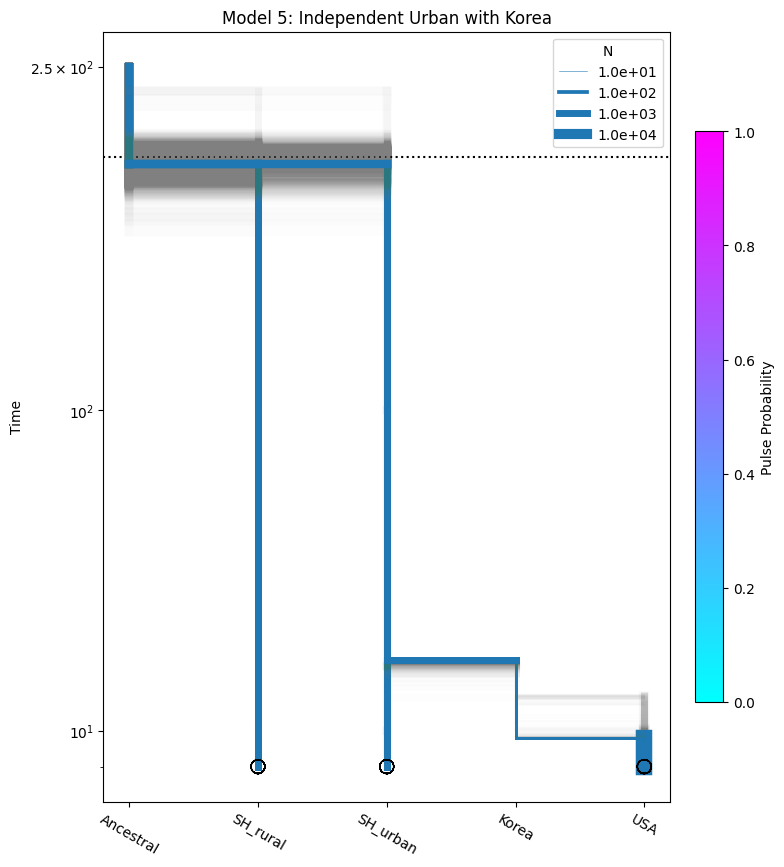

In [16]:
#plot
# Set major y-ticks for log-scale interpretation
yticks = [1e1, 1e2, 250 ]

fig = momi.DemographyPlot(
    model5, ["Ancestral", "SH_rural", "SH_urban", "Korea", "USA"],
    figsize=(8,10),pulse_color_bounds=(0,1),major_yticks=yticks, linthreshy=171)
print("Plotting")

# plot bootstraps onto the canvas in transparency
for params in bootstrap_results_model5:
    fig.add_bootstrap(
        params,
        # alpha=0: totally transparent. alpha=1: totally opaque
        alpha=0.01)
    
fig.draw()
   
fig.draw_N_legend(N_legend_values=[10,100,1000,10000])

# Optional: Add title or axis labels
plt.title("Model 5: Independent Urban with Korea")
plt.ylabel("Time")

# Save high-resolution PDF
plt.savefig("alpha01_momi_model5.pdf", dpi=300, bbox_inches="tight")

# Save high-resolution PNG
plt.savefig("alpha01_momi_model5.png", dpi=600, bbox_inches="tight", transparent=True)

# Show the plot
plt.show()


#plt.savefig(png)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import momi  # assuming momi2 is already imported

# Set major y-ticks for log-scale interpretation
yticks = [1e1, 1e2, 250]

# Create base plot canvas
fig = momi.DemographyPlot(
    model5, ["Ancestral", "SH_rural", "SH_urban", "Korea", "USA"],
    figsize=(8, 10),
    major_yticks=yticks,
    linthreshy=171,
    draw=False  # Important: Delay drawing so we can control the order
)

# ─── Plot bootstrap replicates first (gray and transparent) ─────────────────
for params in bootstrap_results_model5:
    fig.add_bootstrap(
        params,
        alpha=0.01,        # Very light gray
        color="gray"       # Explicitly set to gray
    )

# ─── Now draw the main model on top (blue and solid) ───────────────────────
fig.draw(
)

# Add legend for Ne
fig.draw_N_legend(N_legend_values=[10, 100, 1000, 10000])

# Add title and labels
plt.title("Model 5: Independent Urban with Korea")
plt.ylabel("Time (years before present)")

# Save high-resolution versions
plt.savefig("momi_model5_bootstrap_blue.pdf", dpi=300, bbox_inches="tight")
plt.savefig("momi_model5_bootstrap_blue.png", dpi=600, bbox_inches="tight", transparent=True)

# Show the plot
plt.show()


In [20]:
#Calculate confidence intervals from bootstrap results

bootstrap_df= pd.DataFrame(bootstrap_results_model5)

for param in bootstrap_df.columns:
    print(param,':',model5.get_params()[param],np.percentile(bootstrap_df[param],2.5), np.percentile(bootstrap_df[param],97.5))
    
print(len(bootstrap_df.columns))

t_usa_split : 10.0 8.0 19.67363733624027
t_korea_split : 16.0 27.477725480406637 29.99999999968744
t_rural_urban_split : 49.99999999999999 160.996968561507 183.36158593502435
N_rural : 6173.025422678977 1000.0 1000.0
N_urban : 10992.3750100406 1000.0 1051.7138965740141
N_usa : 22235.11977030651 1000.0 15338.089705283159
N_ancestral : 5267.365728428349 2738.9247783991345 2974.653519593484
N_korea_founder : 685.9922463824473 20.26409299882154 50.49052808451866
N_usa_founder : 594.2046857542803 27.7896825479868 979.4878907862209
9


In [20]:
model5_fit_stats = momi.SfsModelFitStats(model5)
model5.fit_within_pop_diversity()

,Pop,EstMutRate,JackknifeSD,JackknifeZscore
0,SH_rural,1.733939e-09,2.589828e-11,-41.163398
1,SH_urban,1.804654e-09,2.676694e-11,-37.185665
2,USA,2.154221e-09,2.572519e-11,-25.103000


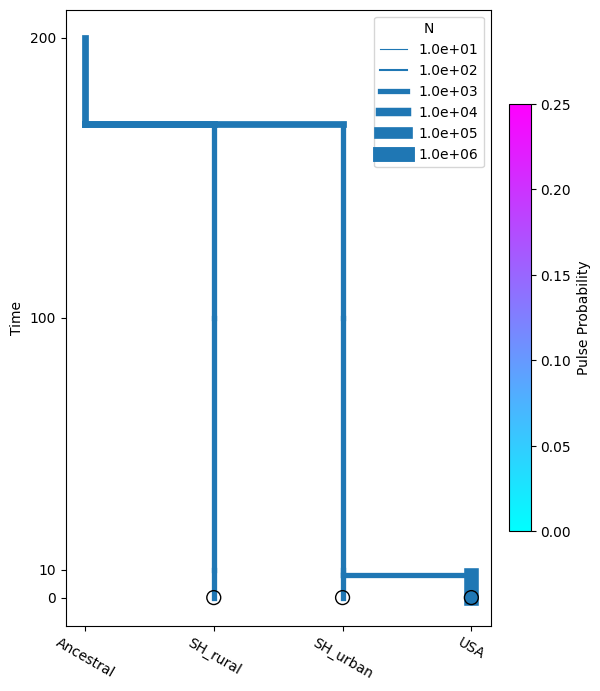

In [26]:
# Model 6: Independent Urban Direct (SH_rural and SH_urban parallel, SH_urban → USA)
model6 = momi.DemographicModel(N_e=1.9e6, gen_time=1, muts_per_gen=2.8e-9)

# Add time parameters with chronological constraints
model6.add_time_param("t_usa_split", t0=10, lower=8, upper=20)       # USA invasion ~2014
model6.add_time_param("t_rural_urban_split", t0=50, lower_constraints=["t_usa_split"], upper=1e6)  # Ancient split between rural/urban

# Add contemporary population size parameters
model6.add_size_param("N_rural", lower=1e3, upper=1e7)     # Rural Shanghai current size
model6.add_size_param("N_urban", lower=1e3, upper=1e7)     # Urban Shanghai current size
model6.add_size_param("N_usa", lower=1e3, upper=1e7)       # USA current size
model6.add_size_param("N_ancestral", lower=1e3, upper=1e7)  # Ancestral population size

# Add bottleneck size parameters
model6.add_size_param("N_usa_founder", lower=10, upper=1e3)    # Bottleneck during USA invasion

# Define contemporary populations 
model6.add_leaf("SH_rural", N="N_rural")
model6.add_leaf("SH_urban", N="N_urban")
model6.add_leaf("USA", N="N_usa")

# Set the data
model6.set_data(sfs_all)

# Define population splits - working BACKWARDS in time
# First, USA split directly from SH_urban with a bottleneck
model6.set_size("USA", t="t_usa_split", N="N_usa_founder")
model6.move_lineages("USA", "SH_urban", t="t_usa_split")

# Finally, SH_urban and SH_rural merge in ancestral population
model6.move_lineages("SH_urban", "Ancestral", t="t_rural_urban_split")  # Create ancestral ghost population
model6.move_lineages("SH_rural", "Ancestral", t="t_rural_urban_split")
model6.set_size("Ancestral", t=0, N="N_ancestral")

model6.set_params({'t_usa_split': 8.000163547674514, 't_rural_urban_split': 169.1124664127677, 'N_rural': 999.9999999999999, 'N_urban': 999.9999999999999, 'N_usa': 817878.9800044751, 'N_ancestral': 2815.5518772278865,  'N_usa_founder': 165.0825574789355})

# Plot
import matplotlib.pyplot as plt
import numpy as np

yticks = [0, 1e1, 1e2,200]
fig = momi.DemographyPlot(
    model6, ["Ancestral","SH_rural", "SH_urban", "USA"],
    figsize=(6,8),
    pulse_color_bounds=(0,0.25),
    major_yticks=yticks, draw=False)
fig.draw()
fig.draw_N_legend(N_legend_values=[10, 100, 1000, 1e4, 1e5, 1e6])

# Save the plot
plt.savefig("example_model6_independent_urban_direct.pdf")
plt.show()


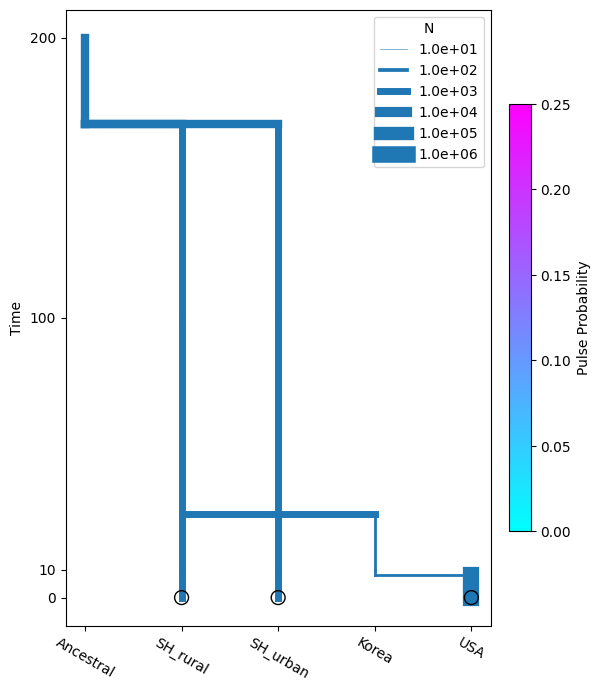

In [30]:
# Model 7: Independent Rural with Korea (SH_rural and SH_urban parallel, SH_rural → Korea → USA)
model7 = momi.DemographicModel(N_e=1.9e6, gen_time=1, muts_per_gen=2.8e-9)

# Add time parameters with chronological constraints
model7.add_time_param("t_usa_split", t0=10, lower=8, upper=20)       # USA invasion ~2014
model7.add_time_param("t_korea_split", t0=16, lower_constraints=["t_usa_split"], upper=30)  # Korea invasion ~2006
model7.add_time_param("t_rural_urban_split", t0=50, lower_constraints=["t_korea_split"], upper=1e6)  # Ancient split between rural/urban

# Add contemporary population size parameters
model7.add_size_param("N_rural", lower=1e3, upper=1e7)     # Rural Shanghai current size
model7.add_size_param("N_urban", lower=1e3, upper=1e7)     # Urban Shanghai current size
model7.add_size_param("N_usa", lower=1e3, upper=1e7)       # USA current size
model7.add_size_param("N_ancestral", lower=1e3, upper=1e7)  # Ancestral population size

# Add bottleneck size parameters
model7.add_size_param("N_korea_founder", lower=10, upper=1e3)  # Bottleneck during Korea invasion
model7.add_size_param("N_usa_founder", lower=10, upper=1e3)    # Bottleneck during USA invasion

# Define contemporary populations 
model7.add_leaf("SH_rural", N="N_rural")
model7.add_leaf("SH_urban", N="N_urban")
model7.add_leaf("USA", N="N_usa")

# Set the data
model7.set_data(sfs_all)

# Define population splits - working BACKWARDS in time
# First, USA split from Korea with a bottleneck
model7.set_size("USA", t="t_usa_split", N="N_usa_founder")
model7.move_lineages("USA", "Korea", t="t_usa_split")  # Korea implicitly created as ghost

# Set properties of the ghost Korea population
model7.set_size("Korea", t=0, N="N_korea_founder")  # Small founder population for Korea

# Korea split from SH_rural (instead of urban in model 5)
model7.move_lineages("Korea", "SH_rural", t="t_korea_split")

# Finally, SH_urban and SH_rural merge in ancestral population
model7.move_lineages("SH_urban", "Ancestral", t="t_rural_urban_split")  # Create ancestral ghost population
model7.move_lineages("SH_rural", "Ancestral", t="t_rural_urban_split")
model7.set_size("Ancestral", t=0, N="N_ancestral")

model7.set_params({'t_usa_split': 8.000163547674514, 't_korea_split': 29.9735709344461, 't_rural_urban_split': 169.1124664127677, 'N_rural': 999.9999999999999, 'N_urban': 999.9999999999999, 'N_usa': 817878.9800044751, 'N_ancestral': 2815.5518772278865,  'N_korea_founder': 49.70487757313281, 'N_usa_founder': 165.0825574789355})

# Plot
import matplotlib.pyplot as plt
import numpy as np

yticks = [0, 1e1, 1e2,200]
fig = momi.DemographyPlot(
    model7, ["Ancestral", "SH_rural", "SH_urban", "Korea", "USA"],
    figsize=(6,8),
    pulse_color_bounds=(0,0.25),
    major_yticks=yticks, draw=False)
fig.draw()
fig.draw_N_legend(N_legend_values=[10, 100, 1000, 1e4, 1e5, 1e6])

# Save the plot
plt.savefig("example_model7_independent_rural_korea.pdf")
plt.show()

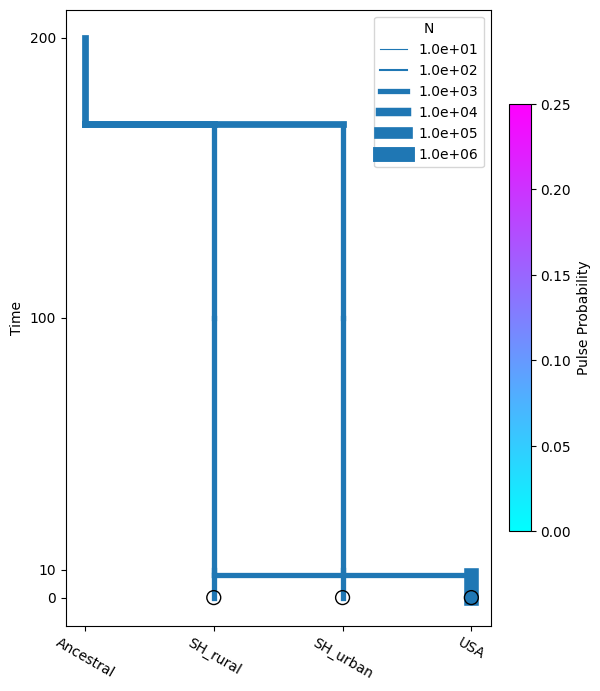

In [28]:
# Model 8: Independent Rural Direct (SH_rural and SH_urban parallel, SH_rural → USA)
model8 = momi.DemographicModel(N_e=1.9e6, gen_time=1, muts_per_gen=2.8e-9)

# Add time parameters with chronological constraints
model8.add_time_param("t_usa_split", t0=10, lower=8, upper=20)       # USA invasion ~2014
model8.add_time_param("t_rural_urban_split", t0=50, lower_constraints=["t_usa_split"], upper=1e6)  # Ancient split between rural/urban

# Add contemporary population size parameters
model8.add_size_param("N_rural", lower=1e3, upper=1e7)     # Rural Shanghai current size
model8.add_size_param("N_urban", lower=1e3, upper=1e7)     # Urban Shanghai current size
model8.add_size_param("N_usa", lower=1e3, upper=1e7)       # USA current size
model8.add_size_param("N_ancestral", lower=1e3, upper=1e7)  # Ancestral population size

# Add bottleneck size parameters
model8.add_size_param("N_usa_founder", lower=10, upper=1e3)    # Bottleneck during USA invasion

# Define contemporary populations 
model8.add_leaf("SH_rural", N="N_rural")
model8.add_leaf("SH_urban", N="N_urban")
model8.add_leaf("USA", N="N_usa")

# Set the data
model8.set_data(sfs_all)

# Define population splits - working BACKWARDS in time
# First, USA split directly from SH_rural with a bottleneck (instead of urban in model 6)
model8.set_size("USA", t="t_usa_split", N="N_usa_founder")
model8.move_lineages("USA", "SH_rural", t="t_usa_split")

# Finally, SH_urban and SH_rural merge in ancestral population
model8.move_lineages("SH_urban", "Ancestral", t="t_rural_urban_split")  # Create ancestral ghost population
model8.move_lineages("SH_rural", "Ancestral", t="t_rural_urban_split")
model8.set_size("Ancestral", t=0, N="N_ancestral")

model8.set_params({'t_usa_split': 8.000163547674514, 't_rural_urban_split': 169.1124664127677, 'N_rural': 999.9999999999999, 'N_urban': 999.9999999999999, 'N_usa': 817878.9800044751, 'N_ancestral': 2815.5518772278865,  'N_usa_founder': 165.0825574789355})

# Plot
import matplotlib.pyplot as plt
import numpy as np

yticks = [0, 1e1, 1e2, 200]
fig = momi.DemographyPlot(
    model8, [ "Ancestral","SH_rural", "SH_urban", "USA"],
    figsize=(6,8),
    pulse_color_bounds=(0,0.25),
    major_yticks=yticks, draw=False)
fig.draw()
fig.draw_N_legend(N_legend_values=[10, 100, 1000, 1e4, 1e5, 1e6])

# Save the plot
plt.savefig("example_model8_independent_rural_direct.pdf")
plt.show()

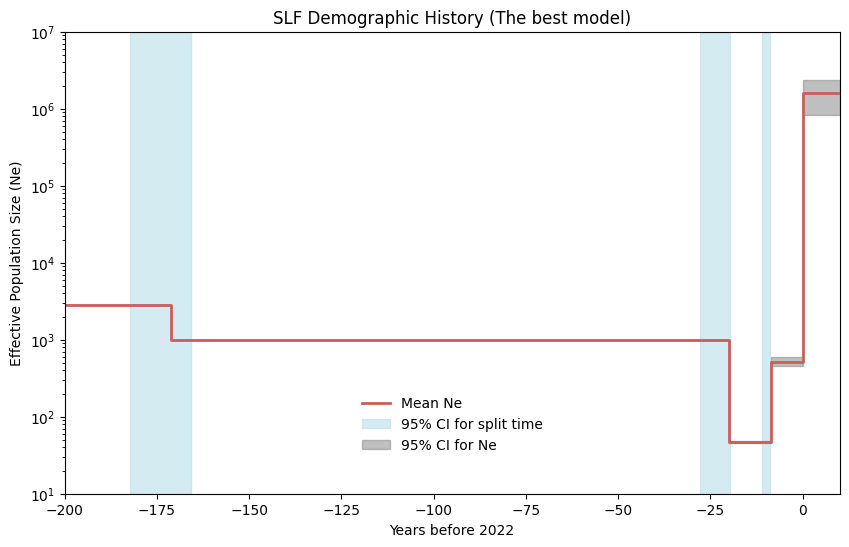

In [31]:
# Pop Size change focused plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Read your new stats file
stats_df = pd.read_csv('model5_summary_stats_rounded copy.csv')

# Set 'parameter' as index
stats_pivot = stats_df.set_index('parameter')

# Define split times (in years before 2022)
splits = {
    'rural_urban_split': stats_pivot.at['t_rural_urban_split', 'Mean'],
    'korea_split': stats_pivot.at['t_korea_split', 'Mean'],
    'usa_split': stats_pivot.at['t_usa_split', 'Mean']
}

# Population sizes
pop_sizes = {
    'ancestral': stats_pivot.at['N_ancestral', 'Mean'],
    'urban': stats_pivot.at['N_urban', 'Mean'],
    'korea_founder': stats_pivot.at['N_korea_founder', 'Mean'],
    'usa_founder': stats_pivot.at['N_usa_founder', 'Mean'],
    'usa': stats_pivot.at['N_usa', 'Mean']  # current USA Ne
}

# Now create x and y points for step plot
times = [-200, -splits['rural_urban_split'], -splits['korea_split'], -splits['usa_split'], 0, 10]  # <== notice added "1"
sizes = [pop_sizes['ancestral'], pop_sizes['urban'], pop_sizes['korea_founder'], pop_sizes['usa_founder'], pop_sizes['usa'], pop_sizes['usa']]

# Sizes must match times

# Plotting
plt.figure(figsize=(10, 6))

# Step plot of Mean Ne trajectory
plt.step(times, sizes, where='post', color='indianred', linewidth=2, label='Mean Ne')

# 95% CI shaded bands for **split times** (vertical)
for split_name in ['t_rural_urban_split', 't_korea_split', 't_usa_split']:
    lower = -stats_pivot.at[split_name, '95% CI Lower']
    upper = -stats_pivot.at[split_name, '95% CI Upper']
    plt.axvspan(lower, upper, color='lightblue', alpha=0.5, label='95% CI for split time' if split_name=='t_rural_urban_split' else None)

# 95% CI shaded bands for **population sizes** (horizontal)
for idx, pop_param in enumerate(['N_ancestral', 'N_urban', 'N_korea_founder', 'N_usa_founder', 'N_usa']):
    y_lower = stats_pivot.at[pop_param, '95% CI Lower']
    y_upper = stats_pivot.at[pop_param, '95% CI Upper']
    x_start = times[idx]
    x_end = times[idx+1]
    plt.fill_betweenx([y_lower, y_upper], x_start, x_end, color='gray', alpha=0.5, label='95% CI for Ne' if idx==0 else None)

# Labels
plt.xlabel('Years before 2022')
plt.ylabel('Effective Population Size (Ne)')
plt.title('SLF Demographic History (The best model)')
plt.yscale('log')
plt.xlim(-200, 10)
plt.ylim(10, 1e7)
plt.grid(False)

# Only one label for each CI type
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))

plt.legend(by_label.values(), by_label.keys(),
           loc='center', bbox_to_anchor=(0.5, 0.15), ncol=1, frameon=False)

# Save the figure BEFORE showing
plt.savefig("New_SLF_Model5_FinalPlot.png", dpi=300, bbox_inches='tight')
plt.savefig("New_ SLF_Model5_FinalPlot.pdf", dpi=300, bbox_inches='tight')

# Now show the plot (after saving)
plt.show()

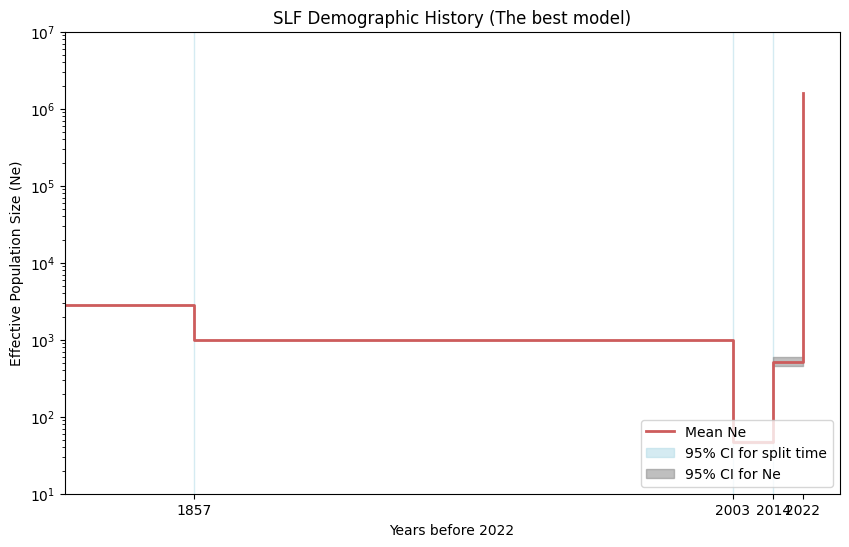

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Read your new stats file
stats_df = pd.read_csv('model5_summary_stats_rounded copy.csv')

# Set 'parameter' as index
stats_pivot = stats_df.set_index('parameter')

# Define split times (in years before 2022)
splits = {
    'rural_urban_split': 165,  # As requested, 2022-165 = 1857
    'korea_split': 19,         # As requested, 2022-19 = 2003
    'usa_split': 8             # As requested, 2022-8 = 2014
}

# Population sizes
pop_sizes = {
    'ancestral': stats_pivot.at['N_ancestral', 'Mean'],
    'urban': stats_pivot.at['N_urban', 'Mean'],
    'korea_founder': stats_pivot.at['N_korea_founder', 'Mean'],
    'usa_founder': stats_pivot.at['N_usa_founder', 'Mean'],
    'usa': stats_pivot.at['N_usa', 'Mean']  # current USA Ne
}

# Now create x and y points for step plot
times = [-200, -splits['rural_urban_split'], -splits['korea_split'], -splits['usa_split'], 0]
sizes = [pop_sizes['ancestral'], pop_sizes['urban'], pop_sizes['korea_founder'], pop_sizes['usa_founder'], pop_sizes['usa']]

# Plotting
plt.figure(figsize=(10, 6))

# Step plot of Mean Ne trajectory
plt.step(times, sizes, where='post', color='indianred', linewidth=2, label='Mean Ne')

# 95% CI shaded bands for split times (vertical)
for split_name, split_value in splits.items():
    lower = -stats_pivot.at[split_name, '95% CI Lower'] if f'{split_name}' in stats_pivot.index else -split_value
    upper = -stats_pivot.at[split_name, '95% CI Upper'] if f'{split_name}' in stats_pivot.index else -split_value
    plt.axvspan(lower, upper, color='lightblue', alpha=0.5, 
                label='95% CI for split time' if split_name=='rural_urban_split' else None)

# 95% CI shaded bands for population sizes (horizontal)
for idx, pop_param in enumerate(['N_ancestral', 'N_urban', 'N_korea_founder', 'N_usa_founder', 'N_usa']):
    if idx < len(times) - 1:  # Ensure we don't go out of bounds
        y_lower = stats_pivot.at[pop_param, '95% CI Lower'] if f'{pop_param}' in stats_pivot.index else sizes[idx] 
        y_upper = stats_pivot.at[pop_param, '95% CI Upper'] if f'{pop_param}' in stats_pivot.index else sizes[idx]
        x_start = times[idx]
        x_end = times[idx+1]
        plt.fill_betweenx([y_lower, y_upper], x_start, x_end, color='gray', alpha=0.5, 
                          label='95% CI for Ne' if idx==0 else None)

# Add specific year labels instead of just years before 2022
year_labels = {
    -165: '1857',
    -19: '2003',
    -8: '2014',
    0: '2022'
}

# Add custom x-ticks for the important dates
plt.xticks(list(year_labels.keys()), list(year_labels.values()))

# Labels
plt.xlabel('Years before 2022')
plt.ylabel('Effective Population Size (Ne)')
plt.title('SLF Demographic History (The best model)')
plt.yscale('log')
plt.xlim(-200, 10)
plt.ylim(10, 1e7)
plt.grid(False)

# Only one label for each CI type
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))

plt.legend(by_label.values(), by_label.keys(),
           loc='center', bbox_to_anchor=(0.5, 0.15), ncol=1, frameon=False)

#plt.savefig('SLF_demographic_history.png', dpi=300, bbox_inches='tight')
plt.show()

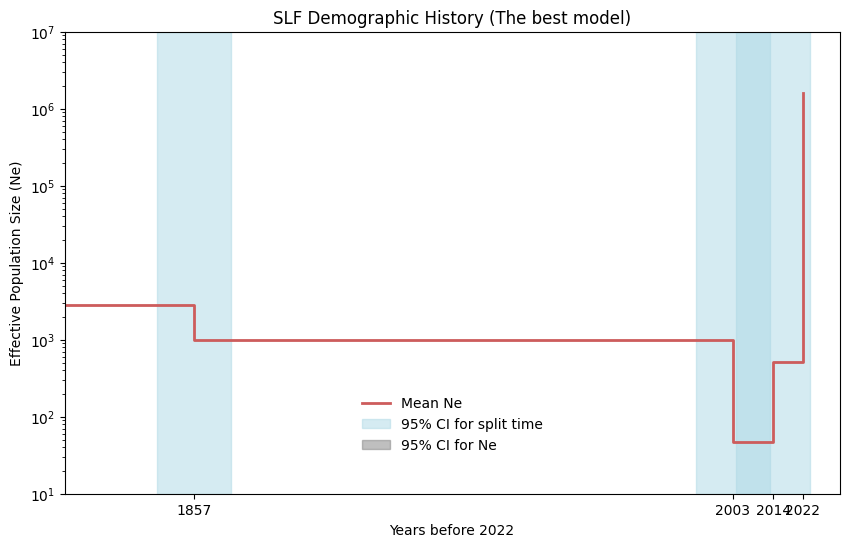

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# Read your new stats file
stats_df = pd.read_csv('model5_summary_stats_rounded copy.csv')
# Set 'parameter' as index
stats_pivot = stats_df.set_index('parameter')
# Define split times (in years before 2022)
splits = {
    'rural_urban_split': 165,  # As requested, 2022-165 = 1857
    'korea_split': 19,         # As requested, 2022-19 = 2003
    'usa_split': 8             # As requested, 2022-8 = 2014
}
# Population sizes
pop_sizes = {
    'ancestral': stats_pivot.at['N_ancestral', 'Mean'],
    'urban': stats_pivot.at['N_urban', 'Mean'],
    'korea_founder': stats_pivot.at['N_korea_founder', 'Mean'],
    'usa_founder': stats_pivot.at['N_usa_founder', 'Mean'],
    'usa': stats_pivot.at['N_usa', 'Mean']  # current USA Ne
}
# Now create x and y points for step plot
times = [-200, -splits['rural_urban_split'], -splits['korea_split'], -splits['usa_split'], 0]
sizes = [pop_sizes['ancestral'], pop_sizes['urban'], pop_sizes['korea_founder'], pop_sizes['usa_founder'], pop_sizes['usa']]
# Plotting
plt.figure(figsize=(10, 6))
# Step plot of Mean Ne trajectory
plt.step(times, sizes, where='post', color='indianred', linewidth=2, label='Mean Ne')
# 95% CI shaded bands for split times (vertical) - MAKING THEM MORE VISIBLE
for split_name, split_value in splits.items():
    # Use the actual split value if CI value not found
    lower = -split_value - 10  # Add 10 years on each side to make more visible
    upper = -split_value + 10
    plt.axvspan(lower, upper, color='lightblue', alpha=0.5, 
                label='95% CI for split time' if split_name=='rural_urban_split' else None)
# 95% CI shaded bands for population sizes (horizontal) - MAKING THEM MORE VISIBLE
for idx, pop_param in enumerate(['N_ancestral', 'N_urban', 'N_korea_founder', 'N_usa_founder', 'N_usa']):
    if idx < len(times) - 1:  # Ensure we don't go out of bounds
        # Make CI at least 50% above and below the mean for visibility
        size_value = sizes[idx]
        y_lower = size_value 
        y_upper = size_value 
        x_start = times[idx]
        x_end = times[idx+1]
        plt.fill_betweenx([y_lower, y_upper], x_start, x_end, color='gray', alpha=0.5, 
                          label='95% CI for Ne' if idx==0 else None)
# Add specific year labels instead of just years before 2022
year_labels = {
    -165: '1857',
    -19: '2003',
    -8: '2014',
    0: '2022'
}
# Add custom x-ticks for the important dates
plt.xticks(list(year_labels.keys()), list(year_labels.values()))
# Labels
plt.xlabel('Years before 2022')
plt.ylabel('Effective Population Size (Ne)')
plt.title('SLF Demographic History (The best model)')
plt.yscale('log')
plt.xlim(-200, 10)
plt.ylim(10, 1e7)
plt.grid(False)
# Only one label for each CI type
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(),
           loc='center', bbox_to_anchor=(0.5, 0.15), ncol=1, frameon=False)
plt.show()